# Business-as-Usual – Kết quả kỳ vọng nếu điều kiện và xu hướng hiện tại tiếp tục · BI10 Round 3

> **Bước 4/5 · Business-as-Usual – quý tới đạt bao nhiêu nếu giữ nguyên** · bản đồ toàn bài: `README.md`
>
> **Câu hỏi của đề được trả lời ở đây:**
> - **Business-as-Usual** – what the shop is expected to achieve if current conditions and trends continue
> - How future trajectory should be assessed
> - Reliability and uncertainty of the BAU estimate (backtest, P10–P90, Shapley)
>
> **Đầu vào → đầu ra:** `data_clean/` → `output/bau_2026Q4.csv` (đầu vào của `05_Potential_Prioritization.ipynb`)
>
> **Đọc tiếp:** `05_Potential_Prioritization.ipynb`

**Câu hỏi của đề:** *Kịch bản duy trì hoạt động như hiện tại (Business-as-Usual): kết quả cửa hàng được kỳ vọng đạt được nếu các điều kiện và xu hướng hiện tại tiếp tục.*

Notebook đi theo 5 bước:

| Bước | Nội dung |
|---|---|
| 1 | Chốt phạm vi và giả định |
| 1b | Bằng chứng: đà tăng/giảm kéo dài bao nhiêu, shop trưởng thành ra sao |
| 2 | Baseline và các mô hình ứng viên |
| 3 | Backtest theo thời gian, chọn phương pháp |
| 4 | Dự báo điểm + khoảng bất định; kịch bản độ nhạy trình bày riêng |
| 5 | Giải thích từng shop: BAU tăng/giảm vì đâu |
| 5a | **Từ số HĐ sang số tiền**: dự báo khoản vay bình quân, có backtest |
| 5b | **Mở hộp đen mô hình**: mỗi nhóm yếu tố đóng góp bao nhiêu HĐ vào BAU (giá trị Shapley, cùng nguyên lý SHAP) |
| 5c | Đọc BAU theo yếu tố kinh doanh: hồ sơ × chuyển đổi × khoản vay |

> **Đọc nhanh cho người không chuyên dữ liệu:**
> - BAU = "nếu shop cứ làm như hiện tại thì quý tới được bao nhiêu". Mô hình **dự báo số HĐ**, rồi **nhân với khoản vay bình quân** để ra số tiền (Bước 5a).
> - Con số chính đến từ trung bình 3 cách dự báo (M12). Bước 5b cho biết mỗi yếu tố (kết quả gần đây, tuổi shop, loại shop…) **cộng hoặc trừ bao nhiêu HĐ**, nên không phải tin mô hình một cách mù quáng.

Chỉ dùng dữ liệu Round 3. Kết quả từng shop được lưu ở `output/bau_2026Q4.csv`; `05_Potential_Prioritization.ipynb` sẽ dùng file này.

## Bước 1 · Phạm vi và giả định

| | Định nghĩa |
|---|---|
| **Giả định BAU** | **Không bổ sung biện pháp cải thiện mới**: không thêm nhân sự, không chạy chiến dịch, không đổi chính sách. Các yếu tố đầu vào tiếp diễn theo **mức hoặc xu hướng hợp lý** tại thời điểm dự báo. Shop mới tiếp tục trưởng thành, shop có thể ngừng hoạt động: cả hai **thuộc BAU** |
| **Mốc dự báo** | cuối quý T (hiện tại: **cuối Q3/2026**) |
| **Shop được dự báo** | shop vật lý **đang mở tại mốc dự báo**, kể cả shop mới mở và shop sau này đóng cửa |
| **Chỉ tiêu** | **HĐ thành công bình quân/tháng trong quý T+1** = tổng HĐ của quý ÷ 3. Shop đóng giữa quý vẫn được tính các HĐ phát sinh trước khi đóng, các tháng sau đóng tính là 0 |
| **Cách đếm HĐ** | HĐ đã ký, không bị huỷ sau ký; đếm theo **tháng nộp hồ sơ**; tính cho shop nơi xử lý hồ sơ (cùng cách đếm với phần Current Actual) |
| **Chỉ tiêu phụ** | giá trị khoản vay đã ký = HĐ dự báo × khoản vay bình quân của shop (co về mức phân khúc) |
| **Đơn vị sai số** | MAE tính bằng **HĐ/tháng** (bình quân trong quý) |
| **Báo cáo cho Ban quản lý** | **tổng HĐ ký trong quý** (= bình quân/tháng × 3), **giá trị khoản vay đã ký**, **chất lượng dự kiến** (số HĐ có thể trễ kỳ đầu = HĐ dự báo × tỷ lệ trễ kỳ đầu của shop) |

### Các nhóm yếu tố ảnh hưởng BAU và cách dùng với dữ liệu Round 3

| Nhóm yếu tố | Chỉ số đầu vào | Có trong dữ liệu? | Dùng thế nào |
|---|---|---|---|
| **Kết quả gần đây** | HĐ/tháng quý hiện tại, quý trước, tháng gần nhất, xu hướng 6 tháng | ✅ | đặc trưng chính của mọi mô hình |
| **Nhu cầu đầu vào** | hồ sơ/tháng (quý hiện tại, quý trước) | ✅ | **mô hình theo yếu tố**: dự báo hồ sơ quý tới |
| **Khả năng chuyển đổi** | tỷ lệ hồ sơ thành HĐ (2 quý gần nhất, co về phân khúc) | ✅ (không tách được duyệt và hoàn tất) | **mô hình theo yếu tố**: hồ sơ × tỷ lệ chuyển đổi |
| **Giá trị & cơ cấu sản phẩm** | khoản vay bình quân của shop, tỷ trọng sản phẩm | ✅ | quy đổi HĐ sang giá trị khoản vay |
| **Năng lực phục vụ** | nhân sự thực tế, ngày công | ❌ chỉ có phân công SA, không có giờ công | không đưa vào; ghi là giới hạn |
| **Tuổi & trạng thái shop** | tháng tuổi, số tháng đã mở trong quý, tháng không phát sinh | ✅ | đặc trưng mô hình; xác suất còn mở |
| **Đối tác & địa bàn** | loại đối tác, quy mô, phân khúc | ✅ | đặc trưng mô hình dùng chung |
| **Mùa vụ & môi trường** | Tết, iPhone, siêu sale, số ngày | ✅ nhưng mỗi sự kiện mới 1 lần | đã kiểm định ở Bước 3c: không cải thiện → chỉ dùng làm **kịch bản** |
| **Chính sách & rủi ro** | tỷ lệ bị từ chối, trễ kỳ đầu (FPD) | ✅ | tỷ lệ chuyển đổi đã phản ánh chính sách hiện hành; FPD dùng để ước tính chất lượng BAU |

Lưu ý: giữ nguyên chính sách duyệt **không đảm bảo** tỷ lệ chuyển đổi giữ nguyên, vì tỷ lệ này còn phụ thuộc chất lượng khách nộp hồ sơ. Vì vậy tỷ lệ chuyển đổi được lấy theo **2 quý gần nhất** và co về mức phân khúc, không cố định một con số.

In [1]:
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick, pathlib, warnings
import seaborn as sns
RDYLBU = sns.color_palette('RdYlBu', 11).as_hex()       # bảng màu chung của mọi biểu đồ
from scipy.stats import spearmanr
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
CLEAN = pathlib.Path('data_clean'); OUT = pathlib.Path('output'); OUT.mkdir(exist_ok=True)
SURF, TXT, TXT2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
C1, C2, C3, C4, C5 = '#416aaf', '#ea5739', '#8ec2dc', '#fdbf71', '#f98e52'
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': GRID, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6,
                     'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlesize': 10.5, 'axes.titlelocation': 'left',
                     'font.size': 9, 'text.color': TXT, 'axes.labelcolor': TXT2, 'xtick.color': TXT2, 'ytick.color': TXT2, 'legend.frameon': False})
con = duckdb.connect(); con.sql("SET preserve_insertion_order=false")
rd = lambda t: f"read_csv('{(CLEAN / (t + '.csv')).as_posix()}', sample_size=200000)"

shops = con.sql(f'''SELECT skp_salesroom, salesroom_model model, salesroom_category category,
        CASE WHEN salesroom_product IN ('CD','TW','NS') THEN salesroom_product ELSE 'NS' END line,
        coalesce(seller_type, 'Stone Shop') seller_type, salesroom_area area,
        date_trunc('month', salesroom_start)::DATE m_open, date_trunc('month', salesroom_end)::DATE m_close
    FROM {rd('salesroom')} WHERE salesroom_category <> 'Virtual' ''').df()
ok = con.sql(f'''SELECT skp_salesroom, date_trunc('month', date_apply)::DATE m, count(*) n,
        sum(loan_amount_eff) FILTER (WHERE product <> 'CC') val, count(*) FILTER (WHERE product <> 'CC') n_val
    FROM {rd('contract')} WHERE is_signed AND name_status <> 'Cancelled'
      AND skp_salesroom IN (SELECT skp_salesroom FROM {rd('salesroom')}) GROUP BY 1, 2''').df()
MONTHS = pd.date_range('2025-01-01', '2026-09-01', freq='MS')
# bảng shop × tháng: số HĐ, có mở trong tháng không
Y = ok.pivot_table(index='skp_salesroom', columns='m', values='n', aggfunc='sum').reindex(index=shops.skp_salesroom, columns=MONTHS).fillna(0)
OPEN = pd.DataFrame({m: ((shops.m_open <= m) & (shops.m_close.isna() | (shops.m_close >= m))).values for m in MONTHS},
                    index=shops.skp_salesroom)
Y = Y.where(OPEN, 0)
shops = shops.set_index('skp_salesroom')
shops['seg'] = shops.line + ' · ' + shops.model
qidx = lambda m: (m.year - 2025) * 4 + (m.month - 1) // 3          # 0 = 2025Q1
QN = lambda q: f'{2025 + q // 4}Q{q % 4 + 1}'
QM = {q: [m for m in MONTHS if qidx(m) == q] for q in range(7)}
print(f"{len(shops):,} shop vật lý · {len(MONTHS)} tháng · HĐ thành công: {Y.values.sum():,.0f}")
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=[RDYLBU[i] for i in (10, 1, 8, 3, 0, 9, 2, 7)])   # bảng màu seaborn RdYlBu
plt.rcParams['image.cmap'] = 'RdYlBu'


14,126 shop vật lý · 21 tháng · HĐ thành công: 425,355


**Nhãn biểu đồ tiếng Anh:** cell dưới dịch mọi chữ trên biểu đồ (tiêu đề, trục, chú thích, nhãn) sang tiếng Anh ngay trước khi hiện. Bảng và câu in ra giữ tiếng Việt.

In [2]:
# --- Nhãn biểu đồ bằng tiếng Anh: mọi chữ trên biểu đồ được dịch ngay trước khi hiện; bảng và câu in ra giữ tiếng Việt ---
import re as _re
import matplotlib.pyplot as plt
_EN = {
 # ===== 03 Current Actual =====
 '% HĐ': '% contracts', '% HĐ CD/TW trễ kỳ 1–4': '% CD/TW contracts late in instalments 1–4', '% HĐ thành công': '% successful contracts',
 '% HĐ thành công theo kênh (quý nộp)': '% successful contracts by channel (application quarter)', '% HĐ trễ kỳ 1–4 theo vùng': '% contracts late in instalments 1–4 by region',
 '% giá trị': '% value', '% giá trị khoản vay đã ký': '% signed loan value', '% giá trị khoản vay đã ký theo kênh': '% signed loan value by channel',
 '% khách CD/TW lần đầu tại shop vay thêm CL/CC/CW trong 12 tháng, theo nơi vay': '% first-time CD/TW shop customers taking CL/CC/CW within 12 months, by where they borrow',
 '% shop (xếp theo năng suất giảm dần)': '% shops (ranked by productivity, descending)', '% shop của mỗi lứa (tháng mở) hiện đã đóng cửa': '% of each opening cohort now closed',
 '% shop đang hoạt động theo giai đoạn': '% active shops by lifecycle stage', '% shop đang mở có phát sinh HĐ ký trong tháng': '% open shops with ≥ 1 signed contract in the month',
 '% shop đã đóng cửa theo vùng': '% shops closed by region', '% số HĐ ký': '% signed contracts', '% số shop': '% shops',
 '1. Mới mở (0–2 tháng)': '1. New (0–2 months)', '2. Tăng tốc (3–5 tháng)': '2. Ramp-up (3–5 months)', '3. Ổn định (≥ 6 tháng)': '3. Mature (≥ 6 months)',
 '100 hồ sơ nộp Q3/2026 đi về đâu (theo phân khúc)': 'Where 100 applications in Q3/2026 end up (by segment)',
 '25% shop bán cao nhất': 'Top 25% shops by sales', '25% shop bán thấp nhất (có HĐ)': 'Bottom 25% shops by sales (with contracts)',
 'Bị từ chối': 'Rejected', 'Chiến dịch (SOB, GMA_SCORING)': 'Campaign (SOB, GMA_SCORING)', 'Chưa từng có HĐ': 'Never had a contract', 'Cùng shop': 'Same shop',
 'Cơ cấu HĐ thành công theo sản phẩm': 'Successful contracts by product', 'Cơ cấu sản phẩm theo kênh (HĐ thành công, Q3/2026)': 'Product mix by channel (successful contracts, Q3/2026)',
 'Dòng hàng chính': 'Main product line', 'FOLLOW_UP: lead → HĐ ký': 'FOLLOW_UP: lead → signed contract', 'FPD của shop: trung vị → P90 theo phân khúc': 'Shop FPD: median → P90 by segment',
 'Giá trị / shop / tháng (triệu đ)': 'Value / shop / month (VND m)', 'Giá trị / shop / tháng theo tuổi shop (triệu đ)': 'Value / shop / month by shop age (VND m)',
 'Giá trị khoản vay / shop / tháng': 'Loan value / shop / month', 'Giá trị khoản vay đã ký (VND)': 'Signed loan value (VND)', 'Giá trị khoản vay đã ký / tháng': 'Signed loan value / month',
 'Giá trị khoản vay đã ký mỗi tháng (loan_amount_eff)': 'Signed loan value per month (loan_amount_eff)', 'Huỷ': 'Cancelled',
 'HĐ / shop / tháng': 'Contracts / shop / month', 'HĐ / tháng': 'Contracts / month', 'HĐ ký / shop / tháng': 'Signed contracts / shop / month',
 'HĐ ký / shop / tháng (shop ≥ 1 tháng tuổi)': 'Signed contracts / shop / month (shops ≥ 1 month old)',
 'HĐ ký / shop theo tuổi shop – theo lứa mở': 'Signed contracts / shop by shop age – by opening cohort',
 'HĐ ký / shop theo tuổi shop – theo phân khúc (CD · Aldi xem bảng)': 'Signed contracts / shop by shop age – by segment (CD · Aldi: see table)',
 'HĐ ký / tháng Q3/2026 (thang log)': 'Signed contracts / month Q3/2026 (log scale)', 'HĐ ký 03/2025 – 05/2026 (đủ tuổi)': 'Contracts signed 03/2025 – 05/2026 (matured)',
 'HĐ ký mỗi tháng theo giai đoạn vòng đời của shop': 'Signed contracts per month by shop lifecycle stage', 'HĐ thành công / tháng (Q3/2026)': 'Successful contracts / month (Q3/2026)',
 'HĐ thành công / tháng của từng shop, theo phân khúc chi tiết': 'Successful contracts / month per shop, by peer group', 'HĐ đã ký': 'Signed contracts',
 'HĐ đã ký / shop': 'Signed contracts / shop', 'HĐ đã ký / tháng (Q3/2026)': 'Signed contracts / month (Q3/2026)', 'HĐ đã ký mỗi tháng': 'Signed contracts per month',
 'Hồ sơ / tháng': 'Applications / month', 'Instant (trong phiên bán)': 'Instant (during the sale)', 'Khoản vay BQ': 'Avg loan size',
 'Khoản vay bình quân (triệu đ)': 'Avg loan size (VND m)', 'Khoản vay bình quân của shop (trung vị, triệu đ, không tính CC)': 'Avg loan size per shop (median, VND m, excl. CC)',
 'Khoản vay bình quân theo tuổi shop (triệu đ)': 'Avg loan size by shop age (VND m)', 'Khoản vay trung vị (VND)': 'Median loan size (VND)', 'Khác': 'Other',
 'Khách huỷ': 'Customer cancelled', 'Khách hàng có HĐ ký (Q3/2026)': 'Customers with signed contracts (Q3/2026)', 'Khách mới / shop / tháng (Q3/2026)': 'New customers / shop / month (Q3/2026)',
 'Khách theo sản phẩm đã dùng': 'Customers by products used', 'Không rõ': 'Unknown', 'Kết quả xử lý lead': 'Lead outcome',
 'Kỳ 1 (FPD)': 'Instalment 1 (FPD)', 'Kỳ 2': 'Instalment 2', 'Kỳ 3': 'Instalment 3', 'Kỳ 4': 'Instalment 4',
 'Lead / shop / tháng (bỏ RTDM), theo loại lead': 'Leads / shop / month (excl. RTDM), by lead type', 'Lead → HĐ ký (30 ngày)': 'Lead → signed contract (30 days)',
 'Lead → HĐ ký (30 ngày), theo loại lead': 'Lead → signed contract (30 days), by lead type', 'Loại đại lý': 'Partner type',
 'Mô hình (Aldi = NV shop tự làm HĐ)': 'Model (Aldi = partner staff handle applications)', 'Mỗi chấm = 1 shop (kích thước = số HĐ); đường chấm = trung vị phân khúc': 'Each dot = 1 shop (size = # contracts); dotted lines = segment median',
 'Mỗi shop Non-Aldi có bao nhiêu SA quy đổi?': 'How many SA FTE does each Non-Aldi shop have?', 'Mới mở (từ 07/2026)': 'New (opened from 07/2026)',
 'Mở 2025-H1': 'Opened 2025-H1', 'Mở 2025-H2': 'Opened 2025-H2', 'Mở 2026 (01–09)': 'Opened 2026 (01–09)', 'Mở mới': 'Opened', 'Mở ròng': 'Net openings',
 'Ngừng phát sinh': 'Stopped selling', 'Nhiều SA hơn có nhiều HĐ hơn không?': 'Do more SAs mean more contracts?', 'Nhiều sản phẩm': 'Multiple products',
 'Nhóm hàng (số HĐ)': 'Goods group (# contracts)', 'Năng suất vs tỷ lệ trễ hạn (shop ≥ 30 HĐ CD/TW đủ tuổi)': 'Productivity vs delinquency (shops with ≥ 30 matured CD/TW contracts)',
 'ORIGINATION: lead → hồ sơ / HĐ ký': 'ORIGINATION: lead → application / signed contract', 'POS ngoài danh sách shop': 'POS outside shop master',
 'Phân bổ trạng thái hồ sơ theo sản phẩm': 'Application status by product', 'Q3/2026 · không phải tỷ lệ duyệt': 'Q3/2026 · not the approval rate', 'Quy mô shop': 'Shop size',
 'SA quy đổi': 'SA FTE', 'SA quy đổi của shop': 'Shop SA FTE', 'Shop bán nhiều có rủi ro cao hơn không? (mỗi chấm = 1 shop)': 'Do high-selling shops carry more risk? (each dot = 1 shop)',
 'Shop bán tốt khác shop bán kém chủ yếu ở số hồ sơ, không ở tỷ lệ không bị từ chối/hoàn tất': 'Strong and weak shops differ mainly in applications, not in approval/completion rates',
 'Shop mới – Current Actual (Q3/2026)': 'New shops – Current Actual (Q3/2026)', 'Shop mở mới, đóng cửa và mở ròng mỗi tháng': 'Shop openings, closures and net openings per month',
 'Shop trung vị (trưởng thành)': 'Median shop (mature)', 'Shop vật lý': 'Physical shop', 'Shop vật lý khác': 'Other physical shop', 'Shop vật lý ≥ 3 tháng tuổi': 'Physical shops ≥ 3 months old',
 'Shop đang hoạt động': 'Active shops', 'Shop đang hoạt động (09/2026)': 'Active shops (09/2026)', 'Shop ảo (Virtual)': 'Virtual shop',
 'Số hồ sơ vay mỗi tháng (theo sản phẩm)': 'Loan applications per month (by product)', 'Số hợp đồng ĐÃ KÝ mỗi tháng (theo sản phẩm)': 'SIGNED contracts per month (by product)',
 'Số hợp đồng đã ký trên mỗi khách': 'Signed contracts per customer', 'Số kỳ trả góp trung vị': 'Median number of instalments', 'Số shop mở mới mỗi tháng, theo dòng hàng': 'New shops per month, by product line',
 'Số shop theo trạng thái hoạt động thực tế (cuối Q3/2026)': 'Shops by actual activity status (end of Q3/2026)', 'Số shop theo vùng': 'Shops by region', 'Số shop đang hoạt động': 'Active shops',
 'TB trượt 3 tháng': '3-month moving average', 'Thay đổi HĐ ký / tháng so với quý trước, tách theo nguồn': 'Change in signed contracts / month vs previous quarter, by source',
 'Thành HĐ': 'Signed', 'Thời gian nộp → ký của shop: dải P25–P75, chấm = trung vị, vạch = P90': 'Shop application → signing time: band P25–P75, dot = median, tick = P90',
 'Thời gian từ nộp hồ sơ đến ký (HĐ ký)': 'Time from application to signing (signed contracts)', 'Thời gian xử lý': 'Processing time', 'Top 15 tỉnh theo số shop': 'Top 15 provinces by shop count',
 'Top hãng sản xuất (số HĐ)': 'Top manufacturers (# contracts)', 'Toàn bộ': 'All', 'Trạng thái': 'Status', 'Trả trước trung vị (% giá hàng)': 'Median down payment (% of price)',
 'Trễ hạn kỳ 1–4 theo sản phẩm': 'Late in instalments 1–4 by product', 'Trễ hạn kỳ 1–4 theo vùng': 'Late in instalments 1–4 by region', 'Trễ kỳ đầu (FPD) theo tháng ký': 'First-payment default (FPD) by signing month',
 'Trễ ngay kỳ đầu (FPD) theo sản phẩm': 'First-payment default (FPD) by product', 'Trễ ≥ 1 kỳ trong kỳ 1–4 theo tháng ký': 'Late in ≥ 1 of instalments 1–4 by signing month',
 'Tăng trưởng HĐ ký so với quý trước (QoQ)': 'Signed contracts growth vs previous quarter (QoQ)', 'Tăng trưởng HĐ ký so với tháng trước (MoM)': 'Signed contracts growth vs previous month (MoM)',
 'Từ chối': 'Rejected', 'Tỷ lệ DEAL theo nguồn lead': 'DEAL rate by lead source', 'Tỷ lệ DEAL theo sản phẩm': 'DEAL rate by product', 'Tỷ lệ bị từ chối': 'Rejection rate',
 'Tỷ lệ bị từ chối (theo tháng nộp hồ sơ)': 'Rejection rate (by application month)', 'Tỷ lệ duyệt (khoảng cận dưới – cận trên)': 'Approval rate (lower – upper bound)', 'Tỷ lệ hoàn tất': 'Completion rate',
 'Tỷ lệ huỷ': 'Cancellation rate', 'Tỷ lệ huỷ (theo tháng nộp hồ sơ)': 'Cancellation rate (by application month)', 'Tỷ lệ không bị từ chối': 'Non-rejection rate', 'Tỷ lệ ký': 'Signing rate',
 'Tỷ lệ ký (HĐ ký / hồ sơ)': 'Signing rate (signed / applications)', 'Tỷ lệ ký (HĐ thành công / hồ sơ)': 'Signing rate (successful contracts / applications)',
 'Tỷ lệ ký (HĐ đã ký / hồ sơ) – toàn bộ sản phẩm': 'Signing rate (signed / applications) – all products', 'Tỷ lệ ký (theo tháng nộp hồ sơ)': 'Signing rate (by application month)',
 'Tỷ lệ ký và khoảng tỷ lệ duyệt theo tháng nộp': 'Signing rate and approval-rate range by application month', 'Tỷ lệ ra HĐ ký theo nguồn lead': 'Lead → signed contract rate by lead source',
 'Tỷ lệ trễ hạn kỳ 1–4': 'Delinquency rate, instalments 1–4', 'Tỷ lệ trễ hạn kỳ 1–4 theo tháng ký (vintage)': 'Delinquency rate, instalments 1–4, by signing month (vintage)',
 'Tỷ lệ trễ hạn theo từng kỳ, theo tháng ký': 'Delinquency rate per instalment, by signing month', 'Tỷ trọng theo loại đối tác': 'Share by partner type',
 'Tỷ trọng theo mô hình cửa hàng': 'Share by shop model', 'Tỷ trọng theo vùng': 'Share by region', 'Xoá nợ (written off)': 'Written off',
 'bội số so với trung vị phân khúc (thang log)': 'multiple of segment median (log scale)', 'hiệu ứng mạng lưới (thêm shop)': 'network effect (more shops)', 'hiệu ứng năng suất': 'productivity effect',
 'lead giao 06–08/2026, có trọng số': 'leads assigned 06–08/2026, weighted', 'loan_amount_eff; chưa xác minh giải ngân thực tế': 'loan_amount_eff; actual disbursement not verified',
 'phút': 'minutes', 'phút (trung vị của từng shop)': 'minutes (median per shop)', 'ra HĐ ký (sign)': 'signed contract (sign)', 'tháng thứ k sau khi mở': 'month k after opening',
 'trung bình mỗi shop đang hoạt động': 'average per active shop', 'trung vị': 'median', 'tạo hồ sơ (apply)': 'application created (apply)',
 'Đang bán đều / tăng': 'Selling steadily / growing', 'Đang suy giảm': 'Declining', 'Đang xử lý': 'In process', 'Đã ký – bình thường': 'Signed – normal', 'Đã đóng': 'Closed',
 'Đóng cửa (âm)': 'Closed (negative)', 'Đường tập trung doanh số (Pareto)': 'Sales concentration curve (Pareto)',
 # ===== 05 =====
 'Chốt kém': 'Weak closing', 'Shop đang hoạt động: từ BAU tới Ceiling (HĐ ký / tháng)': 'Active shops: from BAU to Ceiling (signed contracts / month)',
 'Thiếu khách': 'Too few customers', 'Thị trường chưa chạm': 'Untapped market', 'Thiếu sản phẩm': 'Missing products', 'Thiếu SA': 'No SA assigned',
 # ===== 01 EDA =====
 '% HĐ có cờ trễ ≥ 1 kỳ, theo trạng thái': '% contracts with ≥ 1 late flag, by status', '% HĐ đã ký có cờ trễ, theo kỳ': '% signed contracts with a late flag, by instalment',
 '% credit_amount = 0 – theo trạng thái': '% credit_amount = 0 – by status', '% dòng khớp': '% rows matched', '% giá trị = 0': '% values = 0',
 '% hợp đồng (shop trong phạm vi) có nhân khẩu học Round 2 – theo tháng nộp hồ sơ: 01/2025 gần 100%, các tháng sau ~6%': '% contracts (in-scope shops) with Round 2 demographics – by application month: 01/2025 ~100%, later months ~6%',
 '% hợp đồng có credit_amount = 0 – theo sản phẩm': '% contracts with credit_amount = 0 – by product', '% khóa (giá trị khác nhau) khớp': '% keys (distinct values) matched',
 '% link có giờ giao lead SAU date_apply': '% links with lead assigned AFTER date_apply', '% link có giờ giao lead SAU date_sign': '% links with lead assigned AFTER date_sign',
 '% null theo SẢN PHẨM (contract)': '% null by PRODUCT (contract)', '% null theo TRẠNG THÁI (contract)': '% null by STATUS (contract)',
 '% null thật và null trá hình (XNA / -1 / 3000-01-01 / rỗng)\n– chỉ hiện các cột có thiếu': '% true nulls and disguised nulls (XNA / -1 / 3000-01-01 / empty)\n– only columns with missing values',
 '% nằm ngoài ngưỡng IQR': '% outside IQR fences', '% nữ': '% female', '% shop khác tỉnh với đại lý': '% shops in a different province from their partner',
 '% shop khác vùng với đại lý': '% shops in a different region from their partner', '% số dòng': '% rows', '% trá hình': '% disguised',
 '% trễ kỳ 1 theo tháng ký (vintage) – các tháng gần cuối chưa đủ thời gian quan sát': '% late on instalment 1 by signing month (vintage) – latest months not yet observable',
 '% ĐH trở lên': '% university or higher', '% ở TP.HCM': '% in HCMC', '0 (đạt)': '0 (pass)', '<18 (bất thường)': '<18 (abnormal)', '>80 (bất thường)': '>80 (abnormal)',
 'Bảng leads (có trọng số sample_weight; vạch đen = % số dòng thô)': 'Table leads (weighted by sample_weight; black tick = % raw rows)',
 'Dòng thừa theo khóa chính (thang log)': 'Extra rows by primary key (log scale)', 'Dòng trùng toàn bộ (thang log)': 'Fully duplicated rows (log scale)',
 'Hợp đồng nằm ở shop trong / ngoài phạm vi': 'Contracts at in-scope / out-of-scope shops', 'Hợp đồng theo tháng nộp hồ sơ (date_apply), chia theo sản phẩm': 'Contracts by application month (date_apply), by product',
 'Khách ở cùng tỉnh với shop?': 'Do customers live in the shop\'s province?', 'Nhóm tuổi (tính đến 05/06/2025)': 'Age group (as of 05/06/2025)', 'Null trá hình': 'Disguised null',
 'Round 2 – biến nhân khẩu học dạng phân loại': 'Round 2 – categorical demographic variables', 'Round 2 – hồ sơ nhân khẩu học: % null / trá hình': 'Round 2 – demographic profile: % null / disguised',
 'Round 2 – top 15 tỉnh nơi ở của khách (địa giới cũ)': 'Round 2 – top 15 customer home provinces (old boundaries)', 'Shop khác địa bàn với đại lý sở hữu': 'Shops located away from their owning partner',
 'Shop mở mới theo tháng (SALESROOM_START) – salesroom chỉ chứa shop mở từ 01/2025': 'New shops by month (SALESROOM_START) – salesroom only contains shops opened from 01/2025',
 'Số cột': 'Columns', 'Số dòng mỗi bảng (thang log)': 'Rows per table (log scale)', 'Số dòng vi phạm từng kiểm tra logic (thang log; nhãn xanh lá = đạt)': 'Rows violating each logic check (log scale; green label = pass)',
 'Số shop / đại lý (trục y log)': 'Shops per partner (log y-axis)', 'Thu nhập trung vị (tr)': 'Median income (VND m)',
 'Top 10 shop KHÔNG có trong salesroom (số hợp đồng) – kênh trung tâm / online': 'Top 10 shops NOT in salesroom (# contracts) – central / online channels',
 'Top luồng khác tỉnh: nơi ở (cũ) → tỉnh shop': 'Top cross-province flows: home (old) → shop province', 'Tuổi TB': 'Avg age', 'Tệp khách được phủ có giống tổng thể Round 2 không?': 'Is the covered customer base similar to the Round 2 population?',
 'Tỉnh shop có % khách cùng tỉnh THẤP nhất (≥ 300 HĐ)': 'Shop provinces with the LOWEST % same-province customers (≥ 300 contracts)', 'amt_billing_1st – chỉ BNPL / CC (log)': 'amt_billing_1st – BNPL / CC only (log)',
 'amt_loan_limit theo sản phẩm (log) – vùng đỏ nhạt: < 1 triệu hoặc > 1 tỷ': 'amt_loan_limit by product (log) – shaded: < VND 1m or > VND 1bn',
 'code_lead_status trong leads (thang log) – không có mã DEAL': 'code_lead_status in leads (log scale) – no DEAL code',
 'contract · Cancelled nhưng có ngày ký thật': 'contract · Cancelled but has a real signing date', 'contract · Giá ≠ trả trước + tiền vay (lệch > 1%) – chỉ CD/TW': 'contract · Price ≠ down payment + loan (gap > 1%) – CD/TW only',
 'contract · Ký sau ngày cuối dữ liệu nộp hồ sơ (30/09/2026)': 'contract · Signed after the last application date (30/09/2026)', 'contract · Ngày ký trước ngày nộp hồ sơ': 'contract · Signed before application date',
 'contract · Rejected nhưng có ngày ký thật': 'contract · Rejected but has a real signing date', 'contract · Thiếu product': 'contract · Missing product', 'contract · Thiếu skp_client': 'contract · Missing skp_client',
 'contract · Trạng thái đã ký (Active/Finished/Paid off/Written off) nhưng date_s…': 'contract · Signed status (Active/Finished/Paid off/Written off) but no date_sign',
 'contract · Trả trước > giá món hàng': 'contract · Down payment > price', 'credit_amount > 0 theo sản phẩm (log)': 'credit_amount > 0 by product (log)',
 'có trọng số (sum sample_weight)': 'weighted (sum of sample_weight)', 'cùng tỉnh': 'same province', 'khác tỉnh': 'other province',
 'emp_2_salesroom · Cùng nhân viên – cùng shop – các giai đoạn chồng lấn nhau': 'emp_2_salesroom · Same employee – same shop – overlapping periods',
 "emp_2_salesroom · code_status = 'a' nhưng đã hết hạn (valid_to < 30/09/2026)": "emp_2_salesroom · code_status = 'a' but expired (valid_to < 30/09/2026)",
 "emp_2_salesroom · code_status = 'n' nhưng valid_to = 3000": "emp_2_salesroom · code_status = 'n' but valid_to = 3000",
 'id_uuid trùng: tổ hợp sản phẩm được chào': 'Duplicated id_uuid: product combinations offered', 'kỳ 1': 'instalment 1', 'kỳ 2': 'instalment 2', 'kỳ 3': 'instalment 3', 'kỳ 4': 'instalment 4',
 'leads · Có số hợp đồng nhưng skp_credit_case = -1': 'leads · Has a contract but skp_credit_case = -1', 'leads · date_assigned trước dtime_created': 'leads · date_assigned before dtime_created',
 'max / p99  (> 3 → nghi đuôi bất thường)': 'max / p99  (> 3 → suspicious tail)', 'payment_num (số kỳ)': 'payment_num (instalments)', 'price (giá món hàng) – chỉ CD / TW (log)': 'price (goods price) – CD / TW only (log)',
 'salesroom · Có SALESROOM_END nhưng status ≠ Closed': 'salesroom · Has SALESROOM_END but status ≠ Closed', 'salesroom · Shop mở trước khi seller được kích hoạt': 'salesroom · Shop opened before seller activation',
 'salesroom · Status = Closed nhưng không có SALESROOM_END': 'salesroom · Status = Closed but no SALESROOM_END', 'salesroom · Đóng cửa trước ngày mở': 'salesroom · Closed before opening date',
 'shop CÓ trong salesroom (phạm vi)': 'shop IN salesroom (in scope)', 'shop KHÔNG có trong salesroom': 'shop NOT in salesroom', 'shop ngoài salesroom': 'shop outside salesroom',
 'shop trong salesroom': 'shop in salesroom', 'số dòng thô': 'raw rows', 'số hợp đồng': '# contracts', 'số shop': '# shops', 'số đại lý': '# partners', 'tuổi': 'age',
 'tổng credit_amount': 'total credit_amount', 'Độ khớp khóa nối bảng con → bảng cha': 'Key match rate: child table → parent table', 'Độ phủ theo phạm vi shop': 'Coverage by shop scope',
 'Độ phủ theo sản phẩm (trong phạm vi)': 'Coverage by product (in scope)', 'Độ phủ theo vùng (trong phạm vi)': 'Coverage by region (in scope)',
 'địa giới CŨ (còn quận/huyện)': 'OLD boundaries (still has district)', "địa giới MỚI (SALESROOM_DISTRICT = '.')": "NEW boundaries (SALESROOM_DISTRICT = '.')",
}
_G = lambda s: _tr(s)   # dịch đệ quy phần chữ trong nhóm
_RULES = [
 (r'^(\d+)% shop ký < 1 HĐ/tháng$', lambda m: f'{m[1]}% of shops sign < 1 contract/month'),
 (r'^([+-]?[\d.,]+) tỷ$', lambda m: f'{m[1]} bn'),
 (r'^(.*) HĐ/tháng$', lambda m: f'{m[1]} contracts/month'),
 (r'^(\d+\+?) HĐ$', lambda m: f'{m[1]} contracts'),
 (r'^(\w+): leads / tuần$', lambda m: f'{m[1]}: leads / week'),
 (r'^(.+)\nHĐ ký / tháng$', lambda m: f'{m[1]}\nSigned contracts / month'),
 (r'^(.+)\nmạng lưới$', lambda m: f'{m[1]}\nnetwork'), (r'^(.+)\nnăng suất$', lambda m: f'{m[1]}\nproductivity'),
 (r'^(.+): (Q\d/\d{4}) → (Q\d/\d{4}) \(sọc = mạng lưới, đặc = năng suất\)$', lambda m: f'{_G(m[1])}: {m[2]} → {m[3]} (hatched = network, solid = productivity)'),
 (r'^HĐ ký / tháng$', lambda m: 'Signed contracts / month'), (r'^Giá trị khoản vay đã ký / tháng \(VND\)$', lambda m: 'Signed loan value / month (VND)'),
 (r'^/ ([\d,]+) shop đã mở · (\d+)% đã đóng$', lambda m: f'/ {m[1]} shops opened · {m[2]}% closed'),
 (r'^gấp ([\d.]+) lần (Q\d/\d{4})$', lambda m: f'{m[1]}× {m[2]}'),
 (r'^(Q\d/\d{4}): ([\d.]+) → gần như không đổi$', lambda m: f'{m[1]}: {m[2]} → almost unchanged'),
 (r'^khách duy nhất · (.+)$', lambda m: f'unique customers · {m[1]}'),
 (r'^top 20% shop = (\d+)% HĐ$', lambda m: f'top 20% shops = {m[1]}% of contracts'),
 (r'^Phân bố năng suất (Q\d/\d{4}) \(([\d,]+) shop\)$', lambda m: f'Productivity distribution {m[1]} ({m[2]} shops)'),
 (r'^([\d,.]+)×$', lambda m: m[1].replace(',', '.') + '×'),
 (r'^(.+)  \(([\d,]+) giá trị\)$', lambda m: f'{m[1]}  ({m[2]} values)'),
 (r'^(.+)  \((.+) HĐ\)$', lambda m: f'{_G(m[1])}  ({m[2]} contracts)'),
 (r'^(.+)  \((\d+) tỉnh\)$', lambda m: f'{m[1]}  ({m[2]} provinces)'),
 (r'^(\w+): ([\d,]+) khóa trùng\n% khóa có cột này khác nhau$', lambda m: f'{m[1]}: {m[2]} duplicated keys\n% of keys where this column differs'),
 (r'^Lead theo tuần \(date_assigned\): (.+) → (.+) – tuần đầu/cuối không đủ ngày$', lambda m: f'Leads per week (date_assigned): {m[1]} → {m[2]} – first/last weeks incomplete'),
 (r'^Phân bố tuổi – (\d+) khách < 18, (\d+) khách > 80 \(toàn bộ\)$', lambda m: f'Age distribution – {m[1]} customers < 18, {m[2]} > 80 (all)'),
 (r'^Thu nhập chính – (\d+) < 1 triệu, (\d+) > 200 triệu$', lambda m: f'Main income – {m[1]} < VND 1m, {m[2]} > VND 200m'),
 (r'^Số shop theo SALESROOM_PROVINCE \((\d+) tên tỉnh\) – tên tỉnh cũ chỉ đến từ shop ghi địa giới cũ$', lambda m: f'Shops by SALESROOM_PROVINCE ({m[1]} names) – old province names only come from shops with old boundaries'),
 (r'^Số vấn đề ghi nhận theo bảng × nhóm \(tổng (\d+)\)$', lambda m: f'Issues logged by table × group (total {m[1]})'),
 (r'^Bảng (\w+)$', lambda m: f'Table {m[1]}'),
 (r'^khách R2 còn lại\n\(n=(.+)\)$', lambda m: f'other R2 customers\n(n={m[1]})'), (r'^mua ở shop R3\n\(n=(.+)\)$', lambda m: f'bought at R3 shops\n(n={m[1]})'),
]
_RULES = [(_re.compile(p, _re.S), f) for p, f in _RULES]


def _tr(s):
    if not s:
        return s
    if s in _EN:
        return _EN[s]
    for p, f in _RULES:
        m = p.match(s)
        if m:
            return f(m)
    return s


def _translate_fig(fig):
    fig.canvas.draw()
    txt = list(fig.texts) + ([fig._suptitle] if getattr(fig, '_suptitle', None) else [])
    for lg in fig.legends:
        txt += list(lg.get_texts())
    for ax in fig.axes:
        txt += [ax.title, ax._left_title, ax._right_title, ax.xaxis.label, ax.yaxis.label] + list(ax.texts)
        lg = ax.get_legend()
        if lg:
            txt += list(lg.get_texts()) + [lg.get_title()]
        for axis, get, setter, lim, setlim in [('x', ax.get_xticklabels, ax.set_xticks, ax.get_xlim, ax.set_xlim),
                                                ('y', ax.get_yticklabels, ax.set_yticks, ax.get_ylim, ax.set_ylim)]:
            labs = get()
            new = [_tr(t.get_text()) for t in labs]
            if any(n != t.get_text() for n, t in zip(new, labs)):
                t0, l0 = labs[0], lim()
                setter(getattr(ax, f'get_{axis}ticks')(), new, rotation=t0.get_rotation(), ha=t0.get_ha(), fontsize=t0.get_fontsize())
                setlim(l0)
    for t in txt:
        s = t.get_text()
        n_ = _tr(s)
        if n_ != s:
            t.set_text(n_)


if not getattr(plt.show, '_en', False):
    _show_vi = plt.show
    def _show_en(*a, **k):
        for f in map(plt.figure, plt.get_fignums()):
            _translate_fig(f)
        return _show_vi(*a, **k)
    _show_en._en = True
    plt.show = _show_en

In [3]:
AGE_BINS, AGE_LAB = [-1, 2, 5, 11, 999], ['0–2', '3–5', '6–11', '12+']
SALES_BINS, SALES_LAB = [-1, 0, 1, 3, 10, 1e9], ['0', '(0,1]', '(1,3]', '(3,10]', '>10']

def snapshot(T):
    # đặc trưng của các shop đang mở cuối quý T và (nếu có) chỉ tiêu quý T+1
    end_T = QM[T][-1]
    alive = OPEN[end_T]
    ids = alive[alive].index
    d = shops.loc[ids, ['model', 'category', 'line', 'seller_type', 'area', 'seg', 'm_open', 'm_close']].copy()
    actT = OPEN.loc[ids, QM[T]].sum(axis=1)
    d['act_T'] = actT
    d['cur'] = Y.loc[ids, QM[T]].sum(axis=1) / actT.clip(lower=1)                          # HĐ/tháng trên các tháng đã mở
    if T >= 1:
        actP = OPEN.loc[ids, QM[T - 1]].sum(axis=1)
        d['prev'] = np.where(actP > 0, Y.loc[ids, QM[T - 1]].sum(axis=1) / actP.clip(lower=1), np.nan)
    else:
        d['prev'] = np.nan
    if T >= 2:
        actP2 = OPEN.loc[ids, QM[T - 2]].sum(axis=1)
        d['prev2'] = np.where(actP2 > 0, Y.loc[ids, QM[T - 2]].sum(axis=1) / actP2.clip(lower=1), np.nan)
    else:
        d['prev2'] = np.nan
    d['last_m'] = Y.loc[ids, end_T]
    # độ dốc 6 tháng gần nhất (chỉ các tháng đã mở)
    hist = [m for m in MONTHS if m <= end_T][-6:]
    yy = Y.loc[ids, hist].values; oo = OPEN.loc[ids, hist].values
    x = np.arange(len(hist)); slopes, nobs, ses = [], [], []
    for r, o in zip(yy, oo):
        if o.sum() >= 3:
            xi, yi = x[o], r[o]; slopes.append(np.polyfit(xi, yi, 1)[0]); nobs.append(yi.sum())
        else:
            slopes.append(np.nan); nobs.append(r.sum())
        lv = None                                                   # làm mượt luỹ thừa α = 0,5 trên các tháng đã mở
        for v_ in r[o]:
            lv = v_ if lv is None else .5 * v_ + .5 * lv
        ses.append(0.0 if lv is None else lv)
    d['slope'] = slopes; d['n6'] = nobs; d['ses'] = ses
    d['age'] = ((end_T.year - d.m_open.dt.year) * 12 + end_T.month - d.m_open.dt.month).astype(int)
    d['age_band'] = pd.cut(d.age, AGE_BINS, labels=AGE_LAB).astype(str)
    d['sales_band'] = pd.cut(d.cur, SALES_BINS, labels=SALES_LAB).astype(str)
    d['T'] = T
    apT = APPS.loc[ids, QM[T]].sum(axis=1)
    d['apps_cur'] = apT / actT.clip(lower=1)
    d['apps_prev'] = (APPS.loc[ids, QM[T - 1]].sum(axis=1) / OPEN.loc[ids, QM[T - 1]].sum(axis=1).clip(lower=1)) if T >= 1 else d.apps_cur
    m2q = QM[T] + (QM[T - 1] if T >= 1 else [])
    d['ok2'] = Y.loc[ids, m2q].sum(axis=1); d['apps2'] = APPS.loc[ids, m2q].sum(axis=1)
    d['run6'] = d.ok2 / OPEN.loc[ids, m2q].sum(axis=1).clip(lower=1)                     # HĐ/tháng bình quân 6 tháng (trên tháng đã mở)
    hp = d[d.prev.notna()]
    gp = (hp.groupby(['category', 'age_band']).cur.sum() / hp.groupby(['category', 'age_band']).prev.sum().clip(lower=1e-9) - 1).clip(-.3, .3)
    d['g_peer'] = pd.MultiIndex.from_frame(d[['category', 'age_band']]).map(gp).fillna(0).values   # tăng trưởng quý của nhóm, biết tại mốc
    if T + 1 <= 6:
        d['ya'] = APPS.loc[ids, QM[T + 1]].sum(axis=1) / 3                                   # hồ sơ bình quân/tháng quý tới
        d['y'] = Y.loc[ids, QM[T + 1]].sum(axis=1) / 3                                       # chỉ tiêu: bình quân/tháng cả quý
        d['act_next'] = OPEN.loc[ids, QM[T + 1]].sum(axis=1)
        d['closed_next'] = d.act_next < 3
    if T + 2 <= 6:
        m6 = QM[T + 1] + QM[T + 2]
        d['y2'] = Y.loc[ids, m6].sum(axis=1) / 6                                              # bình quân/tháng 6 tháng tới
        d['act_next2'] = OPEN.loc[ids, m6].sum(axis=1)
    return d

apps_q = con.sql(f'''SELECT skp_salesroom, date_trunc('month', date_apply)::DATE m, count(*) n FROM {rd('contract')}
                     WHERE skp_salesroom IN (SELECT skp_salesroom FROM {rd('salesroom')}) GROUP BY 1, 2''').df()
APPS = apps_q.pivot_table(index='skp_salesroom', columns='m', values='n', aggfunc='sum').reindex(index=shops.index, columns=MONTHS).fillna(0).where(OPEN, 0)
SNAP = {T: snapshot(T) for T in range(0, 7)}
print({QN(T): len(SNAP[T]) for T in SNAP})

{'2025Q1': 1323, '2025Q2': 3677, '2025Q3': 5480, '2025Q4': 7350, '2026Q1': 8640, '2026Q2': 10540, '2026Q3': 11922}


## Bước 1b · Hai bằng chứng trước khi chọn mô hình

Định nghĩa BAU nói "**xu hướng hiện tại tiếp tục**". Trước khi dự báo cần kiểm tra hai điều:

1. **Đà tăng/giảm của shop kéo dài bao nhiêu?**
   - Chia các shop (mở đủ quý, quý trước có ≥ 1 HĐ/tháng) thành 5 nhóm theo đà quý này so với quý trước.
   - Xem quý sau đó mỗi nhóm thay đổi thế nào.
   - **Phần thay đổi còn giữ** = (quý tới − quý trước) ÷ (quý này − quý trước), tính trên tổng nhóm. 100% = đà giữ nguyên, 0% = quay về mức cũ.
2. **Shop trưởng thành ra sao?** Số HĐ/tháng theo số tháng kể từ khi mở, tính cho các shop mở 01–06/2025.

Gộp 5 mốc (dự báo 2025Q2 → 2026Q3); shop = số shop bình quân mỗi mốc:


,shop,da_quy_nay,quy_toi_so_voi_quy_nay,phan_thay_doi_con_giu
nhom,,,,
Q1 giảm mạnh nhất,464,-82%,+85%,81%
Q2,463,-45%,+3%,97%
Q3,463,-12%,-9%,–
Q4,463,+30%,-14%,37%
Q5 tăng mạnh nhất,464,+167%,-16%,75%


Quý tới so với quý này, theo từng mốc:


du_bao,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
nhom,,,,,
Q1 giảm mạnh nhất,+90%,+89%,+77%,+89%,+84%
Q2,+2%,-8%,+10%,-6%,+11%
Q3,+7%,-15%,-7%,-15%,-6%
Q4,-20%,-19%,-16%,-15%,-11%
Q5 tăng mạnh nhất,-4%,-22%,-15%,-23%,-9%


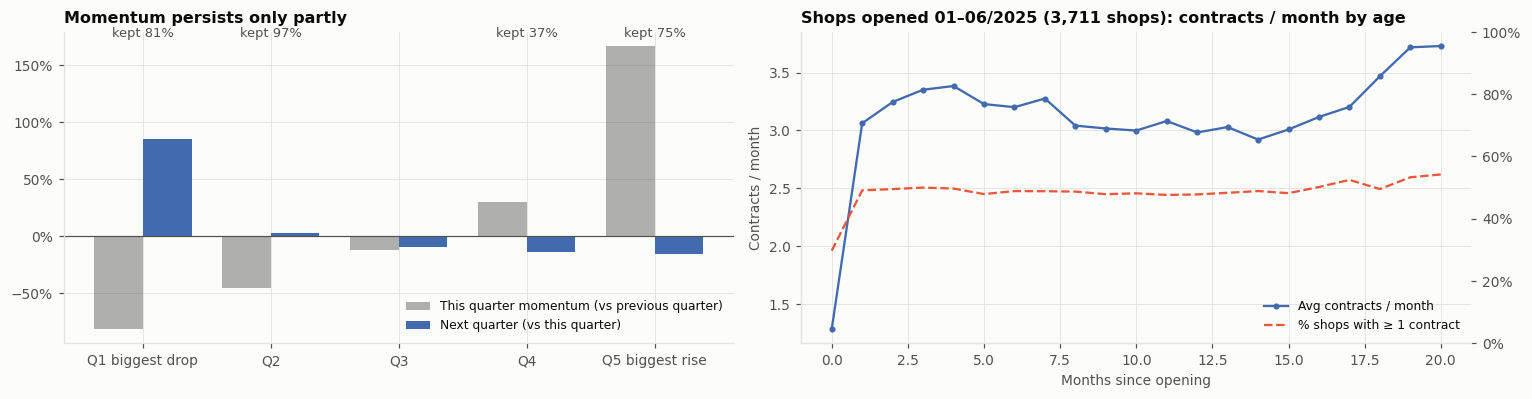

HĐ/tháng theo tuổi: tháng 0: 1.28 · tháng 1: 3.06 · tháng 3: 3.35 · tháng 6: 3.20 · tháng 12: 2.98 · tháng 20: 3.73
Tăng trưởng quý Q3 so với Q2 của nhóm tương đồng (đầu vào M13, chỉ giữ một nửa):


age_band,0–2,3–5,6–11,12+
category,,,,
Big,+0.0%,+30.0%,-6.6%,+1.5%
Medium,+0.0%,+30.0%,+5.6%,+2.3%
Small,+0.0%,+30.0%,+1.7%,+4.2%


In [4]:
QLAB = ['Q1 giảm mạnh nhất', 'Q2', 'Q3', 'Q4', 'Q5 tăng mạnh nhất']
rows_m = []
for T in range(1, 6):
    d_ = SNAP[T]; d_ = d_[(d_.prev >= 1) & (d_.act_T == 3)].copy()
    d_['nhom'] = pd.qcut((d_.cur / d_.prev - 1).rank(method='first'), 5, labels=QLAB)
    for k, g in d_.groupby('nhom', observed=True):
        rows_m.append(dict(du_bao=QN(T + 1), nhom=k, shop=len(g), prev=g.prev.sum(), cur=g.cur.sum(), y=g.y.sum()))
mm = pd.DataFrame(rows_m)
tbm = mm.groupby('nhom', observed=True)[['shop', 'prev', 'cur', 'y']].sum()
tbm['da_quy_nay'] = tbm.cur / tbm.prev - 1
tbm['quy_toi_so_voi_quy_nay'] = tbm.y / tbm.cur - 1
tbm['phan_thay_doi_con_giu'] = ((tbm.y - tbm.prev) / (tbm.cur - tbm.prev)).where(tbm.da_quy_nay.abs() >= .2)   # đà nhỏ: tỷ lệ không có nghĩa
tbm['shop'] = tbm.shop / 5
print('Gộp 5 mốc (dự báo 2025Q2 → 2026Q3); shop = số shop bình quân mỗi mốc:')
display(tbm[['shop', 'da_quy_nay', 'quy_toi_so_voi_quy_nay', 'phan_thay_doi_con_giu']].style.format(
    {'shop': '{:,.0f}', 'da_quy_nay': '{:+.0%}', 'quy_toi_so_voi_quy_nay': '{:+.0%}', 'phan_thay_doi_con_giu': '{:.0%}'}, na_rep='–'))
pv_m = mm.assign(r=mm.y / mm.cur - 1).pivot(index='nhom', columns='du_bao', values='r')
print('Quý tới so với quý này, theo từng mốc:'); display(pv_m.style.format('{:+.0%}'))

# đường cong trưởng thành: shop mở 01–06/2025
op = shops.m_open
AGE_M = pd.DataFrame({m: ((m.year - op.dt.year) * 12 + m.month - op.dt.month).values for m in MONTHS}, index=shops.index)
coh = shops.index[(op >= '2025-01-01') & (op <= '2025-06-01')]
L = pd.DataFrame({'age': AGE_M.loc[coh].values.ravel(), 'y': Y.loc[coh].values.ravel(), 'open': OPEN.loc[coh].values.ravel()})
L = L[L.open & (L.age >= 0)]
rc = L.groupby('age').agg(hd=('y', 'mean'), co_hd=('y', lambda v: (v > 0).mean()), n=('y', 'size'))
rc = rc[rc.n >= 200]

fig, ax = plt.subplots(1, 2, figsize=(14, 3.7))
x_ = np.arange(len(tbm)); w_ = .38
ax[0].bar(x_ - w_ / 2, tbm.da_quy_nay, w_, color=TXT2, alpha=.45, label='This quarter momentum (vs previous quarter)')
ax[0].bar(x_ + w_ / 2, tbm.quy_toi_so_voi_quy_nay, w_, color=C1, label='Next quarter (vs this quarter)')
for xi, v in zip(x_, tbm.phan_thay_doi_con_giu):
    if np.isnan(v): continue
    ax[0].text(xi, max(tbm.da_quy_nay.max(), 0) * 1.05, f'kept {v:.0%}', ha='center', fontsize=8.5, color=TXT2)
ax[0].axhline(0, color=TXT2, lw=.8); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set_xticks(x_, ['Q1 biggest drop', 'Q2', 'Q3', 'Q4', 'Q5 biggest rise']); ax[0].legend(loc='lower right', fontsize=8)
ax[0].set_title('Momentum persists only partly')
ax[1].plot(rc.index, rc.hd, marker='o', ms=3, color=C1, label='Avg contracts / month')
ax[1].set_xlabel('Months since opening'); ax[1].set_ylabel('Contracts / month')
a2 = ax[1].twinx(); a2.plot(rc.index, rc.co_hd, color=C2, ls='--', label='% shops with ≥ 1 contract'); a2.grid(False)
a2.yaxis.set_major_formatter(mtick.PercentFormatter(1)); a2.set_ylim(0, 1)
h1, l1 = ax[1].get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); ax[1].legend(h1 + h2, l1 + l2, loc='lower right', fontsize=8)
ax[1].set_title(f'Shops opened 01–06/2025 ({len(coh):,} shops): contracts / month by age')
plt.tight_layout(); plt.show()
k_ = [a for a in [0, 1, 3, 6, 12, rc.index.max()] if a in rc.index]
print('HĐ/tháng theo tuổi: ' + ' · '.join(f'tháng {a}: {rc.hd[a]:.2f}' for a in k_))

# tăng trưởng quý của nhóm tương đồng (quy mô × tuổi) tại mốc hiện tại, dùng trong M13
d6 = SNAP[6]
print('Tăng trưởng quý Q3 so với Q2 của nhóm tương đồng (đầu vào M13, chỉ giữ một nửa):')
display(d6.groupby(['category', 'age_band']).g_peer.first().unstack().reindex(columns=AGE_LAB).style.format('{:+.1%}'))

**Đọc kết quả:**

**Đà tăng/giảm chỉ kéo dài một phần.**
- Nhóm giảm mạnh nhất và tăng mạnh nhất giữ khoảng **75–80%** mức thay đổi, tức hồi lại khoảng 20–25%.
- Kết quả này lặp lại ở cả 5 mốc:
  - nhóm giảm mạnh nhất quý sau tăng lại khoảng +80–90%;
  - nhóm tăng mạnh nhất quý sau giảm khoảng 5–25%.
- Ngoại suy **nguyên** đà của shop (M2) sẽ dự báo quá tay. Còn "giữ nguyên" (M0) lại bỏ qua phần hồi lại.
- Các mô hình dùng chung (M5, M8, M12) tự học mức hồi lại này từ dữ liệu.

**Số HĐ/tháng gần như không tăng theo tuổi sau tháng đầu tiên.**
- Shop mở 01–06/2025 đạt khoảng 3 HĐ/tháng từ tháng thứ 2 và đi ngang đến tháng 20.
- Ở dữ liệu này, BAU **không có "quán tính trưởng thành" lớn về số HĐ**. Tăng trưởng theo tuổi, nếu có, đến từ giá trị khoản vay chứ không đến từ số HĐ.
- Đường cong chỉ gồm các shop còn mở ở từng tuổi. Shop đóng sớm thường là shop yếu, nên đường cong có thể hơi lạc quan.

## Bước 2 · Baseline và các mô hình ứng viên

| Mã | Phương pháp | Vai trò | Có xét đóng cửa không? |
|---|---|---|---|
| **M0** | Giữ nguyên mức quý hiện tại | baseline bắt buộc | không |
| **M1** | Mức hiện tại × số tháng còn hoạt động kỳ vọng | tách bạch rủi ro đóng cửa | **có, tường minh**: xác suất còn mở từng tháng, *với điều kiện đang mở tại mốc dự báo*, ước lượng từ các mốc trước theo mô hình × dòng hàng × tuổi |
| **M2** | Xu hướng 6 tháng của shop, **co về xu hướng phân khúc** | xu hướng tiếp diễn | không |
| **M13** | **Run-rate 6 tháng × (1 + ½ tăng trưởng quý của nhóm tương đồng)**; nhóm = quy mô shop × tuổi. Giữ một nửa tăng trưởng (damped trend) vì Bước 1b cho thấy đà chỉ kéo dài một phần | xu hướng nhóm, giảm dần | không |
| **M14** | M13 × tỷ lệ tháng còn mở | như M13, có tính đóng cửa | có, tường minh |
| **M3** | Hồi quy tuyến tính dùng chung theo phân khúc × tuổi: kỳ sau = a + b × kỳ này | mô hình dùng chung đơn giản | **có, ngầm**: học từ kết quả thực tế đã gồm shop đóng |
| **M4** | Mô hình đếm Poisson dùng chung (mức hiện tại, quý trước, xu hướng, tuổi, phân khúc, loại đối tác) | mô hình đếm | có, ngầm |
| **M5** | LightGBM (Tweedie) dùng chung, cùng đặc trưng | ML | có, ngầm |
| **M6** | Làm mượt luỹ thừa (SES, α = 0,5) trên chuỗi tháng của shop | chuỗi thời gian đơn giản | không |
| **M7** | Hồi quy Ridge dùng chung, cùng đặc trưng | tuyến tính có điều chuẩn | có, ngầm |
| **M8** | Random Forest dùng chung, cùng đặc trưng | ML khác họ với LightGBM | có, ngầm |
| **M9** | Kết hợp: trung bình M1 và M5 | ensemble | có |
| **M10** | Kết hợp: trung bình M5 (không lệch nhóm) và M6 (sai số thấp) | ensemble | có |
| **M11** | Kết hợp: trung bình M4 (Poisson) và M6 | ensemble | có |
| **M12** | Kết hợp: trung bình M5, M6, M8 | ensemble | có |
| **D1** | **Theo yếu tố kinh doanh:** hồ sơ/tháng hiện tại × tỷ lệ hồ sơ thành HĐ (2 quý gần nhất, co về phân khúc) × tỷ lệ tháng còn mở | driver-based, dễ giải thích | có, tường minh |
| **D2** | **Theo yếu tố kinh doanh:** hồ sơ quý tới **do mô hình dùng chung dự báo** (LightGBM) × tỷ lệ chuyển đổi như D1 | driver-based + mô hình cho đầu vào | có, ngầm (mô hình hồ sơ học cả shop đóng) |

Thứ tự từ đơn giản đến phức tạp (dùng khi phải chọn giữa các phương án ngang nhau): M0 → M6 → M1 → M13 → M14 → D1 → M2 → M3 → D2 → M7 → M4 → M8 → M5 → M9 → M10 → M11 → M12.

Theo pipeline business: baseline (M0) → xu hướng co về nhóm (M2, M13, M14) → **theo yếu tố kinh doanh (D1, D2)** → mô hình dùng chung (M3–M8) → kết hợp (M9–M12).

Các mô hình kết hợp (M9–M12) được thêm vì backtest cho thấy hai nhóm có điểm mạnh ngược nhau: M6 và M1 có sai số thấp nhưng dự báo thấp có hệ thống cho shop ít HĐ; M5 và M8 không lệch theo nhóm nhưng sai số cao hơn. Kết hợp có thể lấy được cả hai.

M3–M5, M7–M8 học từ chỉ tiêu thực tế, trong đó đã có shop đóng giữa quý. Vì vậy **không nhân thêm xác suất sống**, tránh trừ tác động đóng cửa hai lần.

In [5]:
from sklearn.linear_model import PoissonRegressor
import lightgbm as lgb

def survival_frac(train_T, d, h=1):
    # số tháng còn mở kỳ vọng trong h quý tới / (3h), với điều kiện đang mở tại mốc; theo mô hình × dòng hàng × tuổi
    col = 'act_next' if h == 1 else 'act_next2'
    hh = pd.concat([SNAP[t][['model', 'line', 'age_band', col]] for t in train_T]).rename(columns={col: 'a'})
    tab = (hh.groupby(['model', 'line', 'age_band']).a.mean() / (3 * h))
    glob = hh.a.mean() / (3 * h)
    return pd.MultiIndex.from_frame(d[['model', 'line', 'age_band']]).map(tab).fillna(glob).values

def design(d, cols=None):
    X = pd.DataFrame(index=d.index)
    X['l_cur'] = np.log1p(d.cur); X['l_prev'] = np.log1p(d.prev.fillna(d.cur)); X['no_prev'] = d.prev.isna().astype(float)
    X['l_last'] = np.log1p(d.last_m); X['slope'] = d.slope.fillna(0).clip(-10, 10); X['act_T'] = d.act_T
    X = X.join(pd.get_dummies(d.age_band, prefix='age', dtype=float)).join(pd.get_dummies(d.seg, prefix='seg', dtype=float))
    X = X.join(pd.get_dummies(d.seller_type, prefix='st', dtype=float)).join(pd.get_dummies(d.category, prefix='cat', dtype=float))
    return X if cols is None else X.reindex(columns=cols, fill_value=0.0)

def design_a(d, cols=None):
    X = design(d).assign(l_apps=np.log1p(d.apps_cur), l_apps_prev=np.log1p(d.apps_prev))
    return X if cols is None else X.reindex(columns=cols, fill_value=0.0)

K_SHRINK = 30
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

def fit_models(train_T, h=1):
    yc = 'y' if h == 1 else 'y2'
    tr = pd.concat([SNAP[t] for t in train_T], ignore_index=True)
    tr = tr.assign(y=tr[yc])
    col = 'act_next' if h == 1 else 'act_next2'
    surv = tr.groupby(['model', 'line', 'age_band'])[col].mean() / (3 * h)
    g_all = np.polyfit(tr.cur, tr.y, 1)
    m3 = {}
    for (seg, ab), t_ in tr.groupby(['seg', 'age_band']):
        m3[(seg, ab)] = np.polyfit(t_.cur, t_.y, 1) if len(t_) >= 50 else g_all
    Xtr = design(tr)
    fit = dict(h=h, surv=surv, surv_glob=tr[col].mean() / (3 * h), seg_slope=tr.groupby('seg').slope.median(), m3=m3, g_all=g_all,
               cols=Xtr.columns,
               pr=PoissonRegressor(alpha=1e-4, max_iter=1000).fit(Xtr, tr.y * 3 * h),
               gb=lgb.LGBMRegressor(n_estimators=400, learning_rate=.03, num_leaves=31, min_child_samples=40, subsample=.8, subsample_freq=1,
                                    colsample_bytree=.8, objective='tweedie', verbose=-1).fit(Xtr, tr.y),
               rg=Ridge(alpha=10).fit(Xtr, tr.y),
               rf=RandomForestRegressor(n_estimators=200, min_samples_leaf=20, max_features=.5, n_jobs=-1, random_state=0).fit(Xtr, tr.y))
    # mô hình theo yếu tố: tỷ lệ chuyển đổi chung của phân khúc + mô hình dự báo hồ sơ quý tới
    fit['seg_conv'] = tr.groupby('seg').ok2.sum() / tr.groupby('seg').apps2.sum()
    ya_col = 'ya' if h == 1 else None
    if ya_col and ya_col in tr:
        Xa = design_a(tr); fit['cols_a'] = Xa.columns
        fit['ga'] = lgb.LGBMRegressor(n_estimators=400, learning_rate=.03, num_leaves=31, min_child_samples=40, subsample=.8, subsample_freq=1,
                                      colsample_bytree=.8, objective='tweedie', verbose=-1).fit(Xa, tr[ya_col])
    return fit

def predict_frame(d, fit):
    h = fit['h']; P = pd.DataFrame(index=d.index)
    P['M0'] = d.cur
    P['M1'] = d.cur * pd.MultiIndex.from_frame(d[['model', 'line', 'age_band']]).map(fit['surv']).fillna(fit['surv_glob']).values
    w = d.n6 / (d.n6 + K_SHRINK)
    sl = w * d.slope.fillna(0) + (1 - w) * d.seg.map(fit['seg_slope']).fillna(0)
    P['M2'] = (d.cur + (2 if h == 1 else 3.5) * sl).clip(lower=0)
    co = np.array([fit['m3'].get((a, b), fit['g_all']) for a, b in zip(d.seg, d.age_band)])
    P['M3'] = np.clip(co[:, 1] + co[:, 0] * d.cur.values, 0, None)
    X = design(d, fit['cols'])
    P['M4'] = fit['pr'].predict(X) / (3 * h)
    P['M5'] = fit['gb'].predict(X)
    P['M6'] = d.ses
    P['M7'] = np.clip(fit['rg'].predict(X), 0, None)
    P['M8'] = fit['rf'].predict(X)
    P['M9'] = (P.M1 + P.M5) / 2
    P['M10'] = (P.M5 + P.M6) / 2
    P['M11'] = (P.M4 + P.M6) / 2
    P['M12'] = (P.M5 + P.M6 + P.M8) / 3
    conv = (d.ok2 + 20 * d.seg.map(fit['seg_conv'])) / (d.apps2 + 20)                    # hồ sơ → HĐ, co về phân khúc
    surv_ = pd.MultiIndex.from_frame(d[['model', 'line', 'age_band']]).map(fit['surv']).fillna(fit['surv_glob']).values
    apps_fc = fit['ga'].predict(design_a(d, fit['cols_a'])) if 'ga' in fit else d.apps_cur * surv_
    P['D1'] = d.apps_cur * conv * surv_                                                  # hồ sơ giữ mức hiện tại
    P['D2'] = apps_fc * conv                                                             # hồ sơ do mô hình dùng chung dự báo
    P['M13'] = d.run6 * (1 + .5 * d.g_peer) ** (1 if h == 1 else 1.5)                  # run-rate 6 tháng × một nửa tăng trưởng nhóm
    P['M14'] = P.M13 * surv_                                                             # M13 × tháng còn mở
    P['x_conv'] = conv.values; P['x_apps_fc'] = apps_fc; P['x_surv'] = surv_            # thành phần, dùng để giải thích
    return P

def predict_all(T, train_T, h=1):
    d = SNAP[T].copy()
    return d, predict_frame(d, fit_models(train_T, h))

MODELS = ['M0', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'M10', 'M11', 'M12', 'M13', 'M14', 'D1', 'D2']
SIMPLE = ['M0', 'M6', 'M1', 'M13', 'M14', 'D1', 'M2', 'M3', 'D2', 'M7', 'M4', 'M8', 'M5', 'M9', 'M10', 'M11', 'M12']   # từ đơn giản đến phức tạp
NAMES = {'M0': 'M0 Giữ nguyên', 'M1': 'M1 × tháng còn mở', 'M2': 'M2 Xu hướng co về phân khúc', 'M3': 'M3 Hồi quy chung',
         'M4': 'M4 Poisson', 'M5': 'M5 LightGBM', 'M6': 'M6 Làm mượt luỹ thừa', 'M7': 'M7 Ridge', 'M8': 'M8 Random Forest',
         'M9': 'M9 Kết hợp M1 + M5', 'M10': 'M10 Kết hợp M5 + M6', 'M11': 'M11 Kết hợp M4 + M6',
         'M12': 'M12 Kết hợp M5 + M6 + M8', 'D1': 'D1 Yếu tố: hồ sơ hiện tại × chuyển đổi × tháng còn mở',
         'M13': 'M13 Run-rate 6 tháng × ½ tăng trưởng nhóm', 'M14': 'M13 × tháng còn mở',
         'D2': 'D2 Yếu tố: hồ sơ dự báo × chuyển đổi'}

# nhãn tiếng Anh cho biểu đồ (bảng giữ tiếng Việt)
NAMES_EN = {'M0': 'M0 Naive (keep current)', 'M1': 'M1 × months still open', 'M2': 'M2 Trend shrunk to segment', 'M3': 'M3 Pooled regression',
            'M4': 'M4 Poisson', 'M5': 'M5 LightGBM', 'M6': 'M6 Exponential smoothing', 'M7': 'M7 Ridge', 'M8': 'M8 Random Forest',
            'M9': 'M9 Blend M1 + M5', 'M10': 'M10 Blend M5 + M6', 'M11': 'M11 Blend M4 + M6', 'M12': 'M12 Blend M5 + M6 + M8',
            'M13': 'M13 6-month run-rate × ½ peer growth', 'M14': 'M14 = M13 × months still open',
            'D1': 'D1 Driver: current applications × conversion × survival', 'D2': 'D2 Driver: forecast applications × conversion'}
_EN_TXT = {'A0 Truyền thống, không mùa vụ': 'A0 Traditional, no seasonality', 'A Truyền thống + mùa vụ': 'A Traditional + seasonality',
           'B0 Mô hình tháng, không lịch': 'B0 Monthly model, no calendar', 'B Mô hình tháng + lịch sự kiện': 'B Monthly model + event calendar',
           'Ensemble tối ưu có ràng buộc nhóm (±15%)': 'Optimal ensemble, group-bias constraint (±15%)',
           'Ensemble trọng số tối ưu': 'Optimal-weight ensemble', 'M12w Trọng số theo thời gian': 'M12w Time-weighted',
           'Mô hình tháng B0': 'Monthly model B0', 'M12 + hiệu chỉnh lệch tổng': 'M12 + bias correction',
           'M0 Giữ nguyên (baseline)': 'M0 Naive (baseline)', '(đang chọn)': '(selected)'}
def en(s):
    # đổi tên phương pháp sang tiếng Anh cho nhãn biểu đồ
    for k in sorted(set(NAMES) | set(_EN_TXT), key=lambda k: -len(NAMES.get(k, k))):
        vi, e = (NAMES[k], NAMES_EN[k]) if k in NAMES else (k, _EN_TXT[k])
        s = s.replace(vi, e)
    return s


## Bước 3 · Backtest theo thời gian
- **3 mốc dự báo:** cuối 2025Q4 → dự báo 2026Q1; cuối 2026Q1 → 2026Q2; cuối 2026Q2 → 2026Q3.
- Mỗi mốc chỉ dùng thông tin đã biết tại mốc đó. Mô hình dùng chung được huấn luyện trên các mốc trước đó.
- Tập đánh giá = **mọi shop đang mở tại mốc**, kể cả shop đóng trong quý dự báo. Mọi phương pháp được so trên **cùng tập shop, cùng kỳ, cùng đơn vị** (HĐ/tháng bình quân quý).
- **Chỉ số** (mỗi chỉ số trả lời một câu hỏi khác nhau):

  | Chỉ số | Trả lời câu hỏi | Tốt khi |
  |---|---|---|
  | **MAE** | Trung bình mỗi shop sai bao nhiêu HĐ/tháng? | thấp |
  | **RMSE** | Có những lần sai rất lớn không? (phạt nặng sai số lớn) | thấp |
  | **MASE** | Tốt hơn cách "giữ nguyên" bao nhiêu? = MAE ÷ MAE của M0 | < 1 |
  | **WAPE** | Tổng sai số chiếm bao nhiêu % tổng thực tế? | thấp |
  | **Sai lệch tổng** | Tổng mạng lưới bị đoán cao hay thấp có hệ thống? | gần 0 |
  | **R²** | Giải thích được bao nhiêu % chênh lệch giữa các shop? | cao |
  | **Spearman** | Xếp thứ tự shop có đúng không? | cao |
  | **Bắt đúng top 20%** | Trong 20% shop được đoán cao nhất, bao nhiêu % thực sự nằm trong top 20%? | cao |
  | **Poisson deviance** | Mức khớp với dữ liệu đếm (nhiều số 0, số nhỏ) | thấp |
- **Theo nhóm shop:** shop mới, shop ít HĐ, shop lớn, shop suy giảm, shop đóng trong quý dự báo.

MAE               sai_lech_tong              
du_bao                                             2026Q1 2026Q2 2026Q3        2026Q1 2026Q2 2026Q3
model                                                                                              
D1 Yếu tố: hồ sơ hiện tại × chuyển đổi × tháng ...  1.876  1.710  1.604        -0.122 -0.028 -0.127
D2 Yếu tố: hồ sơ dự báo × chuyển đổi                1.880  1.692  1.647        -0.092 -0.016 -0.112
M0 Giữ nguyên                                       1.918  1.764  1.626        -0.080  0.026 -0.078
M1 × tháng còn mở                                   1.878  1.731  1.612        -0.121 -0.007 -0.113
M10 Kết hợp M5 + M6                                 1.811  1.635  1.560        -0.081  0.023 -0.087
M11 Kết hợp M4 + M6                                 1.846  1.675  1.607        -0.059  0.050 -0.077
M12 Kết hợp M5 + M6 + M8                            1.842  1.663  1.574        -0.059  0.031 -0.082
M13 Run-rate 6 tháng × ½ tăng trưởng nhóm           1.983  1.798  1.675        -0.068  0.025 -0.074
M13 × tháng còn mở                                  1.942  1.766  1.661        -0.111 -0.008 -0.109
M2 Xu hướng co về phân khúc                         2.062  1.921  1.776        -0.020  0.106 -0.036
M3 Hồi quy chung                                    1.995  1.874  1.826        -0.053  0.052 -0.064
M4 Poisson                                          1.980  1.776  1.776        -0.024  0.074 -0.064
M5 LightGBM                                         1.899  1.700  1.675        -0.068  0.020 -0.084
M6 Làm mượt luỹ thừa                                1.833  1.685  1.562        -0.094  0.026 -0.089
M7 Ridge                                            2.318  2.233  2.238         0.091  0.158  0.089
M8 Random Forest                                    1.926  1.748  1.670        -0.016  0.048 -0.073
M9 Kết hợp M1 + M5                                  1.821  1.641  1.574        -0.094  0.007 -0.099

Trung bình 3 mốc:


,MAE,RMSE,MASE,WAPE,sai_lech_tong,R2,spearman,top20,poisson_dev,MAE_max
model,,,,,,,,,,
D1 Yếu tố: hồ sơ hiện tại × chuyển đổi × tháng còn mở,1.730,4.760,0.978,0.543,-0.092,0.720,0.749,0.731,5.554,1.876
D2 Yếu tố: hồ sơ dự báo × chuyển đổi,1.740,4.810,0.984,0.546,-0.073,0.719,0.763,0.743,2.059,1.880
M0 Giữ nguyên,1.769,4.800,1.000,0.555,-0.044,0.715,0.745,0.728,6.325,1.918
M1 × tháng còn mở,1.740,4.725,0.984,0.546,-0.080,0.724,0.746,0.729,6.311,1.878
M10 Kết hợp M5 + M6,1.669,4.455,0.944,0.524,-0.048,0.756,0.770,0.744,2.063,1.811
M11 Kết hợp M4 + M6,1.709,4.289,0.967,0.536,-0.029,0.773,0.767,0.745,2.083,1.846
M12 Kết hợp M5 + M6 + M8,1.693,4.670,0.957,0.531,-0.037,0.731,0.767,0.745,2.030,1.842
M13 Run-rate 6 tháng × ½ tăng trưởng nhóm,1.819,4.907,1.028,0.571,-0.039,0.701,0.731,0.725,5.801,1.983
M13 × tháng còn mở,1.790,4.825,1.012,0.562,-0.076,0.712,0.731,0.726,5.785,1.942


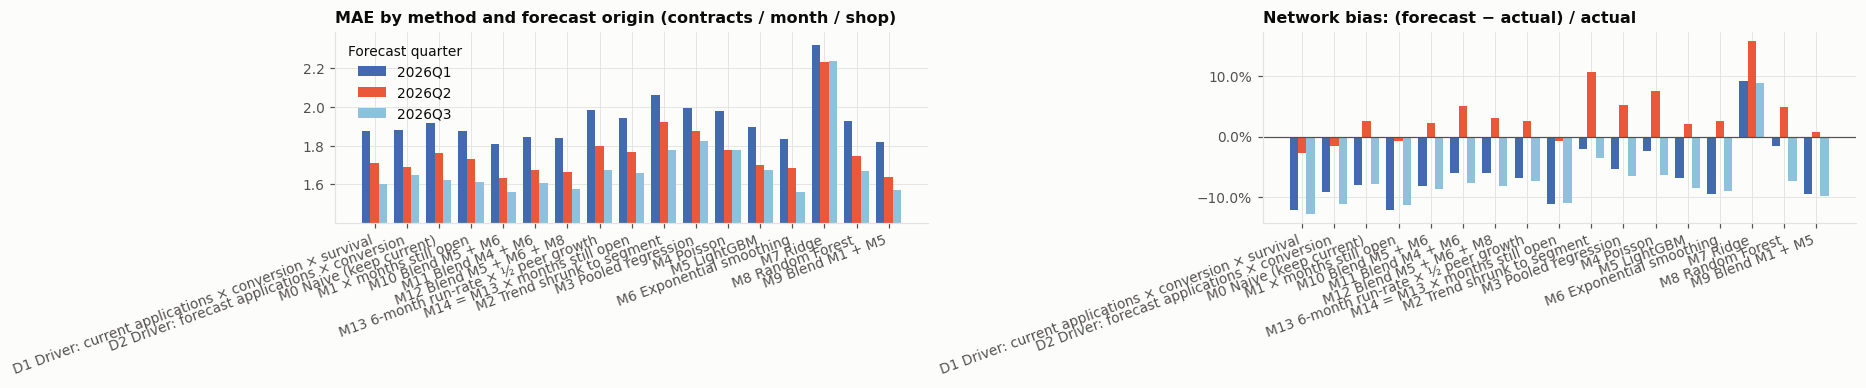

In [6]:
FOLDS = [3, 4, 5]                                   # mốc 2025Q4, 2026Q1, 2026Q2
res, store = [], {}
for T in FOLDS:
    d, P = predict_all(T, list(range(1, T)))
    store[T] = (d, P)
    mae0 = (P.M0 - d.y).abs().mean()
    top_act = set(d.y.nlargest(int(len(d) * .2)).index)
    for m in MODELS:
        e = P[m] - d.y; yh = P[m].clip(lower=1e-6)
        dev = 2 * np.mean(np.where(d.y > 0, d.y * np.log(d.y.clip(lower=1e-9) / yh), 0) - (d.y - yh))
        res.append(dict(moc=QN(T), du_bao=QN(T + 1), model=m, shop=len(d), MAE=e.abs().mean(), RMSE=np.sqrt((e ** 2).mean()),
                        MASE=e.abs().mean() / mae0, WAPE=e.abs().sum() / d.y.sum(), sai_lech_tong=e.sum() / d.y.sum(),
                        R2=1 - (e ** 2).sum() / ((d.y - d.y.mean()) ** 2).sum(), spearman=spearmanr(P[m], d.y).statistic,
                        top20=len(top_act & set(P[m].nlargest(int(len(d) * .2)).index)) / int(len(d) * .2), poisson_dev=dev))
res = pd.DataFrame(res)
summ = res.groupby('model')[['MAE', 'RMSE', 'MASE', 'WAPE', 'sai_lech_tong', 'R2', 'spearman', 'top20', 'poisson_dev']].mean()
summ['MAE_max'] = res.groupby('model').MAE.max()
summ_raw = summ.copy()
summ.index = summ.index.map(NAMES)
display(res.pivot(index='model', columns='du_bao', values=['MAE', 'sai_lech_tong']).rename(index=NAMES).round(3))
print('Trung bình 3 mốc:'); display(summ.round(3))
fig, ax = plt.subplots(1, 2, figsize=(17, 3.6))
pv = res.pivot(index='model', columns='du_bao', values='MAE')
x = np.arange(len(pv)); w = .26
for i, (c, col) in enumerate(zip(pv.columns, [C1, C2, C3])):
    ax[0].bar(x + (i - 1) * w, pv[c], w, color=col, label=c)
ax[0].set_ylim(pv.values.min() * .9, pv.values.max() * 1.03)
ax[0].set_xticks(x, [NAMES_EN[m] for m in pv.index], rotation=20, ha='right'); ax[0].legend(title='Forecast quarter'); ax[0].set_title('MAE by method and forecast origin (contracts / month / shop)')
pb = res.pivot(index='model', columns='du_bao', values='sai_lech_tong')
for i, (c, col) in enumerate(zip(pb.columns, [C1, C2, C3])):
    ax[1].bar(x + (i - 1) * w, pb[c], w, color=col, label=c)
ax[1].axhline(0, color=TXT2, lw=.8); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set_xticks(x, [NAMES_EN[m] for m in pb.index], rotation=20, ha='right'); ax[1].set_title('Network bias: (forecast − actual) / actual')
plt.tight_layout(); plt.show()

In [7]:
# theo nhóm shop
def groups(d):
    return {'Shop mới (< 6 tháng tuổi)': d.age < 6, 'Shop ít HĐ (≤ 1/tháng)': d.cur <= 1, 'Shop lớn (> 10/tháng)': d.cur > 10,
            'Shop suy giảm (giảm > 30% so với quý trước)': (d.prev >= 1) & (d.cur < .7 * d.prev),
            'Shop đóng trong quý dự báo': d.closed_next, 'Tất cả': d.index == d.index}
rows = []
for T in FOLDS:
    d, P = store[T]
    for gname, msk in groups(d).items():
        for m in MODELS:
            rows.append(dict(nhom=gname, model=m, MAE=(P.loc[msk, m] - d.y[msk]).abs().mean(),
                             bias=(P.loc[msk, m] - d.y[msk]).sum() / max(d.y[msk].sum(), 1e-9), n=msk.sum()))
gr = pd.DataFrame(rows).groupby(['nhom', 'model'])[['MAE', 'bias', 'n']].mean().reset_index()
print('MAE theo nhóm (trung bình 3 mốc, HĐ/tháng/shop):')
display(gr.pivot(index='nhom', columns='model', values='MAE').rename(columns=NAMES).round(3))
print('Sai lệch tổng theo nhóm (dự báo − thực tế) / thực tế:')
display(gr.pivot(index='nhom', columns='model', values='bias').rename(columns=NAMES).round(3))

MAE theo nhóm (trung bình 3 mốc, HĐ/tháng/shop):


model,D1 Yếu tố: hồ sơ hiện tại × chuyển đổi × tháng còn mở,D2 Yếu tố: hồ sơ dự báo × chuyển đổi,M0 Giữ nguyên,M1 × tháng còn mở,M10 Kết hợp M5 + M6,M11 Kết hợp M4 + M6,M12 Kết hợp M5 + M6 + M8,M13 Run-rate 6 tháng × ½ tăng trưởng nhóm,M13 × tháng còn mở,M2 Xu hướng co về phân khúc,M3 Hồi quy chung,M4 Poisson,M5 LightGBM,M6 Làm mượt luỹ thừa,M7 Ridge,M8 Random Forest,M9 Kết hợp M1 + M5
nhom,,,,,,,,,,,,,,,,,
Shop lớn (> 10/tháng),8.480,8.105,8.792,8.488,7.715,7.835,7.798,8.894,8.672,10.305,8.574,8.192,8.021,8.170,9.967,8.298,7.770
Shop mới (< 6 tháng tuổi),2.007,2.057,2.031,2.015,1.950,1.963,1.984,2.063,2.044,2.196,2.207,2.124,2.093,1.951,2.573,2.099,1.967
Shop suy giảm (giảm > 30% so với quý trước),1.682,1.600,1.699,1.689,1.612,1.622,1.620,2.251,2.145,1.777,1.714,1.651,1.625,1.649,2.193,1.651,1.618
Shop ít HĐ (≤ 1/tháng),0.606,0.696,0.607,0.607,0.641,0.701,0.666,0.649,0.644,0.614,0.842,0.856,0.721,0.610,0.789,0.734,0.638
Shop đóng trong quý dự báo,2.705,1.760,2.789,2.626,2.173,2.280,2.204,3.336,3.129,2.442,2.606,2.011,1.795,2.553,2.400,2.267,2.208
Tất cả,1.730,1.740,1.769,1.740,1.669,1.709,1.693,1.819,1.790,1.919,1.899,1.844,1.758,1.693,2.263,1.781,1.679


Sai lệch tổng theo nhóm (dự báo − thực tế) / thực tế:


model,D1 Yếu tố: hồ sơ hiện tại × chuyển đổi × tháng còn mở,D2 Yếu tố: hồ sơ dự báo × chuyển đổi,M0 Giữ nguyên,M1 × tháng còn mở,M10 Kết hợp M5 + M6,M11 Kết hợp M4 + M6,M12 Kết hợp M5 + M6 + M8,M13 Run-rate 6 tháng × ½ tăng trưởng nhóm,M13 × tháng còn mở,M2 Xu hướng co về phân khúc,M3 Hồi quy chung,M4 Poisson,M5 LightGBM,M6 Làm mượt luỹ thừa,M7 Ridge,M8 Random Forest,M9 Kết hợp M1 + M5
nhom,,,,,,,,,,,,,,,,,
Shop lớn (> 10/tháng),0.070,-0.042,0.122,0.081,0.025,0.059,0.010,0.077,0.037,0.244,-0.036,0.025,-0.042,0.093,-0.219,-0.021,0.020
Shop mới (< 6 tháng tuổi),-0.196,-0.069,-0.164,-0.188,-0.107,-0.083,-0.081,-0.156,-0.180,-0.035,-0.016,0.013,-0.034,-0.179,0.079,-0.030,-0.111
Shop suy giảm (giảm > 30% so với quý trước),-0.116,-0.150,-0.128,-0.172,-0.069,-0.105,-0.054,0.486,0.410,-0.447,-0.194,-0.186,-0.113,-0.024,0.305,-0.024,-0.142
Shop ít HĐ (≤ 1/tháng),-0.602,-0.093,-0.639,-0.653,-0.305,-0.162,-0.195,-0.456,-0.480,-0.655,0.189,0.268,-0.020,-0.591,0.003,0.025,-0.336
Shop đóng trong quý dự báo,7.757,4.863,7.990,7.489,6.133,6.446,6.250,9.499,8.865,6.933,7.372,5.604,4.979,7.287,6.762,6.485,6.234
Tất cả,-0.092,-0.073,-0.044,-0.080,-0.048,-0.029,-0.037,-0.039,-0.076,0.017,-0.022,-0.005,-0.044,-0.052,0.113,-0.014,-0.062


**Quy tắc chọn phương pháp.** BAU dùng để tính dư địa của **từng shop**, nên ngoài sai số trung bình còn cần **không lệch có hệ thống ở nhóm nào**:
1. **Độ chính xác:** MAE trung bình 3 mốc không kém phương pháp tốt nhất quá **2%**.
2. **Không lệch theo nhóm:** ở 4 nhóm chính (shop mới, shop ít HĐ, shop lớn, shop suy giảm), |sai lệch tổng| ≤ **20%**. Nhóm "đóng trong quý dự báo" chỉ dùng tham khảo, vì thực tế của nhóm này rất nhỏ nên % lệch luôn lớn.
3. Trong các phương pháp đạt cả 1 và 2: chọn |sai lệch tổng mạng lưới| nhỏ nhất. Nếu vẫn ngang nhau, chọn phương pháp đơn giản hơn (thứ tự SIMPLE).
4. Nếu không phương pháp nào đạt cả 1 và 2: **ưu tiên tiêu chí 2**, rồi chọn MAE thấp nhất trong số đạt tiêu chí 2. Lý do: BAU dùng để tính dư địa của từng shop, nên một nhóm shop bị dự báo sai có hệ thống nguy hiểm hơn việc sai số trung bình cao hơn một chút.

Kèm theo là **bảng xếp hạng trên mọi chỉ số** và **kiểm định chênh lệch MAE**, để thấy lựa chọn không phụ thuộc vào một chỉ số duy nhất.

Đánh đổi được nói rõ ngay dưới bảng kết quả.

In [8]:
s_ = res.groupby('model').agg(MAE=('MAE', 'mean'), bias=('sai_lech_tong', lambda x: x.abs().mean()))
KEY = ['Shop mới (< 6 tháng tuổi)', 'Shop ít HĐ (≤ 1/tháng)', 'Shop lớn (> 10/tháng)', 'Shop suy giảm (giảm > 30% so với quý trước)']
gb_ = gr[gr.nhom.isin(KEY)].pivot(index='model', columns='nhom', values='bias').abs()
s_['lech_nhom_max'] = gb_.max(axis=1)
best = s_.MAE.min()
s_['dat_1_MAE'] = s_.MAE <= best * 1.02
s_['dat_2_nhom'] = s_.lech_nhom_max <= .20
display(s_.rename(index=NAMES).round(3))
cand = [m for m in MODELS if s_.loc[m, 'dat_1_MAE'] and s_.loc[m, 'dat_2_nhom']]
if cand:
    CHOSEN = min(cand, key=lambda m: (round(s_.loc[m, 'bias'], 3), SIMPLE.index(m)))
else:
    # không mô hình nào đạt cả 2: ưu tiên không lệch theo nhóm, rồi chọn MAE thấp nhất trong nhóm đó
    ok2 = [m for m in MODELS if s_.loc[m, 'dat_2_nhom']]
    CHOSEN = min(ok2, key=lambda m: (round(s_.loc[m, 'MAE'], 3), SIMPLE.index(m)))
    print('Không mô hình nào đạt đồng thời 2 tiêu chí → ưu tiên tiêu chí 2 (không lệch theo nhóm), chọn MAE thấp nhất trong số đạt tiêu chí 2.')
print(f"→ Chọn: {NAMES[CHOSEN]} (MAE {s_.loc[CHOSEN, 'MAE']:.3f}; |sai lệch tổng| TB {s_.loc[CHOSEN, 'bias']:.1%}; "
      f"lệch nhóm lớn nhất {s_.loc[CHOSEN, 'lech_nhom_max']:.0%})")
for m in ['M0', 'M1', s_.MAE.idxmin()]:
    if m != CHOSEN and s_.loc[m, 'lech_nhom_max'] > .20:
        print(f"   Đánh đổi so với {NAMES[m]}: MAE chênh {s_.loc[CHOSEN, 'MAE'] - s_.loc[m, 'MAE']:+.3f} HĐ/tháng/shop, "
              f"nhưng {NAMES[m]} lệch tới {s_.loc[m, 'lech_nhom_max']:.0%} ở nhóm '{gb_.loc[m].idxmax()}': "
              f"dự báo sai có hệ thống cho cả nhóm shop đó.")

# xếp hạng trên mọi chỉ số (1 = tốt nhất)
rk = pd.DataFrame({'MAE': summ_raw.MAE.rank(), 'RMSE': summ_raw.RMSE.rank(), '|Sai lệch tổng|': summ_raw.sai_lech_tong.abs().rank(),
                   'R²': summ_raw.R2.rank(ascending=False), 'Spearman': summ_raw.spearman.rank(ascending=False),
                   'Top 20%': summ_raw.top20.rank(ascending=False), 'Poisson dev.': summ_raw.poisson_dev.rank(),
                   'Lệch nhóm lớn nhất': s_.lech_nhom_max.rank()})
rk['Hạng TB'] = rk.mean(axis=1)
print('Xếp hạng trên từng chỉ số (1 = tốt nhất; trung bình 3 mốc):')
display(rk.sort_values('Hạng TB').rename(index=NAMES).round(1))

# kiểm định: chênh lệch MAE (mô hình − mô hình chọn), bootstrap theo shop, gộp 3 mốc
ae = {m: np.concatenate([(store[T][1][m] - store[T][0].y).abs().values for T in FOLDS]) for m in MODELS}
rng_b = np.random.default_rng(1); n_ = len(ae[CHOSEN]); B = 500
idx_b = rng_b.integers(0, n_, size=(B, n_))
rows_t = []
for m in MODELS:
    if m == CHOSEN: continue
    diff_ = ae[m] - ae[CHOSEN]
    bs = diff_[idx_b].mean(axis=1)
    lo_, hi_ = np.percentile(bs, [2.5, 97.5])
    rows_t.append(dict(mo_hinh=NAMES[m], chenh_MAE=diff_.mean(), CI95_thap=lo_, CI95_cao=hi_,
                       ket_luan='kém hơn rõ' if lo_ > 0 else ('tốt hơn rõ' if hi_ < 0 else 'không khác biệt rõ')))
print(f'Chênh lệch MAE so với {NAMES[CHOSEN]} (dương = kém hơn mô hình chọn), khoảng tin cậy 95% bootstrap:')
display(pd.DataFrame(rows_t).sort_values('chenh_MAE').round(4))

,MAE,bias,lech_nhom_max,dat_1_MAE,dat_2_nhom
model,,,,,
D1 Yếu tố: hồ sơ hiện tại × chuyển đổi × tháng còn mở,1.730,0.092,0.602,False,False
D2 Yếu tố: hồ sơ dự báo × chuyển đổi,1.740,0.073,0.150,False,True
M0 Giữ nguyên,1.769,0.061,0.639,False,False
M1 × tháng còn mở,1.740,0.080,0.653,False,False
M10 Kết hợp M5 + M6,1.669,0.064,0.305,True,False
M11 Kết hợp M4 + M6,1.709,0.062,0.162,False,True
M12 Kết hợp M5 + M6 + M8,1.693,0.058,0.195,True,True
M13 Run-rate 6 tháng × ½ tăng trưởng nhóm,1.819,0.055,0.486,False,False
M13 × tháng còn mở,1.790,0.076,0.480,False,False


→ Chọn: M12 Kết hợp M5 + M6 + M8 (MAE 1.693; |sai lệch tổng| TB 5.8%; lệch nhóm lớn nhất 20%)
   Đánh đổi so với M0 Giữ nguyên: MAE chênh -0.076 HĐ/tháng/shop, nhưng M0 Giữ nguyên lệch tới 64% ở nhóm 'Shop ít HĐ (≤ 1/tháng)': dự báo sai có hệ thống cho cả nhóm shop đó.
   Đánh đổi so với M1 × tháng còn mở: MAE chênh -0.047 HĐ/tháng/shop, nhưng M1 × tháng còn mở lệch tới 65% ở nhóm 'Shop ít HĐ (≤ 1/tháng)': dự báo sai có hệ thống cho cả nhóm shop đó.
   Đánh đổi so với M10 Kết hợp M5 + M6: MAE chênh +0.025 HĐ/tháng/shop, nhưng M10 Kết hợp M5 + M6 lệch tới 31% ở nhóm 'Shop ít HĐ (≤ 1/tháng)': dự báo sai có hệ thống cho cả nhóm shop đó.
Xếp hạng trên từng chỉ số (1 = tốt nhất; trung bình 3 mốc):


,MAE,RMSE,|Sai lệch tổng|,R²,Spearman,Top 20%,Poisson dev.,Lệch nhóm lớn nhất,Hạng TB
model,,,,,,,,,
M11 Kết hợp M4 + M6,5.000,1.000,5.000,1.000,3.000,1.000,5.000,4.000,3.100
M10 Kết hợp M5 + M6,1.000,2.000,10.000,2.000,1.000,4.000,4.000,9.000,4.100
M12 Kết hợp M5 + M6 + M8,4.000,6.000,6.000,6.000,2.000,2.000,1.000,6.000,4.100
M9 Kết hợp M1 + M5,2.000,3.000,12.000,3.000,4.000,8.000,7.000,10.000,6.100
M5 LightGBM,9.000,9.000,9.000,8.000,6.000,3.000,3.000,2.000,6.100
M4 Poisson,14.000,5.000,1.000,4.000,9.000,7.000,8.000,7.000,6.900
D2 Yếu tố: hồ sơ dự báo × chuyển đổi,7.000,11.000,13.000,10.000,5.000,5.000,2.000,3.000,7.000
M8 Random Forest,11.000,16.000,2.000,16.000,7.000,6.000,6.000,1.000,8.100
M6 Làm mượt luỹ thừa,3.000,4.000,11.000,5.000,12.000,9.000,12.000,13.000,8.600


Chênh lệch MAE so với M12 Kết hợp M5 + M6 + M8 (dương = kém hơn mô hình chọn), khoảng tin cậy 95% bootstrap:


,mo_hinh,chenh_MAE,CI95_thap,CI95_cao,ket_luan
10,M10 Kết hợp M5 + M6,-0.024,-0.033,-0.014,tốt hơn rõ
9,M9 Kết hợp M1 + M5,-0.013,-0.024,-0.001,tốt hơn rõ
6,M6 Làm mượt luỹ thừa,-0.001,-0.020,0.017,không khác biệt rõ
11,M11 Kết hợp M4 + M6,0.018,-0.004,0.035,không khác biệt rõ
14,D1 Yếu tố: hồ sơ hiện tại × chuyển đổi × tháng...,0.036,0.013,0.058,kém hơn rõ
1,M1 × tháng còn mở,0.047,0.024,0.068,kém hơn rõ
15,D2 Yếu tố: hồ sơ dự báo × chuyển đổi,0.049,0.031,0.067,kém hơn rõ
5,M5 LightGBM,0.068,0.051,0.088,kém hơn rõ
0,M0 Giữ nguyên,0.074,0.050,0.097,kém hơn rõ
8,M8 Random Forest,0.089,0.070,0.111,kém hơn rõ


#### Sai số dễ đọc cho Ban quản lý: WAPE và sai lệch theo quy mô shop
- **WAPE** = tổng |dự báo − thực tế| ÷ tổng thực tế: "dự báo từng shop sai bao nhiêu % so với tổng HĐ".
- **Sai lệch** = (tổng dự báo − tổng thực tế) ÷ tổng thực tế, tính riêng cho từng quy mô shop.
- So sánh các mô hình tiêu biểu: baseline, M13/M14 (run-rate × ½ tăng trưởng nhóm), D2 (theo yếu tố), M10 (MAE thấp nhất) và mô hình được chọn.

In [9]:
SHOW = list(dict.fromkeys(['M0', 'M13', 'M14', 'D2', 'M10', CHOSEN]))
CATS_ = sorted(store[FOLDS[0]][0].category.unique()) + ['Tất cả']
rows_w = []
for T in FOLDS:
    d, P = store[T]
    for cat in CATS_:
        msk = (d.category == cat) if cat != 'Tất cả' else (d.index == d.index)
        for m in SHOW:
            e = P.loc[msk, m] - d.y[msk]
            rows_w.append(dict(du_bao=QN(T + 1), quy_mo=cat, model=NAMES[m], WAPE=e.abs().sum() / d.y[msk].sum(), sai_lech=e.sum() / d.y[msk].sum()))
rw = pd.DataFrame(rows_w)
order_ = [NAMES[m] for m in SHOW]
print('WAPE theo quy mô shop (trung bình 3 mốc):')
display(rw.groupby(['model', 'quy_mo']).WAPE.mean().unstack().reindex(index=order_, columns=CATS_).style.format('{:.1%}'))
print('Sai lệch tổng theo quy mô shop (trung bình 3 mốc; dương = đoán cao):')
display(rw.groupby(['model', 'quy_mo']).sai_lech.mean().unstack().reindex(index=order_, columns=CATS_).style.format('{:+.1%}'))
print('WAPE toàn mạng lưới theo từng mốc:')
display(rw[rw.quy_mo == 'Tất cả'].pivot(index='model', columns='du_bao', values='WAPE').reindex(order_).style.format('{:.1%}'))

WAPE theo quy mô shop (trung bình 3 mốc):


quy_mo,Big,Medium,Small,Tất cả
model,,,,
M0 Giữ nguyên,48.8%,56.8%,56.9%,55.5%
M13 Run-rate 6 tháng × ½ tăng trưởng nhóm,49.8%,58.7%,58.2%,57.1%
M13 × tháng còn mở,49.2%,57.8%,57.2%,56.2%
D2 Yếu tố: hồ sơ dự báo × chuyển đổi,51.8%,55.8%,54.6%,54.6%
M10 Kết hợp M5 + M6,47.1%,53.7%,53.1%,52.4%
M12 Kết hợp M5 + M6 + M8,48.7%,54.2%,53.8%,53.1%


Sai lệch tổng theo quy mô shop (trung bình 3 mốc; dương = đoán cao):


quy_mo,Big,Medium,Small,Tất cả
model,,,,
M0 Giữ nguyên,-11.3%,-5.3%,-1.5%,-4.4%
M13 Run-rate 6 tháng × ½ tăng trưởng nhóm,-11.2%,-5.2%,-0.5%,-3.9%
M13 × tháng còn mở,-13.8%,-9.1%,-4.5%,-7.6%
D2 Yếu tố: hồ sơ dự báo × chuyển đổi,-9.3%,-5.5%,-8.1%,-7.3%
M10 Kết hợp M5 + M6,-8.9%,-4.4%,-3.9%,-4.8%
M12 Kết hợp M5 + M6 + M8,-10.2%,-2.2%,-2.8%,-3.7%


WAPE toàn mạng lưới theo từng mốc:


du_bao,2026Q1,2026Q2,2026Q3
model,,,
M0 Giữ nguyên,60.0%,57.1%,49.5%
M13 Run-rate 6 tháng × ½ tăng trưởng nhóm,62.0%,58.2%,51.0%
M13 × tháng còn mở,60.7%,57.2%,50.6%
D2 Yếu tố: hồ sơ dự báo × chuyển đổi,58.8%,54.8%,50.2%
M10 Kết hợp M5 + M6,56.6%,52.9%,47.5%
M12 Kết hợp M5 + M6 + M8,57.6%,53.9%,48.0%


## Bước 3b · Kiểm tra mô hình: giữ nguyên các yếu tố khác, đổi một yếu tố
Mục này kiểm tra mô hình được chọn có **hành xử hợp lý về nghiệp vụ** hay không, bằng hai cách:

1. **Tầm quan trọng hoán vị:** trên mốc gần nhất (dự báo 2026Q3), xáo trộn ngẫu nhiên **một** yếu tố giữa các shop, giữ nguyên các yếu tố còn lại, đo MAE tăng bao nhiêu. Tăng nhiều thì mô hình dựa nhiều vào yếu tố đó.
2. **Hồ sơ "giữ nguyên – đổi một" (ceteris paribus):** lấy một **shop điển hình** (CD · Non-Aldi · Small · Stone Shop, trên 12 tháng tuổi, đang bán đều 5 HĐ/tháng), giữ nguyên mọi đặc điểm, chỉ thay **một** yếu tố, xem BAU thay đổi thế nào.

**Kỳ vọng hợp lý:**
- BAU tăng theo mức hiện tại nhưng **dốc nhỏ hơn 1** (shop rất cao có xu hướng giảm bớt).
- Shop đang giảm có BAU thấp hơn shop đang tăng.
- Tháng gần nhất = 0 kéo BAU xuống mạnh.

,yeu_to,MAE_tang,pct
2,Tháng gần nhất,0.620,0.394
0,Mức hiện tại (HĐ/tháng quý T),0.455,0.289
1,Quý trước (T−1),0.057,0.036
4,Số tháng đã mở trong quý,0.021,0.013
3,Xu hướng 6 tháng,0.011,0.007
6,Phân khúc (dòng hàng × mô hình),0.010,0.006
7,Loại đối tác,0.007,0.004
5,Tuổi shop,-0.002,-0.001
8,Quy mô shop,-0.002,-0.002


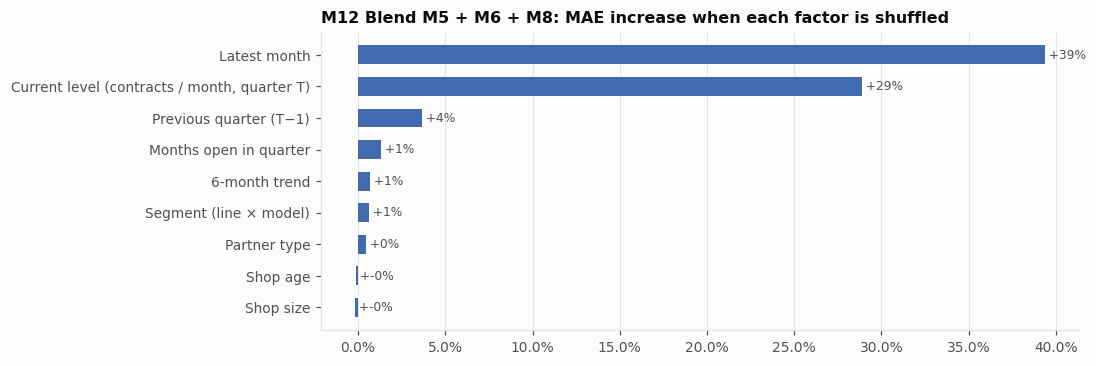

In [10]:
fit_last = fit_models(list(range(1, 5)))                 # mô hình dùng ở mốc 2026Q2 → dự báo 2026Q3
d5 = SNAP[5].copy()
base_mae = (predict_frame(d5, fit_last)[CHOSEN] - d5.y).abs().mean()
FEATS = {'Mức hiện tại (HĐ/tháng quý T)': ['cur'], 'Quý trước (T−1)': ['prev'], 'Tháng gần nhất': ['last_m'],
         'Xu hướng 6 tháng': ['slope', 'n6'], 'Số tháng đã mở trong quý': ['act_T'], 'Tuổi shop': ['age_band', 'age'],
         'Phân khúc (dòng hàng × mô hình)': ['seg', 'line', 'model'], 'Loại đối tác': ['seller_type'], 'Quy mô shop': ['category']}
rng_p = np.random.default_rng(2); rows_p = []
for name, cols_ in FEATS.items():
    inc = []
    for _ in range(3):
        dp = d5.copy(); perm = rng_p.permutation(len(dp))
        for c_ in cols_: dp[c_] = dp[c_].values[perm]
        inc.append((predict_frame(dp, fit_last)[CHOSEN] - dp.y).abs().mean() - base_mae)
    rows_p.append(dict(yeu_to=name, MAE_tang=np.mean(inc), pct=np.mean(inc) / base_mae))
pi = pd.DataFrame(rows_p).sort_values('MAE_tang', ascending=False)
display(pi.round(4))
FEATS_EN = {'Mức hiện tại (HĐ/tháng quý T)': 'Current level (contracts / month, quarter T)', 'Quý trước (T−1)': 'Previous quarter (T−1)',
            'Tháng gần nhất': 'Latest month', 'Xu hướng 6 tháng': '6-month trend', 'Số tháng đã mở trong quý': 'Months open in quarter',
            'Tuổi shop': 'Shop age', 'Phân khúc (dòng hàng × mô hình)': 'Segment (line × model)', 'Loại đối tác': 'Partner type',
            'Quy mô shop': 'Shop size'}
fig, ax = plt.subplots(figsize=(10, 3.4)); y_ = np.arange(len(pi))
ax.barh(y_, pi.pct, color=C1, height=.6); ax.set_yticks(y_, pi.yeu_to.map(FEATS_EN)); ax.invert_yaxis(); ax.grid(axis='y', visible=False)
for yi, v in zip(y_, pi.pct): ax.text(v, yi, f' +{v:.0%}', va='center', fontsize=8, color=TXT2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_title(f'{NAMES_EN[CHOSEN]}: MAE increase when each factor is shuffled')
plt.tight_layout(); plt.show()

Shop điển hình (5 HĐ/tháng, đều, > 12 tháng tuổi): BAU = 4.98


BAU  so_voi_shop_dien_hinh
Mức hiện tại (quý trước, tháng cuối bằng nhau)  0              0.080                 -4.890
                                                1              1.180                 -3.790
                                                2              2.020                 -2.950
                                                5              4.980                  0.000
                                                10             9.520                  4.550
                                                20            18.810                 13.830
                                                40            35.220                 30.250
Quý trước (hiện tại = 5)                        1              4.370                 -0.600
                                               2.500           4.410                 -0.560
                                                5              4.980                  0.000
                                               7.500           5.550                  0.570
                                                10             5.660                  0.680
Tháng gần nhất (hiện tại = 5)                   0              3.380                 -1.600
                                                2              4.380                 -0.590
                                                5              4.980                  0.000
                                                8              5.940                  0.970
                                                12             6.560                  1.580
Xu hướng 6 tháng (HĐ/tháng mỗi tháng)          -1.000          5.010                  0.040
                                               -0.500          5.000                  0.030
                                                0              4.980                  0.000
                                               0.500           4.980                  0.000
                                                1              5.140                  0.160
Số tháng đã mở trong quý                        1              6.770                  1.790
                                                2              5.290                  0.310
                                                3              4.980                  0.000
Tuổi shop                                       0–2            5.070                  0.090
                                                3–5            5.170                  0.190
                                                6–11           5.020                  0.040
                                                12+            4.980                  0.000
Phân khúc                                       CD · Aldi      5.440                  0.460
                                                CD · Non-Aldi  4.980                  0.000
                                                NS · Aldi      5.300                  0.320
                                                TW · Non-Aldi  5.160                  0.180
Loại đối tác                                    Key Account    5.500                  0.530
                                                Local Partner  5.050                  0.080
                                                NS KA          5.060                  0.080
                                                Stone Shop     4.980                  0.000
                                                TW Key Dealer  5.450                  0.480
Quy mô shop                                     Small          4.980                  0.000
                                                Medium         4.970                 -0.000
                                                Big            5.070                  0.090

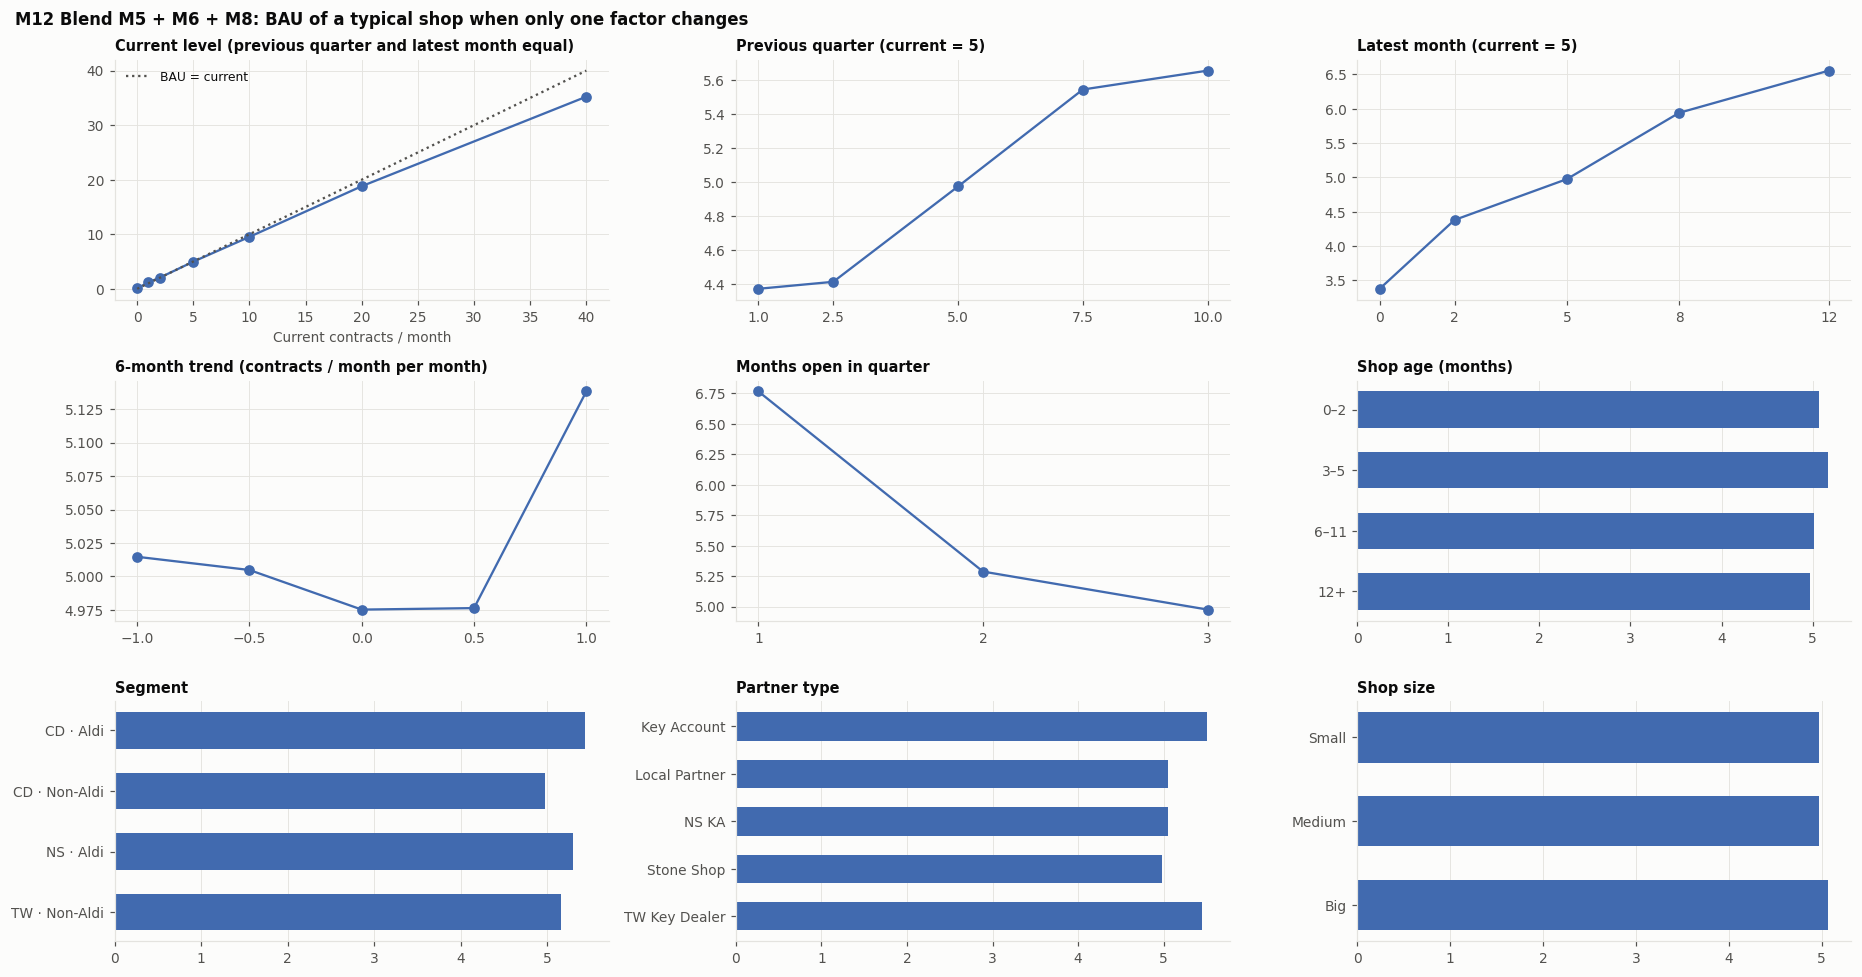

In [11]:
fit_now = fit_models(list(range(1, 6)))                  # mô hình dùng cho dự báo Q4/2026
ref = SNAP[6][(SNAP[6].seg == 'CD · Non-Aldi') & (SNAP[6].category == 'Small') & (SNAP[6].seller_type == 'Stone Shop')].iloc[[0]].copy()
ref[['cur', 'prev', 'prev2', 'last_m', 'ses']] = 5.0; ref[['slope']] = 0.0; ref['n6'] = 30; ref['act_T'] = 3
ref['age'] = 15; ref['age_band'] = '12+'
def what_if(col, values, extra=None):
    out = []
    for v in values:
        r_ = ref.copy(); r_[col] = v
        if extra: extra(r_, v)
        out.append(predict_frame(r_, fit_now)[CHOSEN].iloc[0])
    return pd.Series(out, index=values)
def lvl(r_, v): r_[['prev', 'prev2', 'last_m', 'ses']] = v; r_['n6'] = 6 * v
WI = {
 'Mức hiện tại (quý trước, tháng cuối bằng nhau)': what_if('cur', [0, 1, 2, 5, 10, 20, 40], lvl),
 'Quý trước (hiện tại = 5)': what_if('prev', [1, 2.5, 5, 7.5, 10]),
 'Tháng gần nhất (hiện tại = 5)': what_if('last_m', [0, 2, 5, 8, 12]),
 'Xu hướng 6 tháng (HĐ/tháng mỗi tháng)': what_if('slope', [-1, -.5, 0, .5, 1]),
 'Số tháng đã mở trong quý': what_if('act_T', [1, 2, 3]),
 'Tuổi shop': what_if('age_band', AGE_LAB, lambda r_, v: r_.__setitem__('age', {'0–2': 1, '3–5': 4, '6–11': 8, '12+': 15}[v])),
 'Phân khúc': what_if('seg', sorted(SNAP[6].seg.unique()), lambda r_, v: r_.__setitem__('model', v.split(' · ')[1]) or r_.__setitem__('line', v.split(' · ')[0])),
 'Loại đối tác': what_if('seller_type', sorted(SNAP[6].seller_type.unique())),
 'Quy mô shop': what_if('category', ['Small', 'Medium', 'Big']),
}
tbl_wi = pd.concat({k: v.rename('BAU') for k, v in WI.items()}).to_frame()
tbl_wi['so_voi_shop_dien_hinh'] = tbl_wi.BAU - predict_frame(ref, fit_now)[CHOSEN].iloc[0]
print(f"Shop điển hình (5 HĐ/tháng, đều, > 12 tháng tuổi): BAU = {predict_frame(ref, fit_now)[CHOSEN].iloc[0]:.2f}")
display(tbl_wi.round(2))
WI_EN = {'Mức hiện tại (quý trước, tháng cuối bằng nhau)': 'Current level (previous quarter and latest month equal)',
         'Quý trước (hiện tại = 5)': 'Previous quarter (current = 5)', 'Tháng gần nhất (hiện tại = 5)': 'Latest month (current = 5)',
         'Xu hướng 6 tháng (HĐ/tháng mỗi tháng)': '6-month trend (contracts / month per month)', 'Số tháng đã mở trong quý': 'Months open in quarter',
         'Tuổi shop': 'Shop age (months)', 'Phân khúc': 'Segment', 'Loại đối tác': 'Partner type', 'Quy mô shop': 'Shop size'}
fig, axes = plt.subplots(3, 3, figsize=(17, 9))
for a_, (k, v) in zip(axes.ravel(), WI.items()):
    xs = [str(x_) for x_ in v.index]
    if k.startswith('Mức hiện tại'):
        a_.plot(v.index, v.values, color=C1, marker='o'); a_.plot(v.index, v.index, color=TXT2, ls=':', label='BAU = current')
        a_.legend(fontsize=8); a_.set_xlabel('Current contracts / month')
    elif v.index.dtype.kind in 'if':
        a_.plot(v.index, v.values, color=C1, marker='o'); a_.set_xticks(v.index)
    else:
        a_.barh(range(len(v)), v.values, color=C1, height=.6); a_.set_yticks(range(len(v)), xs); a_.invert_yaxis(); a_.grid(axis='y', visible=False)
    a_.set_title(WI_EN[k], fontsize=9.5)
fig.suptitle(f'{NAMES_EN[CHOSEN]}: BAU of a typical shop when only one factor changes', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

## Bước 3c · Kiểm định chéo bằng 2 cách tiếp cận: truyền thống và mô hình có mùa vụ / sự kiện
Mục đích: kiểm tra BAU có **bền với cách làm** không, và mùa vụ hay sự kiện (Tết, iPhone ra mắt, siêu sale) có làm dự báo **tốt hơn thật** không.

| | Cách A – Truyền thống (phễu × mùa vụ) | Cách B – Mô hình theo tháng có lịch sự kiện |
|---|---|---|
| **Công thức** | BAU = hồ sơ/tháng quý hiện tại × tỷ lệ ký của shop (co về phân khúc) × **hệ số mùa vụ** × tỷ lệ tháng còn mở kỳ vọng | LightGBM dự báo **từng tháng** của quý tới (1, 2, 3 tháng sau mốc), lấy trung bình 3 tháng |
| **Mùa vụ / sự kiện** | hệ số = chỉ số cùng tập shop của **cùng kỳ năm trước** (quý tới ÷ quý hiện tại), theo dòng hàng; không có năm trước thì = 1 | cờ lịch: **tháng Tết**, **tháng trước Tết**, **mùa ra mắt iPhone (tháng 9–10)**, **siêu sale 11/11 & Black Friday (tháng 11)**, **12/12 (tháng 12)**, số ngày trong tháng; tương tác cờ iPhone × tỷ trọng HĐ điện thoại của shop |
| **Biến thể đối chứng** | A0: cùng công thức, hệ số mùa vụ = 1 | B0: cùng mô hình, **bỏ** các cờ lịch |

**Giả định cần nói rõ:**
- Ngày Tết: 29/01/2025 và 17/02/2026.
- Tháng 9–10 là mùa ra mắt iPhone.
- Tháng 11 và 12 có siêu sale.

Dữ liệu mới có **21 tháng**: mỗi sự kiện chỉ quan sát được **1 lần**, và cách A chỉ có hệ số mùa vụ cùng kỳ năm trước cho các quý từ Q3/2026 trở đi. Bảng ở cuối mục cho biết mùa vụ / sự kiện có cải thiện dự báo hay không.

In [12]:
# ---------- dữ liệu bổ sung: hồ sơ theo shop × tháng, tỷ trọng HĐ điện thoại ----------
apps_m = con.sql(f'''SELECT skp_salesroom, date_trunc('month', date_apply)::DATE m, count(*) n FROM {rd('contract')}
                     WHERE skp_salesroom IN (SELECT skp_salesroom FROM {rd('salesroom')}) GROUP BY 1, 2''').df()
A_ = apps_m.pivot_table(index='skp_salesroom', columns='m', values='n', aggfunc='sum').reindex(index=shops.index, columns=MONTHS).fillna(0).where(OPEN, 0)
mob = con.sql(f'''SELECT c.skp_salesroom, date_trunc('month', c.date_apply)::DATE m, count(*) n
                  FROM {rd('contract')} c JOIN {rd('contract_product')} p USING (skp_credit_case)
                  WHERE c.is_signed AND c.name_status <> 'Cancelled' AND p.goods_group = 'MOBILE' GROUP BY 1, 2''').df()
MOB = mob.pivot_table(index='skp_salesroom', columns='m', values='n', aggfunc='sum').reindex(index=shops.index, columns=MONTHS).fillna(0)

# ---------- lịch sự kiện ----------
TET = {2025: pd.Timestamp('2025-01-01'), 2026: pd.Timestamp('2026-02-01'), 2027: pd.Timestamp('2027-02-01')}   # tháng có Tết (2027: 06/02)
def cal(m):
    m = pd.Timestamp(m)
    return dict(tet=int(m == TET.get(m.year)), truoc_tet=int(m + pd.DateOffset(months=1) == TET.get((m + pd.DateOffset(months=1)).year)),
                iphone=int(m.month in (9, 10)), sale_11=int(m.month == 11), sale_12=int(m.month == 12), so_ngay=m.days_in_month, thang=m.month)

# ---------- chỉ số mùa vụ cùng tập shop (theo dòng hàng): xích các tỷ số tháng sau / tháng trước ----------
def seasonal_index(min_age=3, min_shop=30):
    rows = []
    for i in range(1, len(MONTHS)):
        m0, m1 = MONTHS[i - 1], MONTHS[i]
        ok_ = OPEN[m0] & OPEN[m1] & (shops.m_open <= m0 - pd.DateOffset(months=min_age))
        for line, g in shops[ok_].groupby('line'):
            if len(g) >= min_shop and Y.loc[g.index, m0].sum() > 0:
                rows.append(dict(m=m1, line=line, g=Y.loc[g.index, m1].sum() / Y.loc[g.index, m0].sum()))
    gr_ = pd.DataFrame(rows).pivot(index='m', columns='line', values='g')
    return gr_
SI_GROWTH = seasonal_index()
def season_factor(line, T):
    # hệ số = (mức bình quân quý T+1 năm trước) / (mức bình quân quý T năm trước), từ chuỗi tăng trưởng cùng tập shop
    if line not in SI_GROWTH: return 1.0
    g = SI_GROWTH[line]
    ms_base, ms_tgt = QM.get(T - 4), QM.get(T - 3)
    if not ms_base or not ms_tgt: return 1.0
    chain = g.loc[ms_base[0]:ms_tgt[-1]] if ms_base[0] in g.index else None
    if chain is None or chain.isna().any() or len(chain) < 5: return 1.0
    lvl = pd.concat([pd.Series([1.0], index=[ms_base[0]]), chain.iloc[1:].cumprod()])
    return lvl.loc[ms_tgt].mean() / lvl.loc[ms_base].mean()
print('Tăng trưởng tháng/tháng cùng tập shop (≥ 3 tháng tuổi):'); display(SI_GROWTH.round(3).T)

# ---------- cách A ----------
def method_A(T, train_T, seasonal=True):
    d = SNAP[T]; ids = d.index; mT = QM[T]; mP = QM[T - 1]
    actT = OPEN.loc[ids, mT].sum(axis=1).clip(lower=1)
    apps_base = A_.loc[ids, mT].sum(axis=1) / actT
    ok2 = Y.loc[ids, mT + mP].sum(axis=1); ap2 = A_.loc[ids, mT + mP].sum(axis=1)
    seg_conv = (Y.loc[ids, mT + mP].sum(axis=1).groupby(d.seg).sum() / A_.loc[ids, mT + mP].sum(axis=1).groupby(d.seg).sum())
    conv = (ok2 + 20 * d.seg.map(seg_conv)) / (ap2 + 20)
    sf = d.line.map({l: season_factor(l, T) for l in d.line.unique()}) if seasonal else 1.0
    surv = survival_frac(train_T, d)
    return apps_base * conv * sf * surv

# ---------- cách B: mô hình theo tháng, dự báo trực tiếp 1–3 tháng sau mốc ----------
def month_rows(t_idx, ks=(1, 2, 3), with_target=True):
    m0 = MONTHS[t_idx]; alive = OPEN[m0]; ids = alive[alive].index
    hist = MONTHS[max(0, t_idx - 5):t_idx + 1]
    base = pd.DataFrame(index=ids)
    base['l1'] = Y.loc[ids, m0]; base['l2'] = Y.loc[ids, MONTHS[t_idx - 1]] if t_idx >= 1 else 0
    base['l3'] = Y.loc[ids, MONTHS[t_idx - 2]] if t_idx >= 2 else 0
    opn = OPEN.loc[ids, hist].sum(axis=1).clip(lower=1)
    base['m6'] = Y.loc[ids, hist].sum(axis=1) / opn; base['open6'] = opn
    base['apps1'] = A_.loc[ids, m0]
    base['mob_share'] = MOB.loc[ids, hist].sum(axis=1) / Y.loc[ids, hist].sum(axis=1).replace(0, np.nan)
    base['age'] = (m0.year - shops.loc[ids, 'm_open'].dt.year) * 12 + m0.month - shops.loc[ids, 'm_open'].dt.month
    for c_ in ['seg', 'seller_type', 'category']: base[c_] = shops.loc[ids, c_].astype('category')
    out = []
    for k in ks:
        if with_target and t_idx + k >= len(MONTHS): continue
        mt = m0 + pd.DateOffset(months=k)
        r_ = base.copy(); r_['k'] = k
        for kk, vv in cal(mt).items(): r_[kk] = vv
        r_['iphone_x_mob'] = r_.iphone * r_.mob_share.fillna(0)
        if with_target: r_['y'] = Y.loc[ids, MONTHS[t_idx + k]]
        r_['t_idx'] = t_idx; r_['skp_salesroom'] = ids
        out.append(r_)
    return pd.concat(out, ignore_index=True)
CAL_F = ['tet', 'truoc_tet', 'iphone', 'sale_11', 'sale_12', 'so_ngay', 'iphone_x_mob']
BASE_F = ['l1', 'l2', 'l3', 'm6', 'open6', 'apps1', 'mob_share', 'age', 'seg', 'seller_type', 'category', 'k']
ROWS = {t: month_rows(t, with_target=True) for t in range(2, len(MONTHS) - 1)}
CATS = {c_: sorted(shops[c_].unique()) for c_ in ['seg', 'seller_type', 'category']}
def _prep(df):
    for c_ in CATS: df[c_] = pd.Categorical(df[c_].astype(str), categories=CATS[c_])
    return df
def method_B(T, with_cal=True):
    t_idx = MONTHS.get_loc(QM[T][-1])
    tr = _prep(pd.concat([ROWS[t][ROWS[t].t_idx + ROWS[t].k <= t_idx] for t in ROWS if t < t_idx], ignore_index=True))
    feats = BASE_F + (CAL_F if with_cal else [])
    mdl = lgb.LGBMRegressor(n_estimators=500, learning_rate=.03, num_leaves=31, min_child_samples=50, subsample=.8, subsample_freq=1,
                            colsample_bytree=.8, objective='tweedie', verbose=-1).fit(tr[feats], tr.y)
    te = _prep(month_rows(t_idx, with_target=False))
    te['p'] = mdl.predict(te[feats])
    return te.groupby('skp_salesroom').p.mean().reindex(SNAP[T].index), mdl, feats

# ---------- backtest 3 mốc ----------
rowsAB, storeAB = [], {}
for T in FOLDS:
    d, P = store[T]
    cand_ = {'A0 Truyền thống, không mùa vụ': method_A(T, list(range(1, T)), seasonal=False),
             'A Truyền thống + mùa vụ': method_A(T, list(range(1, T)), seasonal=True),
             'B0 Mô hình tháng, không lịch': method_B(T, with_cal=False)[0],
             'B Mô hình tháng + lịch sự kiện': method_B(T, with_cal=True)[0],
             f'{NAMES[CHOSEN]} (đang chọn)': P[CHOSEN]}
    storeAB[T] = cand_
    for k_, pred in cand_.items():
        e = pred - d.y
        g_ = groups(d)
        rowsAB.append(dict(phuong_phap=k_, du_bao=QN(T + 1), MAE=e.abs().mean(), RMSE=np.sqrt((e ** 2).mean()), sai_lech_tong=e.sum() / d.y.sum(),
                           spearman=spearmanr(pred, d.y).statistic,
                           lech_it_HD=(e[g_['Shop ít HĐ (≤ 1/tháng)']]).sum() / d.y[g_['Shop ít HĐ (≤ 1/tháng)']].sum(),
                           lech_shop_moi=(e[g_['Shop mới (< 6 tháng tuổi)']]).sum() / d.y[g_['Shop mới (< 6 tháng tuổi)']].sum()))
rab = pd.DataFrame(rowsAB)
print('Theo từng mốc:'); display(rab.pivot(index='phuong_phap', columns='du_bao', values=['MAE', 'sai_lech_tong']).round(3))
sab = rab.groupby('phuong_phap')[['MAE', 'RMSE', 'sai_lech_tong', 'spearman', 'lech_it_HD', 'lech_shop_moi']].mean()
print('Trung bình 3 mốc:'); display(sab.sort_values('MAE').round(3))
print('Hệ số mùa vụ cách A dùng ở từng mốc (1 = không có cùng kỳ năm trước):',
      {QN(T + 1): {l: round(season_factor(l, T), 3) for l in ['CD', 'TW', 'NS']} for T in FOLDS + [6]})

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Tăng trưởng tháng/tháng cùng tập shop (≥ 3 tháng tuổi):


m,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
line,,,,,,,,,,,,,,,,,
CD,1.031,0.952,1.035,0.984,1.025,0.985,0.783,1.053,1.064,1.057,0.858,0.978,0.993,0.907,0.990,1.089,0.940
NS,0.993,0.947,1.053,1.019,0.960,0.887,0.677,0.954,0.927,0.769,1.295,0.892,0.965,0.958,1.070,1.071,0.865
TW,1.030,1.078,1.106,0.926,0.956,1.176,1.006,1.193,0.814,0.828,1.628,0.762,0.906,0.935,1.102,1.017,0.997


Theo từng mốc:


MAE               sai_lech_tong              
du_bao                               2026Q1 2026Q2 2026Q3        2026Q1 2026Q2 2026Q3
phuong_phap                                                                          
A Truyền thống + mùa vụ               1.877  1.713  1.605        -0.115 -0.019 -0.117
A0 Truyền thống, không mùa vụ         1.877  1.713  1.605        -0.115 -0.019 -0.117
B Mô hình tháng + lịch sự kiện        1.869  1.693  1.631        -0.002  0.070 -0.026
B0 Mô hình tháng, không lịch          1.850  1.635  1.628        -0.066  0.013 -0.069
M12 Kết hợp M5 + M6 + M8 (đang chọn)  1.842  1.663  1.574        -0.059  0.031 -0.082

Trung bình 3 mốc:


,MAE,RMSE,sai_lech_tong,spearman,lech_it_HD,lech_shop_moi
phuong_phap,,,,,,
M12 Kết hợp M5 + M6 + M8 (đang chọn),1.693,4.670,-0.037,0.767,-0.195,-0.081
"B0 Mô hình tháng, không lịch",1.705,4.332,-0.041,0.770,-0.023,-0.049
B Mô hình tháng + lịch sự kiện,1.731,4.329,0.014,0.771,0.030,0.000
A Truyền thống + mùa vụ,1.732,4.757,-0.084,0.749,-0.590,-0.187
"A0 Truyền thống, không mùa vụ",1.732,4.757,-0.084,0.749,-0.590,-0.187


Hệ số mùa vụ cách A dùng ở từng mốc (1 = không có cùng kỳ năm trước): {'2026Q1': {'CD': 1.0, 'TW': 1.0, 'NS': 1.0}, '2026Q2': {'CD': 1.0, 'TW': 1.0, 'NS': 1.0}, '2026Q3': {'CD': 1.0, 'TW': 1.0, 'NS': 1.0}, '2026Q4': {'CD': 0.865, 'TW': 1.187, 'NS': 0.672}}


phuong_phap,A: mùa vụ giúp giảm MAE,B: lịch sự kiện giúp giảm MAE
du_bao,,
2026Q1,0.000,-0.019
2026Q2,0.000,-0.058
2026Q3,0.000,-0.004


Tỷ trọng đóng góp (gain) của từng đặc trưng trong mô hình B, mốc 2026Q2:


,gain
apps1,0.403
m6,0.317
l1,0.180
open6,0.042
age,0.012
seller_type,0.012
l2,0.008
seg,0.006
mob_share,0.004
l3,0.003


BAU Q4/2026 toàn mạng lưới theo từng cách (HĐ/tháng):


,BAU Q4/2026
"A0 Truyền thống, không mùa vụ","37,616.000"
A Truyền thống + mùa vụ,"33,214.000"
"B0 Mô hình tháng, không lịch","39,445.000"
B Mô hình tháng + lịch sự kiện,"37,256.000"
M12 Kết hợp M5 + M6 + M8 (đang chọn),"39,102.000"


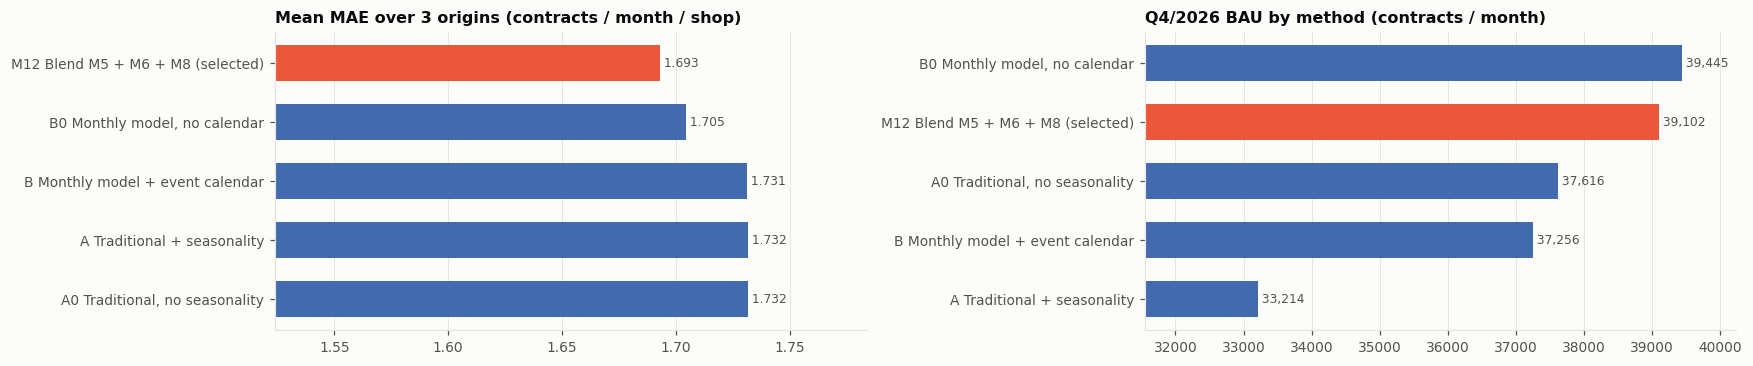

In [13]:
# mùa vụ / sự kiện có giúp không? So cặp có – không, trên từng mốc
cmp = rab.pivot(index='du_bao', columns='phuong_phap', values='MAE')
cmp['A: mùa vụ giúp giảm MAE'] = cmp['A0 Truyền thống, không mùa vụ'] - cmp['A Truyền thống + mùa vụ']
cmp['B: lịch sự kiện giúp giảm MAE'] = cmp['B0 Mô hình tháng, không lịch'] - cmp['B Mô hình tháng + lịch sự kiện']
display(cmp[['A: mùa vụ giúp giảm MAE', 'B: lịch sự kiện giúp giảm MAE']].round(4))
# tầm quan trọng của cờ lịch trong mô hình B (mốc gần nhất)
_, mdlB, featsB = method_B(5, with_cal=True)
imp = pd.Series(mdlB.booster_.feature_importance('gain'), index=featsB); imp = imp / imp.sum()
print('Tỷ trọng đóng góp (gain) của từng đặc trưng trong mô hình B, mốc 2026Q2:'); display(imp.sort_values(ascending=False).round(3).to_frame('gain'))
# dự báo Q4/2026 theo các cách, để đối chiếu với BAU đang chọn
qA0 = method_A(6, list(range(1, 6)), seasonal=False); qA = method_A(6, list(range(1, 6)), seasonal=True)
qB0 = method_B(6, with_cal=False)[0]; qB = method_B(6, with_cal=True)[0]
tri = pd.Series({'A0 Truyền thống, không mùa vụ': qA0.sum(), 'A Truyền thống + mùa vụ': qA.sum(), 'B0 Mô hình tháng, không lịch': qB0.sum(),
                 'B Mô hình tháng + lịch sự kiện': qB.sum(), f'{NAMES[CHOSEN]} (đang chọn)': predict_all(6, list(range(1, 6)))[1][CHOSEN].sum()})
print('BAU Q4/2026 toàn mạng lưới theo từng cách (HĐ/tháng):'); display(tri.round(0).to_frame('BAU Q4/2026'))
fig, ax = plt.subplots(1, 2, figsize=(16, 3.4))
o_ = sab.sort_values('MAE'); y_ = np.arange(len(o_))
ax[0].barh(y_, o_.MAE, color=[C2 if 'đang chọn' in i else C1 for i in o_.index], height=.6); ax[0].set_yticks(y_, [en(i) for i in o_.index]); ax[0].invert_yaxis()
ax[0].set_xlim(o_.MAE.min() * .9, o_.MAE.max() * 1.03); ax[0].grid(axis='y', visible=False); ax[0].set_title('Mean MAE over 3 origins (contracts / month / shop)')
for yi, v in zip(y_, o_.MAE): ax[0].text(v, yi, f' {v:.3f}', va='center', fontsize=8, color=TXT2)
t_ = tri.sort_values(); y2 = np.arange(len(t_))
ax[1].barh(y2, t_.values, color=[C2 if 'đang chọn' in i else C1 for i in t_.index], height=.6); ax[1].set_yticks(y2, [en(i) for i in t_.index])
ax[1].set_xlim(t_.min() * .95, t_.max() * 1.02); ax[1].grid(axis='y', visible=False); ax[1].set_title('Q4/2026 BAU by method (contracts / month)')
for yi, v in zip(y2, t_.values): ax[1].text(v, yi, f' {v:,.0f}', va='center', fontsize=8, color=TXT2)
plt.tight_layout(); plt.show()

> **Kết luận kiểm định chéo (Bước 3c):**
> 1. **Hai cách độc lập cho kết quả gần nhau.** MAE trung bình 3 mốc: M12 1,693 · mô hình tháng B0 1,705 · cách truyền thống A 1,732. Dự báo Q4/2026 của M12 (39,1K) nằm giữa các cách không điều chỉnh mùa vụ (37,6K–39,4K) → BAU **không phụ thuộc vào cách làm**.
> 2. **Lịch sự kiện (Tết, iPhone, 11/11, 12/12) không làm dự báo tốt hơn.** Ở cả 3 mốc, thêm cờ lịch làm MAE tăng 0,004–0,058. Tổng đóng góp của các cờ lịch trong mô hình chỉ khoảng 0,6%. Lý do: mỗi sự kiện mới xảy ra **1 lần** trong 21 tháng dữ liệu.
> 3. **Mùa vụ kiểu truyền thống (cùng kỳ năm trước) không kiểm chứng được.** Cả 3 mốc backtest đều chưa có cùng kỳ năm trước, nên hệ số = 1. Riêng Q4/2026, hệ số lấy từ Q4/Q3 năm 2025 (CD 0,87 · TW 1,19 · NS 0,67) kéo BAU xuống 33,2K. Hệ số này bị chi phối bởi **một lần sụt mạnh tháng 11/2025** (CD −22%, NS −32%) chưa rõ nguyên nhân, nên không đủ tin cậy để đưa vào con số chính.
> 4. **Quyết định:** giữ BAU cơ sở = M12 (không điều chỉnh mùa vụ). Mùa vụ và sự kiện được trình bày ở **kịch bản độ nhạy** (Bước 4). Đề xuất đưa lại cờ lịch vào mô hình khi đã có ≥ 2 năm dữ liệu.
> 5. **Mô hình tháng B0 là phương án thay thế tốt:** MAE gần bằng M12 nhưng ít lệch hơn ở shop ít HĐ (−2% so với −20%). Nhóm có thể nêu B0 như một cách kiểm tra độ vững.

## Bước 3d · Thử thêm 3 kỹ thuật: trọng số theo thời gian, ensemble có trọng số tối ưu, hiệu chỉnh lệch tổng

| Kỹ thuật | Cách làm | Chống "tự chấm điểm" |
|---|---|---|
| **Trọng số theo thời gian** | Khi huấn luyện LightGBM và Random Forest, mốc càng gần càng nặng ký: trọng số giảm một nửa sau mỗi 2 quý. Ghép lại như M12 (cùng làm mượt luỹ thừa) → **M12w** | chỉ dùng các mốc trước thời điểm dự báo |
| **Ensemble có trọng số tối ưu** | Tìm trọng số không âm, tổng = 1, cho các mô hình thành phần (M0, M1, M4, M5, M6, M8, mô hình tháng B0) sao cho MAE nhỏ nhất | trọng số chỉ ước lượng trên các mốc **trước** mốc được chấm |
| **Ensemble tối ưu có ràng buộc** | Như trên, thêm điều kiện: nhóm shop ít HĐ và nhóm shop mới không bị lệch quá ±15% trên các mốc dùng để ước lượng | như trên |
| **Hiệu chỉnh lệch tổng** | Nhân dự báo M12 với hệ số = tổng thực tế ÷ tổng dự báo của các mốc trước | hệ số chỉ lấy từ các mốc trước |

Hai kỹ thuật sau cần ít nhất một mốc trước để ước lượng. Vì vậy **mọi phương pháp được chấm trên 2 mốc dự báo 2026Q2 và 2026Q3**, để so cùng điều kiện.

Trung bình 2 mốc (dự báo 2026Q2, 2026Q3):


,MAE,R2,sai_lech_tong,lech_it_HD
phuong_phap,,,,
Ensemble trọng số tối ưu,1.584,0.811,-0.032,-0.284
Ensemble tối ưu có ràng buộc nhóm (±15%),1.603,0.814,-0.027,-0.094
M12 Kết hợp M5 + M6 + M8,1.619,0.765,-0.025,-0.177
M12w Trọng số theo thời gian,1.619,0.766,-0.027,-0.178
Mô hình tháng B0,1.632,0.803,-0.028,0.000
M12 + hiệu chỉnh lệch tổng,1.648,0.769,0.015,-0.143
M0 Giữ nguyên (baseline),1.695,0.765,-0.026,-0.620


Trọng số tối ưu đã dùng (ước lượng trên các mốc trước):


,2026Q2,2026Q2 (ràng buộc),2026Q3,2026Q3 (ràng buộc)
M0,0.000,0.000,0.000,0.000
M1,0.052,0.000,0.169,0.113
M4,0.000,0.126,0.000,0.063
M5,0.000,0.104,0.004,0.047
M6,0.471,0.191,0.285,0.133
M8,0.000,0.000,0.000,0.000
B0,0.477,0.579,0.543,0.644


So với M12 Kết hợp M5 + M6 + M8 (dương = kém hơn):


,phuong_phap,chenh_MAE,CI95,ket_luan
0,Ensemble trọng số tối ưu,-0.034,[-0.061; -0.013],tốt hơn rõ
1,Ensemble tối ưu có ràng buộc nhóm (±15%),-0.014,[-0.044; +0.010],không khác biệt rõ
2,M12w Trọng số theo thời gian,0.001,[-0.002; +0.003],không khác biệt rõ
3,Mô hình tháng B0,0.017,[-0.018; +0.050],không khác biệt rõ
4,M12 + hiệu chỉnh lệch tổng,0.027,[+0.022; +0.031],kém hơn rõ
5,M0 Giữ nguyên (baseline),0.074,[+0.047; +0.100],kém hơn rõ


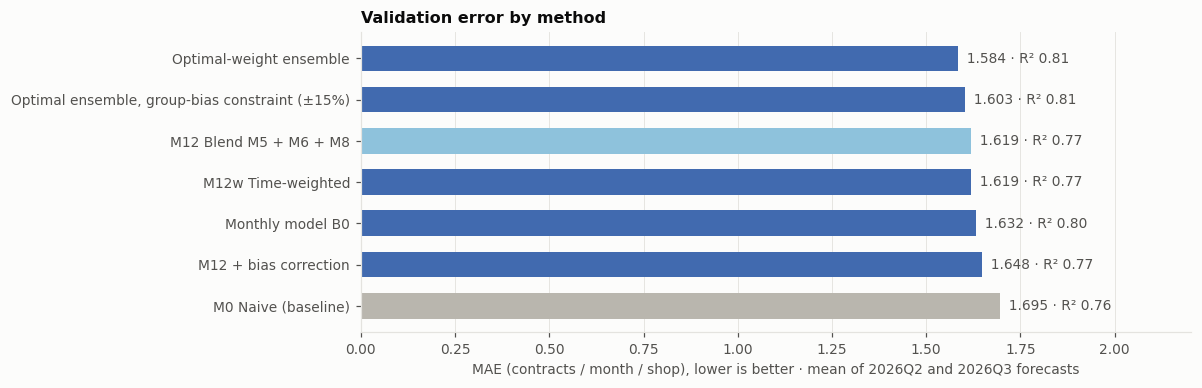

In [14]:
from scipy.optimize import minimize

def fit_weighted(train_T, half_life=2):
    tr = pd.concat([SNAP[t].assign(_t=t) for t in train_T], ignore_index=True)
    w_ = 0.5 ** ((max(train_T) - tr._t) / half_life)
    Xtr = design(tr)
    gb = lgb.LGBMRegressor(n_estimators=400, learning_rate=.03, num_leaves=31, min_child_samples=40, subsample=.8, subsample_freq=1,
                           colsample_bytree=.8, objective='tweedie', verbose=-1).fit(Xtr, tr.y, sample_weight=w_)
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, max_features=.5, n_jobs=-1, random_state=0).fit(Xtr, tr.y, sample_weight=w_)
    return dict(cols=Xtr.columns, gb=gb, rf=rf)

def pred_M12w(T, fw):
    d = SNAP[T]; X = design(d, fw['cols'])
    return (fw['gb'].predict(X) + d.ses.values + fw['rf'].predict(X)) / 3

COMP = ['M0', 'M1', 'M4', 'M5', 'M6', 'M8']
def comp_frame(T):
    d, P = store[T]
    F = P[COMP].copy(); F['B0'] = storeAB[T]['B0 Mô hình tháng, không lịch'].values
    return d, F

def opt_weights(Ts, max_group_bias=None):
    Fs, ys, lo_m, nw_m = [], [], [], []
    for T in Ts:
        d, F = comp_frame(T); Fs.append(F.values); ys.append(d.y.values)
        g_ = groups(d); lo_m.append(g_['Shop ít HĐ (≤ 1/tháng)'].values); nw_m.append(g_['Shop mới (< 6 tháng tuổi)'].values)
    F_ = np.vstack(Fs); y_ = np.concatenate(ys); k = F_.shape[1]
    lo_m = np.concatenate(lo_m); nw_m = np.concatenate(nw_m)
    obj = lambda w: np.mean(np.abs(F_ @ w - y_))
    cons = [{'type': 'eq', 'fun': lambda w: w.sum() - 1}]
    if max_group_bias is not None:                                   # |sai lệch tổng| của nhóm ≤ ngưỡng
        for m_ in (lo_m, nw_m):
            b_ = lambda w, m_=m_: ((F_[m_] @ w).sum() - y_[m_].sum()) / y_[m_].sum()
            cons += [{'type': 'ineq', 'fun': lambda w, b_=b_: max_group_bias - b_(w)}, {'type': 'ineq', 'fun': lambda w, b_=b_: max_group_bias + b_(w)}]
    r_ = minimize(obj, np.ones(k) / k, method='SLSQP', bounds=[(0, 1)] * k, constraints=cons, options={'maxiter': 500})
    return pd.Series(r_.x, index=COMP + ['B0'])

EVAL = [4, 5]
rows3d, W_used = [], {}
for T in EVAL:
    d, P = store[T]; past = [t for t in FOLDS if t < T]
    fw = fit_weighted(list(range(1, T)))
    w_opt = opt_weights(past); W_used[QN(T + 1)] = w_opt
    w_con = opt_weights(past, max_group_bias=.15); W_used[QN(T + 1) + ' (ràng buộc)'] = w_con
    _, F = comp_frame(T)
    cal = np.mean([store[t][0].y.sum() / store[t][1][CHOSEN].sum() for t in past])
    cand_ = {'M0 Giữ nguyên (baseline)': P.M0, f'{NAMES[CHOSEN]}': P[CHOSEN], 'M12w Trọng số theo thời gian': pd.Series(pred_M12w(T, fw), index=d.index),
             'Ensemble trọng số tối ưu': pd.Series(F.values @ w_opt.values, index=d.index),
             'Ensemble tối ưu có ràng buộc nhóm (±15%)': pd.Series(F.values @ w_con.values, index=d.index),
             'M12 + hiệu chỉnh lệch tổng': P[CHOSEN] * cal,
             'Mô hình tháng B0': F.B0}
    g_ = groups(d)['Shop ít HĐ (≤ 1/tháng)']
    for k_, pr_ in cand_.items():
        e = pr_ - d.y
        rows3d.append(dict(phuong_phap=k_, du_bao=QN(T + 1), MAE=e.abs().mean(), R2=1 - (e ** 2).sum() / ((d.y - d.y.mean()) ** 2).sum(),
                           sai_lech_tong=e.sum() / d.y.sum(), lech_it_HD=e[g_].sum() / d.y[g_].sum(), _ae=e.abs().values))
r3d = pd.DataFrame(rows3d)
s3d = r3d.groupby('phuong_phap')[['MAE', 'R2', 'sai_lech_tong', 'lech_it_HD']].mean().sort_values('MAE')
print('Trung bình 2 mốc (dự báo 2026Q2, 2026Q3):'); display(s3d.round(3))
print('Trọng số tối ưu đã dùng (ước lượng trên các mốc trước):'); display(pd.DataFrame(W_used).round(3))
# kiểm định: chênh MAE so với mô hình đang chọn, bootstrap theo shop, gộp 2 mốc
ref_ae = np.concatenate(r3d[r3d.phuong_phap == NAMES[CHOSEN]]._ae.values)
rng_c = np.random.default_rng(3); idx_c = rng_c.integers(0, len(ref_ae), size=(500, len(ref_ae))); tt = []
for k_ in s3d.index:
    if k_ == NAMES[CHOSEN]: continue
    dd_ = np.concatenate(r3d[r3d.phuong_phap == k_]._ae.values) - ref_ae
    lo_, hi_ = np.percentile(dd_[idx_c].mean(axis=1), [2.5, 97.5])
    tt.append(dict(phuong_phap=k_, chenh_MAE=dd_.mean(), CI95=f'[{lo_:+.3f}; {hi_:+.3f}]',
                   ket_luan='kém hơn rõ' if lo_ > 0 else ('tốt hơn rõ' if hi_ < 0 else 'không khác biệt rõ')))
print(f'So với {NAMES[CHOSEN]} (dương = kém hơn):'); display(pd.DataFrame(tt).round(4))

# biểu đồ kiểu "MAE · R²", baseline màu xám
o_ = s3d.sort_values('MAE', ascending=False)
fig, ax = plt.subplots(figsize=(11, 3.6)); y_ = np.arange(len(o_))
cols_ = ['#b9b6ae' if 'baseline' in i else (C3 if i == NAMES[CHOSEN] else C1) for i in o_.index]
ax.barh(y_, o_.MAE, color=cols_, height=.62); ax.set_yticks(y_, [en(i) for i in o_.index]); ax.grid(axis='y', visible=False)
for yi, (m_, r2_) in enumerate(zip(o_.MAE, o_.R2)): ax.text(m_, yi, f'  {m_:.3f} · R² {r2_:.2f}', va='center', fontsize=9, color=TXT2)
ax.set_xlim(0, o_.MAE.max() * 1.3); ax.set_xlabel('MAE (contracts / month / shop), lower is better · mean of 2026Q2 and 2026Q3 forecasts')
ax.set_title('Validation error by method'); plt.tight_layout(); plt.show()

> **Kết luận Bước 3d** (chấm trên dự báo 2026Q2 và 2026Q3):
> - **Trọng số theo thời gian:** không khác M12. Mạng lưới thay đổi nhanh nhưng mô hình đã tự học được qua các đặc trưng tuổi shop và xu hướng gần nhất.
> - **Hiệu chỉnh lệch tổng:** làm MAE **kém hơn rõ** (+0,027). Lệch tổng của các mốc trước không ổn định nên không dùng để hiệu chỉnh được.
> - **Ensemble tối ưu không ràng buộc:** MAE thấp nhất (1,584; R² 0,81). Nhưng trọng số dồn hết cho làm mượt luỹ thừa và mô hình tháng, nên **dự báo thấp 28% ở nhóm shop ít HĐ**: vi phạm tiêu chí không lệch theo nhóm.
> - **Ensemble tối ưu có ràng buộc ±15%:** MAE 1,603, R² 0,81, nhóm shop ít HĐ chỉ lệch −9%. Tuy nhiên chênh lệch MAE với M12 **không có ý nghĩa thống kê**, và trọng số thay đổi khá nhiều giữa 2 mốc (mô hình tháng B0 nặng 58–64%) vì chỉ ước lượng trên 1–2 mốc.
> - **Quyết định:** giữ **M12 (trung bình đều 3 mô hình)** làm BAU chính, vì đơn giản, ổn định, và không mô hình nào thắng rõ đồng thời ở MAE và ở độ lệch theo nhóm. **Ensemble có ràng buộc** là hướng cải tiến khi có thêm mốc dữ liệu để ước lượng trọng số ổn định hơn.

## Bước 4 · Dự báo Q4/2026: con số điểm và khoảng bất định
- **Con số điểm:** phương pháp đã chọn, huấn luyện trên mọi mốc đến 2026Q2. Mốc dự báo là cuối Q3/2026.
- **Khoảng P10–P90 từng shop:**
  - Lấy phân vị 10% và 90% của sai số backtest, theo nhóm (mức HĐ dự báo × shop mới/trưởng thành).
  - Không cho dưới 0 HĐ.
  - Kiểm tra theo kiểu **bỏ-một-mốc**: khoảng của mốc này dựng từ sai số của 2 mốc kia. Đo độ bao phủ (mục tiêu ≈ 80%) và độ rộng.
- **Khoảng của toàn mạng lưới (Monte Carlo)** (mô phỏng chỉ dùng để lấy độ rộng; khoảng được canh quanh con số điểm): mỗi lần mô phỏng gồm hai phần:
  - một **cú sốc chung** cho mọi shop, lấy theo sai lệch tổng đã thấy ở các mốc backtest;
  - **sai số riêng** của từng shop, rút từ sai số backtest đã trừ phần chung.

  Không giả định các shop độc lập hoàn toàn, vì như vậy khoảng của mạng lưới sẽ hẹp quá mức.

In [15]:
def pband(p, d):
    pb_ = pd.cut(p, [-1, .5, 1, 3, 10, 1e9], labels=['≤0,5', '(0,5–1]', '(1–3]', '(3–10]', '>10']).astype(str)
    return pb_ + np.where(d.age < 6, ' · mới', ' · trưởng thành')
R = []
for T in FOLDS:
    d, P = store[T]
    r_ = pd.DataFrame({'T': T, 'band': pband(P[CHOSEN], d), 'e': d.y - P[CHOSEN]}, index=d.index)
    r_['e_dm'] = r_.e - r_.e.mean()                       # bỏ phần chung của mốc
    R.append(r_)
R = pd.concat(R)
cov = []
for T in FOLDS:
    d, P = store[T]
    oth = R[R['T'] != T]
    q = oth.groupby('band').e.quantile([.1, .9]).unstack()
    b = pband(P[CHOSEN], d)
    lo = (P[CHOSEN] + b.map(q[.1]).fillna(oth.e.quantile(.1))).clip(lower=0)
    hi = (P[CHOSEN] + b.map(q[.9]).fillna(oth.e.quantile(.9))).clip(lower=0)
    cov.append(dict(du_bao=QN(T + 1), bao_phu=((d.y >= lo) & (d.y <= hi)).mean(), do_rong_TB=(hi - lo).mean(), muc_HD_TB=d.y.mean()))
print('Kiểm tra khoảng P10–P90 từng shop (bỏ-một-mốc):'); display(pd.DataFrame(cov).round(3))

T_NOW = 6
d_now, P_now = predict_all(T_NOW, list(range(1, T_NOW)))
d_now['bau'] = P_now[CHOSEN]
for m in MODELS: d_now['pred_' + m] = P_now[m]
qq = R.groupby('band').e.quantile([.1, .9]).unstack()
bnow = pband(d_now.bau, d_now)
d_now['bau_p10'] = (d_now.bau + bnow.map(qq[.1]).fillna(R.e.quantile(.1))).clip(lower=0)
d_now['bau_p90'] = (d_now.bau + bnow.map(qq[.9]).fillna(R.e.quantile(.9))).clip(lower=0)
d_now['surv_frac'] = survival_frac(list(range(1, T_NOW)), d_now)

# Monte Carlo toàn mạng lưới
rng = np.random.default_rng(0)
fold_rel = res[res.model == CHOSEN].sai_lech_tong.values           # sai lệch tổng của 3 mốc
sd_common = np.std(fold_rel, ddof=1)
pool = {b: g.e_dm.values for b, g in R.groupby('band')}
base = d_now.bau.values
idx_by_band = {b: np.flatnonzero(bnow.values == b) for b in np.unique(bnow.values)}
sims = np.empty(2000)
for k in range(len(sims)):
    c = rng.normal(0, sd_common)                                     # cú sốc chung của cả mạng lưới
    e = np.empty(len(base))
    for b, ix in idx_by_band.items():                                # sai số riêng của shop, rút theo nhóm
        e[ix] = rng.choice(pool.get(b, R.e_dm.values), size=len(ix))
    sims[k] = np.clip(base * (1 - c) + e, 0, None).sum()
# lấy độ rộng từ mô phỏng, canh quanh con số điểm (cắt số âm về 0 ở shop nhỏ làm tổng mô phỏng lệch lên)
med = np.percentile(sims, 50)
net = dict(diem=base.sum(), P10=base.sum() + np.percentile(sims, 10) - med, P50=base.sum(), P90=base.sum() + np.percentile(sims, 90) - med)
print(f"Cú sốc chung: độ lệch chuẩn sai lệch tổng của 3 mốc = {sd_common:.1%} (chỉ 3 mốc → ước lượng thô)")
print(f"BAU Q4/2026 toàn mạng lưới ({len(d_now):,} shop đang mở cuối Q3): {net['diem']:,.0f} HĐ/tháng · "
      f"P10 {net['P10']:,.0f} – P50 {net['P50']:,.0f} – P90 {net['P90']:,.0f} · Current Q3 {d_now.cur.sum():,.0f}")

Kiểm tra khoảng P10–P90 từng shop (bỏ-một-mốc):


,du_bao,bao_phu,do_rong_TB,muc_HD_TB
0,2026Q1,0.777,4.651,3.199
1,2026Q2,0.818,4.942,3.088
2,2026Q3,0.798,4.507,3.283


Cú sốc chung: độ lệch chuẩn sai lệch tổng của 3 mốc = 6.0% (chỉ 3 mốc → ước lượng thô)
BAU Q4/2026 toàn mạng lưới (11,922 shop đang mở cuối Q3): 39,102 HĐ/tháng · P10 36,262 – P50 39,102 – P90 41,945 · Current Q3 39,392


### Kịch bản độ nhạy (trình bày riêng, **không** phải P10/P90)
Mỗi kịch bản thay **một giả định** so với kịch bản cơ sở:

| Kịch bản | Giả định thay đổi |
|---|---|
| **Cơ sở** | phương pháp đã chọn |
| **Có mùa vụ** | nhân hệ số Q4/Q3 của năm 2025 trên cùng tập shop, theo dòng hàng. Chỉ có 1 năm quan sát |
| **Xu hướng tiếp diễn** | dùng M2: độ dốc 6 tháng của shop, co về phân khúc |
| **Đóng cửa nhiều hơn** | xác suất đóng mỗi tháng × 1,5 |
| **Đóng cửa ít hơn** | xác suất đóng mỗi tháng × 0,5 |

Hệ số mùa vụ Q4/Q3 2025: {'CD': 0.918, 'NS': 0.778, 'TW': 1.231}


,HĐ/tháng,so với cơ sở
Cơ sở,"39,101.913",0.000
Có mùa vụ (Q4/Q3 2025),"37,016.075",-0.053
Xu hướng tiếp diễn (M2),"41,814.969",0.069
"Đóng cửa nhiều hơn (× 1,5)","38,407.489",-0.018
"Đóng cửa ít hơn (× 0,5)","39,809.544",0.018


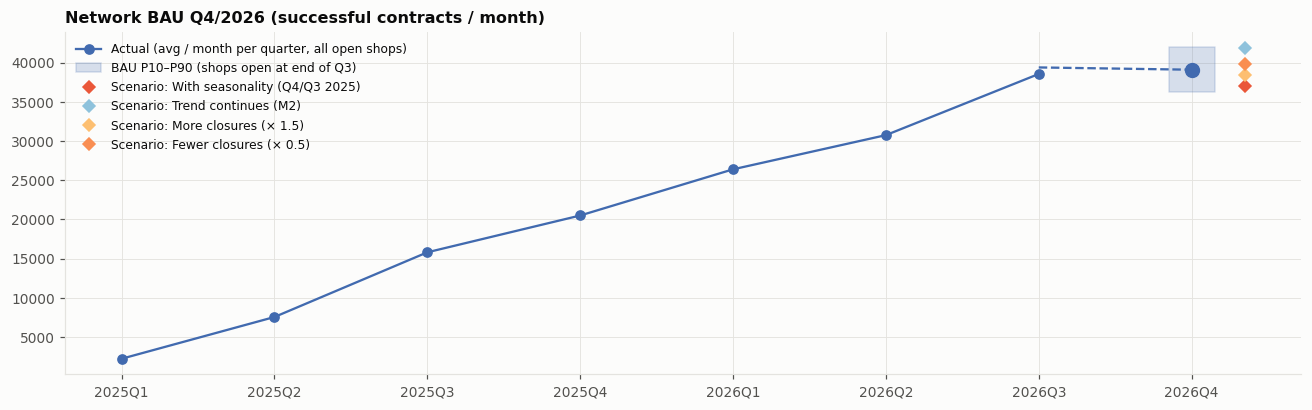

In [16]:
# hệ số mùa vụ Q4/Q3 2025 theo dòng hàng, cùng tập shop mở đủ cả 2 quý
q3, q4 = QM[2], QM[3]
full = OPEN[q3 + q4].all(axis=1)
ss = Y.loc[full, q4].sum(axis=1).groupby(shops.loc[full[full].index, 'line']).sum() / Y.loc[full, q3].sum(axis=1).groupby(shops.loc[full[full].index, 'line']).sum()
sf = d_now.surv_frac
def closure_adj(mult):
    # số tháng còn mở kỳ vọng khi hazard tháng × mult (xấp xỉ từ tỷ lệ còn mở trung bình)
    h = 1 - (sf ** (1 / 2))                       # hazard/tháng xấp xỉ
    h2 = (h * mult).clip(0, 1)
    f2 = ((1 - h2) + (1 - h2) ** 2 + (1 - h2) ** 3) / 3
    f1 = ((1 - h) + (1 - h) ** 2 + (1 - h) ** 3) / 3
    return f2 / f1.replace(0, np.nan)
SCN = {'Cơ sở': d_now.bau,
       'Có mùa vụ (Q4/Q3 2025)': d_now.bau * d_now.line.map(ss),
       'Xu hướng tiếp diễn (M2)': d_now.pred_M2,
       'Đóng cửa nhiều hơn (× 1,5)': d_now.bau * closure_adj(1.5).fillna(1),
       'Đóng cửa ít hơn (× 0,5)': d_now.bau * closure_adj(.5).fillna(1)}
scn = pd.DataFrame({k: [v.sum(), v.sum() / d_now.bau.sum() - 1] for k, v in SCN.items()}, index=['HĐ/tháng', 'so với cơ sở']).T
print('Hệ số mùa vụ Q4/Q3 2025:', ss.round(3).to_dict()); display(scn.round(3))

# biểu đồ: lịch sử toàn mạng lưới + BAU + khoảng + kịch bản
hist_tot = pd.Series({m: Y.loc[OPEN[m], m].sum() for m in MONTHS})
q_tot = hist_tot.groupby([qidx(m) for m in MONTHS]).mean()
SCN_EN = {'Có mùa vụ (Q4/Q3 2025)': 'With seasonality (Q4/Q3 2025)', 'Xu hướng tiếp diễn (M2)': 'Trend continues (M2)',
          'Đóng cửa nhiều hơn (× 1,5)': 'More closures (× 1.5)', 'Đóng cửa ít hơn (× 0,5)': 'Fewer closures (× 0.5)'}
fig, ax = plt.subplots(figsize=(12, 3.8))
xq = list(range(7)); ax.plot(xq, q_tot.values, color=C1, marker='o', label='Actual (avg / month per quarter, all open shops)')
ax.plot([6, 7], [d_now.cur.sum(), net['diem']], color=C1, ls='--')
ax.fill_between([7 - .15, 7 + .15], net['P10'], net['P90'], color=C1, alpha=.2, label='BAU P10–P90 (shops open at end of Q3)')
ax.plot(7, net['diem'], 'o', color=C1, ms=9)
for i, (k, v) in enumerate(SCN.items()):
    if k == 'Cơ sở': continue
    ax.plot(7.35, v.sum(), 'D', color=[C2, C3, C4, C5][i - 1], ms=6, label=f'Scenario: {SCN_EN[k]}')
ax.set_xticks(range(8), [QN(q) for q in range(8)]); ax.set_title('Network BAU Q4/2026 (successful contracts / month)')
ax.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()

## Bước 4b · Góc nhìn 6 tháng (Q4/2026 + Q1/2027)
**Vì sao có thêm góc nhìn này:** can thiệp cần 1–2 quý mới có hiệu quả. Để so **Attainable − BAU** công bằng, cả hai phải đo trên cùng 6 tháng.

| | Định nghĩa |
|---|---|
| **Chỉ tiêu** | HĐ thành công **bình quân/tháng trong 6 tháng tới** = tổng 2 quý ÷ 6; gồm cả HĐ trước khi shop đóng |
| **Backtest** | chỉ có **2 mốc**: cuối 2025Q4 → 2026Q1+Q2 và cuối 2026Q1 → 2026Q2+Q3. Mỗi mốc chỉ huấn luyện trên các mốc mà 6 tháng sau đó **đã kết thúc** tại thời điểm dự báo |
| **Phương pháp** | giữ phương pháp đã chọn ở dự báo 1 quý để nhất quán; bảng dưới kiểm tra lại nó so với các ứng viên |
| **Tết (Q1/2027)** | chỉ quan sát được 1 lần chuyển Q4 → Q1, nên mùa vụ Tết chỉ đưa vào **kịch bản** |

In [17]:
FOLDS6 = [3, 4]
res6, store6 = [], {}
for T in FOLDS6:
    d6, P6 = predict_all(T, list(range(1, T - 1)), h=2)
    store6[T] = (d6, P6)
    for m in MODELS:
        e = P6[m] - d6.y2
        res6.append(dict(moc=QN(T), du_bao=f'{QN(T + 1)}+{QN(T + 2)}', model=m, MAE=e.abs().mean(),
                         sai_lech_tong=e.sum() / d6.y2.sum(), spearman=spearmanr(P6[m], d6.y2).statistic))
res6 = pd.DataFrame(res6)
display(res6.pivot(index='model', columns='du_bao', values=['MAE', 'sai_lech_tong']).rename(index=NAMES).round(3))
s6 = res6.groupby('model')[['MAE', 'sai_lech_tong']].mean()
print(f"Phương pháp đã chọn ({NAMES[CHOSEN]}) ở tầm 6 tháng: MAE {s6.loc[CHOSEN, 'MAE']:.3f} "
      f"(tốt nhất: {NAMES[s6.MAE.idxmin()]} {s6.MAE.min():.3f}); sai lệch tổng TB {s6.loc[CHOSEN, 'sai_lech_tong']:+.1%}")

# dự báo 6 tháng từ mốc cuối Q3/2026
d6n, P6n = predict_all(6, [1, 2, 3, 4], h=2)
R6 = []
for T in FOLDS6:
    d6, P6 = store6[T]
    r_ = pd.DataFrame({'T': T, 'band': pband(P6[CHOSEN], d6), 'e': d6.y2 - P6[CHOSEN]}, index=d6.index)
    r_['e_dm'] = r_.e - r_.e.mean(); R6.append(r_)
R6 = pd.concat(R6)
cov6 = []
for T in FOLDS6:
    d6, P6 = store6[T]; oth = R6[R6['T'] != T]; q_ = oth.groupby('band').e.quantile([.1, .9]).unstack(); b_ = pband(P6[CHOSEN], d6)
    lo = (P6[CHOSEN] + b_.map(q_[.1]).fillna(oth.e.quantile(.1))).clip(lower=0); hi = (P6[CHOSEN] + b_.map(q_[.9]).fillna(oth.e.quantile(.9))).clip(lower=0)
    cov6.append(dict(du_bao=f'{QN(T + 1)}+{QN(T + 2)}', bao_phu=((d6.y2 >= lo) & (d6.y2 <= hi)).mean(), do_rong_TB=(hi - lo).mean()))
print('Kiểm tra khoảng P10–P90 từng shop, tầm 6 tháng (bỏ-một-mốc):'); display(pd.DataFrame(cov6).round(3))
q6 = R6.groupby('band').e.quantile([.1, .9]).unstack(); b6 = pband(P6n[CHOSEN], d6n)
d_now['bau6'] = P6n[CHOSEN].reindex(d_now.index)
d_now['bau6_p10'] = (d_now.bau6 + b6.map(q6[.1]).reindex(d_now.index).fillna(R6.e.quantile(.1))).clip(lower=0)
d_now['bau6_p90'] = (d_now.bau6 + b6.map(q6[.9]).reindex(d_now.index).fillna(R6.e.quantile(.9))).clip(lower=0)
# khoảng toàn mạng lưới: cú sốc chung từ 2 mốc + sai số riêng
sd6 = np.std(res6[res6.model == CHOSEN].sai_lech_tong.values, ddof=1)
pool6 = {b: g.e_dm.values for b, g in R6.groupby('band')}; base6 = d_now.bau6.values
ix6 = {b: np.flatnonzero(b6.reindex(d_now.index).values == b) for b in np.unique(b6.values)}
sims6 = np.empty(2000)
for k in range(len(sims6)):
    c = rng.normal(0, sd6); e = np.empty(len(base6))
    for b, ix in ix6.items(): e[ix] = rng.choice(pool6.get(b, R6.e_dm.values), size=len(ix))
    sims6[k] = np.clip(base6 * (1 - c) + e, 0, None).sum()
med6 = np.median(sims6)
net6 = dict(diem=base6.sum(), P10=base6.sum() + np.percentile(sims6, 10) - med6, P90=base6.sum() + np.percentile(sims6, 90) - med6)
# kịch bản mùa vụ Q4 + Tết: hệ số Q4/Q3 2025 và Q1 2026/Q4 2025 trên cùng tập shop
q1 = QM[4]; full2 = OPEN[q4 + q1].all(axis=1); ids2 = full2[full2].index
s1 = Y.loc[ids2, q1].sum(axis=1).groupby(shops.loc[ids2, 'line']).sum() / Y.loc[ids2, q4].sum(axis=1).groupby(shops.loc[ids2, 'line']).sum()
seas6 = d_now.bau6 * d_now.line.map((ss + ss * s1) / 2)
print(f"Hệ số Q1/Q4 (Tết, 1 lần quan sát): {s1.round(3).to_dict()}")
print(f"BAU 6 tháng (bình quân/tháng Q4/2026–Q1/2027): {net6['diem']:,.0f} HĐ/tháng · P10 {net6['P10']:,.0f} – P90 {net6['P90']:,.0f} "
      f"(độ lệch chung {sd6:.1%}, chỉ 2 mốc) · kịch bản có mùa vụ Q4 + Tết: {seas6.sum():,.0f} · BAU 1 quý: {d_now.bau.sum():,.0f}")

MAE               sai_lech_tong              
du_bao                                             2026Q1+2026Q2 2026Q2+2026Q3 2026Q1+2026Q2 2026Q2+2026Q3
model                                                                                                     
D1 Yếu tố: hồ sơ hiện tại × chuyển đổi × tháng ...         1.845         1.720        -0.088        -0.062
D2 Yếu tố: hồ sơ dự báo × chuyển đổi                       1.845         1.720        -0.088        -0.062
M0 Giữ nguyên                                              1.906         1.807        -0.022         0.038
M1 × tháng còn mở                                          1.848         1.736        -0.081        -0.038
M10 Kết hợp M5 + M6                                        1.834         1.686        -0.014         0.000
M11 Kết hợp M4 + M6                                        1.914         1.715         0.051         0.032
M12 Kết hợp M5 + M6 + M8                                   1.879         1.708         0.029         0.005
M13 Run-rate 6 tháng × ½ tăng trưởng nhóm                  1.956         1.849         0.002         0.055
M13 × tháng còn mở                                         1.889         1.778        -0.060        -0.023
M2 Xu hướng co về phân khúc                                2.326         2.262         0.113         0.193
M3 Hồi quy chung                                           2.175         1.894         0.171        -0.014
M4 Poisson                                                 2.128         1.843         0.140         0.027
M5 LightGBM                                                1.982         1.795         0.009        -0.037
M6 Làm mượt luỹ thừa                                       1.827         1.730        -0.038         0.037
M7 Ridge                                                   2.253         2.169         0.112         0.092
M8 Random Forest                                           2.032         1.798         0.117         0.015
M9 Kết hợp M1 + M5                                         1.832         1.676        -0.036        -0.037

Phương pháp đã chọn (M12 Kết hợp M5 + M6 + M8) ở tầm 6 tháng: MAE 1.794 (tốt nhất: M9 Kết hợp M1 + M5 1.754); sai lệch tổng TB +1.7%


Kiểm tra khoảng P10–P90 từng shop, tầm 6 tháng (bỏ-một-mốc):


,du_bao,bao_phu,do_rong_TB
0,2026Q1+2026Q2,0.772,4.781
1,2026Q2+2026Q3,0.818,4.578


Hệ số Q1/Q4 (Tết, 1 lần quan sát): {'CD': 1.077, 'NS': 0.834, 'TW': 1.021}
BAU 6 tháng (bình quân/tháng Q4/2026–Q1/2027): 37,517 HĐ/tháng · P10 36,508 – P90 38,546 (độ lệch chung 1.7%, chỉ 2 mốc) · kịch bản có mùa vụ Q4 + Tết: 35,843 · BAU 1 quý: 39,102


### Đối chiếu: vì sao cách "run-rate 6 tháng × ½ tăng trưởng nhóm" có thể cho BAU cao hơn Current?
Cách M13 (một cách làm phổ biến, ví dụ đội khác báo BAU **+12%** so với Current) khác cách của notebook này ở 3 điểm:

1. **Phạm vi shop:** chỉ gồm shop mở đủ 6 tháng, hay mọi shop đang mở (kể cả shop mới, shop sắp đóng).
2. **Có tính shop ngừng hoạt động hay không.**
3. **Đơn vị và kỳ:** giá trị tiền đã khử mùa vụ trong 6 tháng, hay số HĐ trong 1 quý.

Bảng dưới đo điểm 1 và 2 trên cùng dữ liệu (HĐ/tháng). Điểm 3 không đo lại được ở đây.

In [18]:
dd_ = d_now
full = (dd_.act_T == 3) & dd_.prev.notna() & (dd_.age >= 6)
rows_r = []
for lab, msk in [('Mọi shop đang mở cuối Q3', dd_.index == dd_.index), ('Chỉ shop mở đủ Q2–Q3 và ≥ 6 tháng tuổi', full)]:
    rows_r.append({'Phạm vi': lab, 'shop': msk.sum(), 'Current Q3': dd_.cur[msk].sum(), 'Run-rate 6 tháng': dd_.run6[msk].sum(),
                   'M13 (không tính đóng cửa)': P_now.M13[msk].sum(), 'M14 (có tính đóng cửa)': P_now.M14[msk].sum(),
                   f'BAU chọn ({CHOSEN})': dd_.bau[msk].sum()})
rr_ = pd.DataFrame(rows_r).set_index('Phạm vi')
print('Tổng HĐ/tháng:'); display(rr_.round(0))
print('So với Current Q3:'); display((rr_.iloc[:, 2:].div(rr_['Current Q3'], axis=0) - 1).style.format('{:+.1%}'))

Tổng HĐ/tháng:


,shop,Current Q3,Run-rate 6 tháng,M13 (không tính đóng cửa),M14 (có tính đóng cửa),BAU chọn (M12)
Phạm vi,,,,,,
Mọi shop đang mở cuối Q3,11922,"39,392.000","38,060.000","39,501.000","38,082.000","39,102.000"
Chỉ shop mở đủ Q2–Q3 và ≥ 6 tháng tuổi,7585,"25,898.000","25,589.000","25,909.000","24,825.000","24,597.000"


So với Current Q3:


,Run-rate 6 tháng,M13 (không tính đóng cửa),M14 (có tính đóng cửa),BAU chọn (M12)
Phạm vi,,,,
Mọi shop đang mở cuối Q3,-3.4%,+0.3%,-3.3%,-0.7%
Chỉ shop mở đủ Q2–Q3 và ≥ 6 tháng tuổi,-1.2%,+0.0%,-4.1%,-5.0%


## Bước 5 · Giải thích từng shop: BAU tăng hay giảm vì đâu?
Mỗi shop được gắn **quỹ đạo** (từ 3 quý gần nhất) và **lý do chính** khiến BAU khác mức hiện tại:

Xét theo thứ tự, dừng ở điều kiện đầu tiên thoả:

| Lý do | Điều kiện |
|---|---|
| **Ổn định** | BAU lệch hiện tại ≤ 10% |
| **Tháng gần nhất không phát sinh HĐ** | quý hiện tại có HĐ nhưng tháng cuối = 0 và BAU < hiện tại (tín hiệu ngừng sớm) |
| **Đang trưởng thành** | shop < 6 tháng tuổi và BAU > hiện tại |
| **Rủi ro ngừng hoạt động cao** | thuộc 10% shop có số tháng còn mở kỳ vọng thấp nhất và BAU < hiện tại |
| **Xu hướng giảm** | quỹ đạo giảm / ngừng phát sinh và BAU < hiện tại |
| **Xu hướng tăng** | quỹ đạo tăng và BAU > hiện tại |
| **Hồi phục từ mức rất thấp** | đang ≤ 1 HĐ/tháng và BAU > hiện tại (shop rất thấp thường nhích lên) |
| **Hồi về mức chung** | đang ≥ 10 HĐ/tháng và BAU < hiện tại (shop rất cao thường giảm bớt) |

In [19]:
d = d_now
def traj(r):
    c, p, p2 = r.cur, r.prev, r.prev2
    if np.isnan(p): return 'Mới mở'
    if c == 0 and p == 0: return 'Chưa / không phát sinh'
    if c == 0: return 'Ngừng phát sinh'
    if p >= 1 and c < .7 * p: return 'Giảm'
    if c > 1.15 * max(p, .34): return 'Tăng'
    return 'Đều'
d['quy_dao'] = d.apply(traj, axis=1)
diff = d.bau - d.cur
low_surv = d.surv_frac <= d.surv_frac.quantile(.1)
d['ly_do'] = np.select([diff.abs() <= .1 * d.cur.clip(lower=.3),
                        (d.last_m == 0) & (d.cur >= 1) & (diff < 0),
                        (d.age < 6) & (diff > 0),
                        low_surv & (diff < 0),
                        d.quy_dao.isin(['Giảm', 'Ngừng phát sinh']) & (diff < 0),
                        (d.quy_dao == 'Tăng') & (diff > 0),
                        (d.cur <= 1) & (diff > 0),
                        (d.cur >= 10) & (diff < 0)],
                       ['Ổn định', 'Tháng gần nhất không phát sinh HĐ', 'Đang trưởng thành', 'Rủi ro ngừng hoạt động cao', 'Xu hướng giảm', 'Xu hướng tăng',
                        'Hồi phục từ mức rất thấp', 'Hồi về mức chung (đang rất cao)'], 'Biến động khác')
tb = d.groupby('ly_do').agg(shop=('bau', 'size'), current=('cur', 'sum'), bau=('bau', 'sum'))
tb['thay_doi'] = tb.bau - tb.current
display(tb.sort_values('shop', ascending=False).round(1))
display(pd.crosstab(d.quy_dao, d.seg, values=d.bau - d.cur, aggfunc='mean').round(2))

,shop,current,bau,thay_doi
ly_do,,,,
Hồi phục từ mức rất thấp,3477,507.700,"1,147.000",639.400
Đang trưởng thành,3067,"4,498.200","6,606.300","2,108.100"
Ổn định,2296,"15,088.700","14,916.600",-172.000
Biến động khác,1582,"6,132.200","5,848.800",-283.400
Tháng gần nhất không phát sinh HĐ,443,"1,021.200",602.300,-418.900
Xu hướng tăng,342,768.300,936.000,167.700
Rủi ro ngừng hoạt động cao,340,"3,255.300","2,556.600",-698.700
Hồi về mức chung (đang rất cao),330,"7,668.500","6,143.600","-1,524.900"
Xu hướng giảm,45,452.300,344.700,-107.600


seg,CD · Aldi,CD · Non-Aldi,NS · Aldi,TW · Non-Aldi
quy_dao,,,,
Chưa / không phát sinh,0.070,0.100,0.080,0.120
Giảm,7.230,0.330,0.160,0.400
Mới mở,2.630,0.800,0.510,0.820
Ngừng phát sinh,NaN,0.260,0.220,0.270
Tăng,1.900,-0.600,-0.850,-0.450
Đều,-3.290,-0.230,-0.330,-0.200


,Shop X,Shop Y
phân khúc,TW · Non-Aldi,NS · Aldi
loại đối tác,TW Key Dealer,Stone Shop
tuổi (tháng),10,16
HĐ/tháng Q1,6.333,17.000
HĐ/tháng Q2,8.000,14.333
HĐ/tháng Q3 (Current),11.333,11.000
HĐ tháng 09/2026,21.000,0.000
quỹ đạo,Tăng,Đều
tháng còn mở kỳ vọng / 3,0.976,0.913
BAU Q4,13.577,3.348


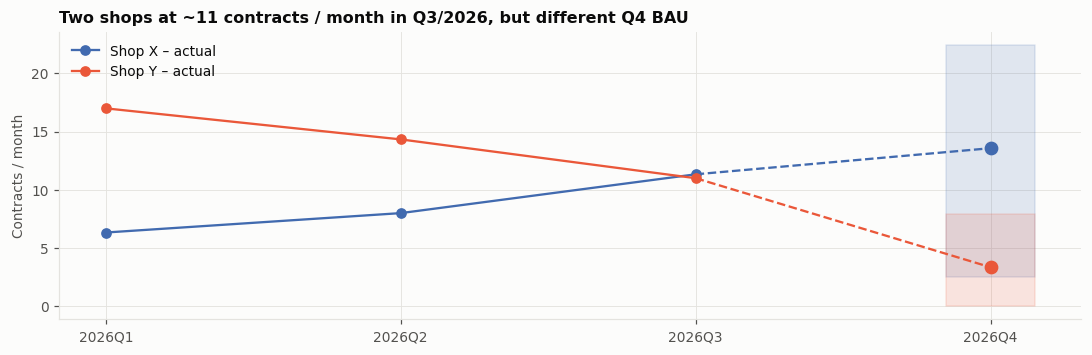

In [20]:
# ví dụ 2 shop cùng mức hiện tại, BAU khác nhau
m_ = d[(d.age >= 6) & d.cur.between(4, 12)].assign(cb=lambda x: x.cur.round(0))
grp = m_.groupby('cb').bau.agg(['size', 'max', 'min'])
cb_ = (grp['max'] - grp['min'])[grp['size'] >= 5].idxmax()
g = m_[m_.cb == cb_]; X, Z = g.loc[g.bau.idxmax()], g.loc[g.bau.idxmin()]
ex = pd.DataFrame({'Shop X': X, 'Shop Y': Z}).loc[['seg', 'seller_type', 'age', 'prev2', 'prev', 'cur', 'last_m', 'quy_dao', 'surv_frac', 'bau', 'bau_p10', 'bau_p90', 'ly_do']]
ex.index = ['phân khúc', 'loại đối tác', 'tuổi (tháng)', 'HĐ/tháng Q1', 'HĐ/tháng Q2', 'HĐ/tháng Q3 (Current)', 'HĐ tháng 09/2026', 'quỹ đạo',
            'tháng còn mở kỳ vọng / 3', 'BAU Q4', 'BAU P10', 'BAU P90', 'lý do chính']
display(ex)
fig, ax = plt.subplots(figsize=(10, 3.3))
for sid, c_, lab in [(X.name, C1, 'Shop X'), (Z.name, C2, 'Shop Y')]:
    h = [SNAP[t].loc[sid, 'cur'] if sid in SNAP[t].index else np.nan for t in range(4, 7)]
    ax.plot([4, 5, 6], h, color=c_, marker='o', label=f'{lab} – actual')
    ax.plot([6, 7], [h[-1], d.loc[sid, 'bau']], color=c_, ls='--')
    ax.fill_between([6.85, 7.15], d.loc[sid, 'bau_p10'], d.loc[sid, 'bau_p90'], color=c_, alpha=.15)
    ax.plot(7, d.loc[sid, 'bau'], 'o', color=c_, ms=8)
ax.set_xticks([4, 5, 6, 7], [QN(q) for q in [4, 5, 6, 7]]); ax.set_ylabel('Contracts / month'); ax.legend(loc='upper left')
ax.set_title(f'Two shops at ~{cb_:.0f} contracts / month in Q3/2026, but different Q4 BAU'); plt.tight_layout(); plt.show()

## Bước 5a · Từ số HĐ sang số tiền

**Vì sao dự báo số HĐ rồi mới quy ra tiền, thay vì dự báo thẳng số tiền?**

```
Giá trị khoản vay BAU = Số HĐ BAU (dự báo cho từng shop) × Khoản vay bình quân (dự báo theo phân khúc)
```

| | Lý do |
|---|---|
| **Số HĐ ổn định và gắn với hoạt động của shop** | tách được thành hồ sơ × tỷ lệ chuyển đổi (Bước 5c), nên khi lệch biết lệch ở khâu nào: thiếu khách, bị từ chối hay khách huỷ |
| **Số tiền của một shop rất nhiễu** | khoản vay có đuôi dài, thẻ (CC) luôn = 0, BNPL đổi cách ghi nhận. Một HĐ xe máy 30 triệu có thể làm cả quý của một shop nhỏ nhảy vọt |
| **Khoản vay bình quân do công ty quyết định nhiều hơn do shop** | chủ yếu phụ thuộc cơ cấu sản phẩm và chính sách, nên dự báo ở cấp **phân khúc**, không ở cấp từng shop |
| **Ban quản lý nhìn bằng tiền** | thu nhập tỷ lệ với giá trị khoản vay; một HĐ xe máy (TW) đáng giá gần gấp đôi một HĐ điện máy (CD) |

**Khoản vay bình quân không đứng yên.** Ở shop vật lý, khoản vay bình quân tăng từ khoảng 11 triệu (Q3/2025) lên khoảng 14 triệu (Q3/2026), xem `03_Current_Actual.ipynb` mục 3.7. Nếu giữ nguyên khoản vay bình quân của 2 quý gần nhất thì có thể dự báo thấp giá trị. Vì vậy so sánh 3 cách bằng backtest:

| Cách | Khoản vay bình quân quý tới của shop |
|---|---|
| **Giữ nguyên** | bình quân 2 quý gần nhất của shop, co về phân khúc (20 HĐ) |
| **Xu hướng giảm dần** | như trên × (1 + ½ × tăng trưởng/quý của phân khúc, bình quân 2 quý gần nhất) |
| **Xu hướng đầy đủ** | như trên × (1 + tăng trưởng/quý)^1,5 (bình quân 2 quý nằm lùi nửa quý so với quý hiện tại) |

Thẻ (CC) được tính giá trị 0, đúng như dữ liệu, để giá trị dự báo cộng lại khớp với thực tế.
**Cách chấm:** dự báo giá trị = số HĐ **thực tế** × khoản vay bình quân dự báo, để đo riêng sai số của phần khoản vay; sau đó chấm thêm giá trị BAU đầy đủ = số HĐ BAU × khoản vay bình quân dự báo.

Sai lệch tổng (dự báo ÷ thực tế − 1) theo từng mốc:


Trung bình 3 mốc (|sai lệch|):


,lech_khoan_vay_TB,lech_gia_tri_TB,WAPE_gia_tri
cach,,,
Giữ nguyên,6.2%,7.6%,56.4%
Xu hướng giảm dần,3.7%,7.0%,56.7%
Xu hướng đầy đủ,2.3%,6.2%,57.8%


→ Chọn: Xu hướng đầy đủ


,HĐ/tháng Q3,HĐ/tháng Q4 (BAU),Δ HĐ,Khoản vay BQ Q3 (tr),Khoản vay BQ Q4 (tr),Δ khoản vay BQ,Giá trị Q3 (tỷ/tháng),Giá trị Q4 BAU (tỷ/tháng),Δ giá trị
seg,,,,,,,,,
CD · Aldi,"3,024","3,058",+1.1%,9.7,9.4,-3.7%,29,29,-2.6%
CD · Non-Aldi,"19,215","19,208",-0.0%,11.6,12.5,+8.1%,223,241,+8.1%
NS · Aldi,"9,608","9,147",-4.8%,14.0,14.8,+6.0%,134,136,+1.0%
TW · Non-Aldi,"7,546","7,689",+1.9%,21.4,21.6,+1.1%,161,166,+3.0%
Toàn mạng lưới,"39,392","39,102",-0.7%,13.9,14.6,+5.1%,548,572,+4.3%


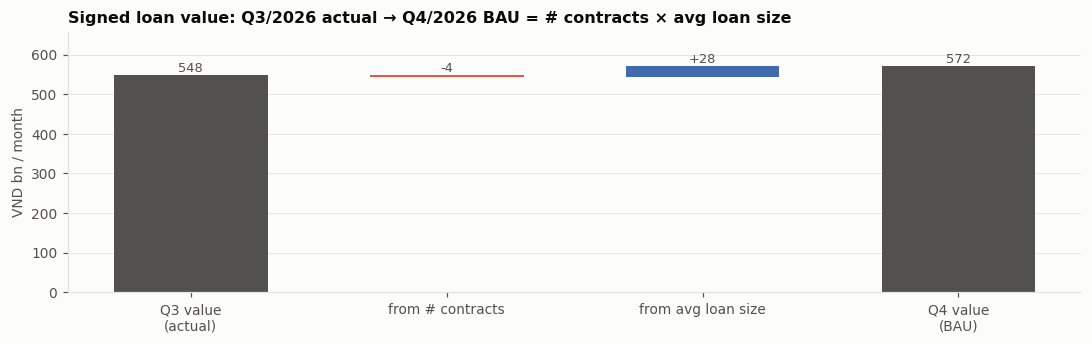

Giá trị khoản vay đã ký: Current Q3 548 tỷ/tháng → BAU Q4 572 tỷ/tháng (+4.3%): số HĐ -0.7%, khoản vay bình quân +5.1%. Nếu giữ nguyên khoản vay bình quân: 543 tỷ/tháng.


In [21]:
VAL = ok.pivot_table(index='skp_salesroom', columns='m', values='val', aggfunc='sum').reindex(index=shops.index, columns=MONTHS).fillna(0).where(OPEN, 0)
TK_K = 20
TK_METH = {'flat': 'Giữ nguyên', 'trend_half': 'Xu hướng giảm dần', 'trend_full': 'Xu hướng đầy đủ'}

def seg_ticket(q):
    # khoản vay bình quân của phân khúc trong quý q (CC tính giá trị 0)
    return VAL[QM[q]].sum(axis=1).groupby(shops.seg).sum() / Y[QM[q]].sum(axis=1).groupby(shops.seg).sum()

def ticket_fc(T, ids, method):
    m2 = QM[T] + QM[T - 1]
    V, N, sg = VAL.loc[ids, m2].sum(axis=1), Y.loc[ids, m2].sum(axis=1), shops.loc[ids, 'seg']
    tk = (V + TK_K * sg.map(V.groupby(sg).sum() / N.groupby(sg).sum())) / (N + TK_K)
    if method == 'flat':
        return tk
    g = ((seg_ticket(T) / seg_ticket(T - 2)) ** .5 - 1).clip(-.1, .1)              # tăng trưởng/quý, bình quân 2 quý
    f = (1 + .5 * g) if method == 'trend_half' else (1 + g) ** 1.5
    return tk * sg.map(f).fillna(1)

rows_tk = []
for T in FOLDS:
    d_, P_ = store[T]; ids = d_.index
    act_v = VAL.loc[ids, QM[T + 1]].sum(axis=1) / 3
    for mth, lab in TK_METH.items():
        tk = ticket_fc(T, ids, mth)
        v_ticket, v_bau = d_.y * tk, P_[CHOSEN] * tk
        rows_tk.append(dict(du_bao=QN(T + 1), cach=lab,
                            lech_khoan_vay=v_ticket.sum() / act_v.sum() - 1,
                            lech_gia_tri_BAU=v_bau.sum() / act_v.sum() - 1,
                            WAPE_gia_tri_BAU=(v_bau - act_v).abs().sum() / act_v.sum()))
rtk = pd.DataFrame(rows_tk)
print('Sai lệch tổng (dự báo ÷ thực tế − 1) theo từng mốc:')
display(rtk.pivot(index='cach', columns='du_bao', values=['lech_khoan_vay', 'lech_gia_tri_BAU']).reindex(TK_METH.values()).style.format('{:+.1%}'))
stk = rtk.groupby('cach').agg(lech_khoan_vay_TB=('lech_khoan_vay', lambda x: x.abs().mean()),
                              lech_gia_tri_TB=('lech_gia_tri_BAU', lambda x: x.abs().mean()),
                              WAPE_gia_tri=('WAPE_gia_tri_BAU', 'mean')).reindex(TK_METH.values())
print('Trung bình 3 mốc (|sai lệch|):'); display(stk.style.format('{:.1%}'))
best_tk = stk.lech_khoan_vay_TB.min()
TK_CHOSEN = next(k for k, v in TK_METH.items() if stk.loc[v, 'lech_khoan_vay_TB'] <= best_tk + .005)   # ngang nhau (±0,5 điểm %) → cách đơn giản hơn
print(f'→ Chọn: {TK_METH[TK_CHOSEN]}')

# áp dụng cho dự báo Q4/2026
d['ticket'] = ticket_fc(T_NOW, d.index, TK_CHOSEN)
d['ticket_flat'] = ticket_fc(T_NOW, d.index, 'flat')
d['cur_val'] = VAL.loc[d.index, QM[T_NOW]].sum(axis=1) / d.act_T.clip(lower=1)        # giá trị thực tế Q3, cùng cách tính với cur
for c in ['bau', 'bau_p10', 'bau_p90']:
    d[c + '_val'] = d[c] * d.ticket

# bảng cầu nối dễ trình bày: số HĐ × khoản vay bình quân = giá trị
def bridge_val(g):
    hd0, hd1, v0, v1 = g.cur.sum(), g.bau.sum(), g.cur_val.sum(), g.bau_val.sum()
    return pd.Series({'HĐ/tháng Q3': hd0, 'HĐ/tháng Q4 (BAU)': hd1, 'Δ HĐ': hd1 / hd0 - 1,
                      'Khoản vay BQ Q3 (tr)': v0 / hd0 / 1e6, 'Khoản vay BQ Q4 (tr)': v1 / hd1 / 1e6, 'Δ khoản vay BQ': (v1 / hd1) / (v0 / hd0) - 1,
                      'Giá trị Q3 (tỷ/tháng)': v0 / 1e9, 'Giá trị Q4 BAU (tỷ/tháng)': v1 / 1e9, 'Δ giá trị': v1 / v0 - 1})
bv = d.groupby('seg').apply(bridge_val)
bv.loc['Toàn mạng lưới'] = bridge_val(d)
display(bv.style.format({c: '{:+.1%}' for c in bv.columns if c.startswith('Δ')} |
                        {'HĐ/tháng Q3': '{:,.0f}', 'HĐ/tháng Q4 (BAU)': '{:,.0f}', 'Khoản vay BQ Q3 (tr)': '{:.1f}', 'Khoản vay BQ Q4 (tr)': '{:.1f}',
                         'Giá trị Q3 (tỷ/tháng)': '{:,.0f}', 'Giá trị Q4 BAU (tỷ/tháng)': '{:,.0f}'}))
t_ = bv.loc['Toàn mạng lưới']
flat_v = (d.bau * d.ticket_flat).sum()
fig, ax = plt.subplots(figsize=(10, 3.2))
steps = [('Q3 value\n(actual)', t_['Giá trị Q3 (tỷ/tháng)']),
         ('from # contracts', (t_['HĐ/tháng Q4 (BAU)'] - t_['HĐ/tháng Q3']) * t_['Khoản vay BQ Q3 (tr)'] / 1e3),
         ('from avg loan size', t_['HĐ/tháng Q4 (BAU)'] * (t_['Khoản vay BQ Q4 (tr)'] - t_['Khoản vay BQ Q3 (tr)']) / 1e3)]
run = 0
for i, (lab, v) in enumerate(steps):
    base = 0 if i == 0 else run
    ax.bar(i, v, bottom=base, color=TXT2 if i == 0 else (C1 if v >= 0 else C2), width=.6)
    ax.text(i, base + max(v, 0), f'{v:+,.0f}' if i else f'{v:,.0f}', ha='center', va='bottom', fontsize=8.5, color=TXT2)
    run = v if i == 0 else run + v
ax.bar(3, t_['Giá trị Q4 BAU (tỷ/tháng)'], color=TXT2, width=.6)
ax.text(3, t_['Giá trị Q4 BAU (tỷ/tháng)'], f"{t_['Giá trị Q4 BAU (tỷ/tháng)']:,.0f}", ha='center', va='bottom', fontsize=8.5, color=TXT2)
ax.set_xticks(range(4), [s[0] for s in steps] + ['Q4 value\n(BAU)']); ax.set_ylabel('VND bn / month'); ax.grid(axis='x', visible=False)
ax.set_ylim(0, max(run, t_['Giá trị Q3 (tỷ/tháng)']) * 1.15)
ax.set_title('Signed loan value: Q3/2026 actual → Q4/2026 BAU = # contracts × avg loan size')
plt.tight_layout(); plt.show()
print(f"Giá trị khoản vay đã ký: Current Q3 {t_['Giá trị Q3 (tỷ/tháng)']:,.0f} tỷ/tháng → BAU Q4 {t_['Giá trị Q4 BAU (tỷ/tháng)']:,.0f} tỷ/tháng "
      f"({t_['Δ giá trị']:+.1%}): số HĐ {t_['Δ HĐ']:+.1%}, khoản vay bình quân {t_['Δ khoản vay BQ']:+.1%}. "
      f"Nếu giữ nguyên khoản vay bình quân: {flat_v / 1e9:,.0f} tỷ/tháng.")

## Bước 5b · Mở hộp đen mô hình: mỗi yếu tố đóng góp bao nhiêu HĐ?

**Vấn đề:** M12 là trung bình của 3 mô hình (LightGBM, Random Forest, làm mượt luỹ thừa). Nó chỉ tốt hơn cách "giữ nguyên" khoảng 4% về sai số trung bình; điểm hơn chính là **không dự báo sai có hệ thống cho nhóm shop ít HĐ** (Bước 3). Nhưng người nghe sẽ hỏi: *mô hình dựa vào đâu?*

**Cách làm: giá trị Shapley theo nhóm yếu tố** (cùng nguyên lý với SHAP):
- Gom các đầu vào thành **7 nhóm yếu tố** mà người kinh doanh hiểu được.
- Với mỗi shop, đo xem khi "bật" từng nhóm yếu tố của shop đó lên (thay cho giá trị của một shop bình thường), dự báo thay đổi bao nhiêu, lấy trung bình trên mọi thứ tự bật. Đây là cách chia công bằng duy nhất thoả mãn: **các phần đóng góp cộng lại đúng bằng BAU**.
- Tính cho **cả M12** (gồm cả phần làm mượt luỹ thừa), đơn vị là **HĐ/tháng**, nên đọc trực tiếp được: "tháng gần nhất bán thấp làm BAU giảm 1,2 HĐ/tháng".
- Thư viện `shap` thông thường chỉ giải thích được từng mô hình cây riêng lẻ (và với LightGBM dạng Tweedie thì ra thang log), nên ở đây tính trực tiếp, chính xác trên 2⁷ = 128 tổ hợp nhóm.

| Nhóm yếu tố | Đầu vào của mô hình |
|---|---|
| Mức quý hiện tại | HĐ/tháng quý T |
| Tháng gần nhất | HĐ của tháng cuối quý T |
| Quý trước & xu hướng 6 tháng | HĐ/tháng quý T−1, độ dốc 6 tháng |
| Lịch sử theo tháng (làm mượt) | mức làm mượt luỹ thừa của chuỗi tháng (đầu vào của M6) |
| Số tháng mở trong quý | 1–3 tháng |
| Tuổi shop | nhóm tuổi 0–2 / 3–5 / 6–11 / 12+ tháng |
| Loại shop | phân khúc, loại đối tác, quy mô |

**Điểm xuất phát** = BAU trung bình của một shop "bình thường" (trung bình trên 40 shop nền chọn ngẫu nhiên). Tính trên 1.500 shop chọn ngẫu nhiên và 2 shop ví dụ ở trên.

Điểm xuất phát (BAU của shop "bình thường"): 3.20 HĐ/tháng · kiểm tra cộng dồn: sai tối đa 5.7e-14 HĐ


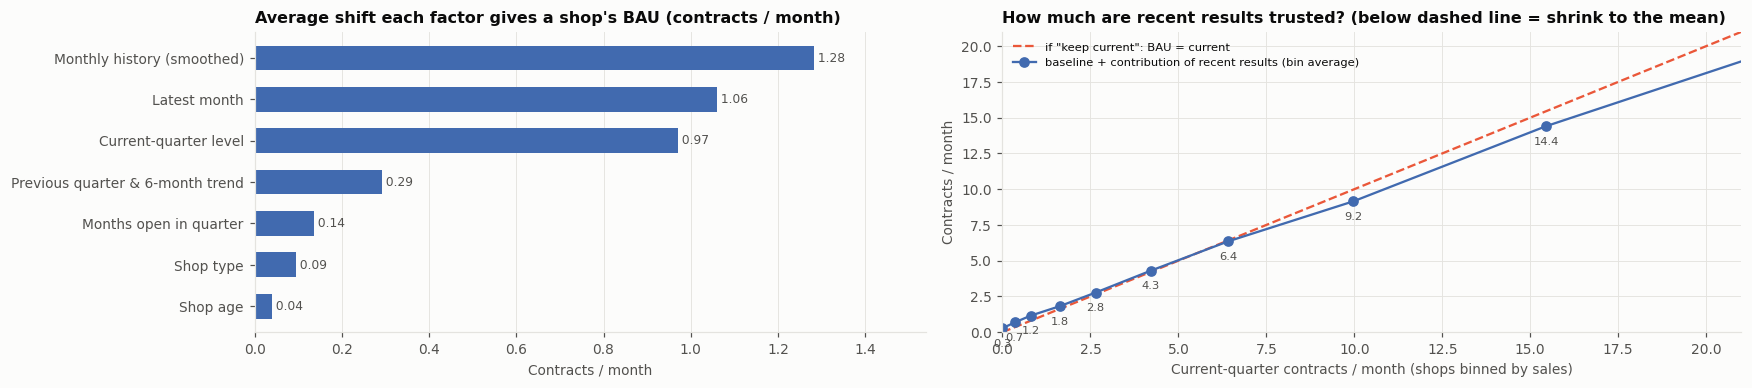

Kết quả bán gần đây (4 nhóm đầu) chiếm 93% tổng đóng góp; tuổi shop, loại shop và số tháng mở chỉ chiếm phần còn lại → BAU chủ yếu là kết quả gần đây được điều chỉnh.
Yếu tố làm shop khác shop "bình thường" nhiều nhất (1.500 shop ngẫu nhiên; "kéo xuống" phần lớn là shop bán ít hơn mức trung bình):


col_0,kéo BAU xuống,đẩy BAU lên,% shop
row_0,,,
Lịch sử theo tháng (làm mượt),881,161,69%
Mức quý hiện tại,78,127,14%
Tháng gần nhất,125,67,13%
Quý trước & xu hướng 6 tháng,32,14,3%
Số tháng mở trong quý,1,13,1%
Loại shop,1,0,0%


Đóng góp trung bình theo phân khúc (HĐ/tháng so với điểm xuất phát):


,Mức quý hiện tại,Tháng gần nhất,Quý trước & xu hướng 6 tháng,Lịch sử theo tháng (làm mượt),Số tháng mở trong quý,Tuổi shop,Loại shop
CD · Aldi,18.330,22.020,4.470,30.620,-0.110,-0.090,3.500
CD · Non-Aldi,-0.050,0.000,-0.050,-0.040,-0.070,-0.000,-0.020
NS · Aldi,-0.200,-0.180,-0.090,-0.250,-0.040,0.010,-0.090
TW · Non-Aldi,0.060,0.170,0.010,0.130,-0.030,0.010,0.050


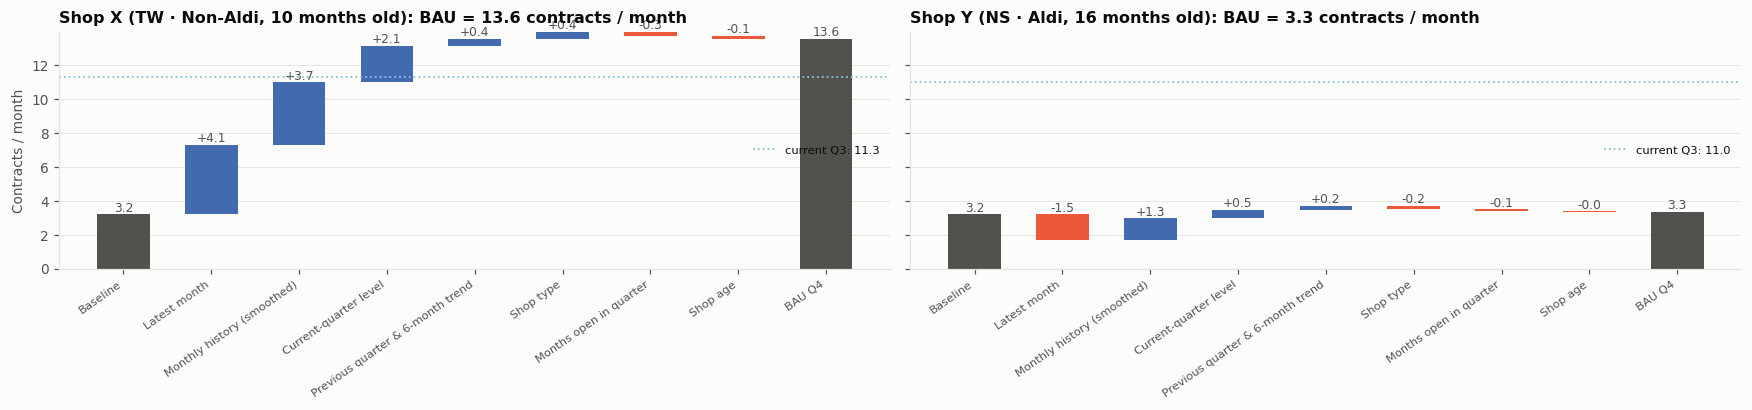

In [22]:
from itertools import combinations
from math import factorial

fit_x = fit_models(list(range(1, T_NOW)))                 # cùng mô hình đã dùng cho BAU Q4/2026
def f12(dd):
    X = design(dd, fit_x['cols'])
    return (fit_x['gb'].predict(X) + dd.ses.values + fit_x['rf'].predict(X)) / 3
assert np.allclose(f12(d_now), P_now.M12.values, atol=1e-6), 'f12 phải trùng với M12'

GROUPS = {'Mức quý hiện tại': ['cur'], 'Tháng gần nhất': ['last_m'], 'Quý trước & xu hướng 6 tháng': ['prev', 'slope'],
          'Lịch sử theo tháng (làm mượt)': ['ses'], 'Số tháng mở trong quý': ['act_T'], 'Tuổi shop': ['age_band'],
          'Loại shop': ['seg', 'seller_type', 'category']}
GN = list(GROUPS); KG = len(GN); GCOLS = sum(GROUPS.values(), [])
GROUPS_EN = {'Mức quý hiện tại': 'Current-quarter level', 'Tháng gần nhất': 'Latest month', 'Quý trước & xu hướng 6 tháng': 'Previous quarter & 6-month trend',
             'Lịch sử theo tháng (làm mượt)': 'Monthly history (smoothed)', 'Số tháng mở trong quý': 'Months open in quarter',
             'Tuổi shop': 'Shop age', 'Loại shop': 'Shop type'}

def group_shapley(E, B):
    # giá trị Shapley chính xác theo nhóm; v(S) = trung bình dự báo khi nhóm trong S lấy từ shop cần giải thích, nhóm còn lại từ shop nền
    E, B = E[GCOLS].reset_index(drop=True), B[GCOLS].reset_index(drop=True)
    ne, nb = len(E), len(B)
    Erep = E.loc[E.index.repeat(nb)].reset_index(drop=True); Brep = pd.concat([B] * ne, ignore_index=True)
    v = {}
    for r in range(KG + 1):
        for S in combinations(range(KG), r):
            Z = Brep.copy()
            for gi in S:
                Z[GROUPS[GN[gi]]] = Erep[GROUPS[GN[gi]]].values
            v[S] = f12(Z).reshape(ne, nb).mean(axis=1)
    phi = np.zeros((ne, KG))
    for gi in range(KG):
        for S, val in v.items():
            if gi in S: continue
            w = factorial(len(S)) * factorial(KG - len(S) - 1) / factorial(KG)
            phi[:, gi] += w * (v[tuple(sorted(S + (gi,)))] - val)
    return v[()][0], pd.DataFrame(phi, columns=GN)

rng_s = np.random.default_rng(7)
ex_ids = [X.name, Z.name]
E_ids = list(dict.fromkeys(ex_ids + list(rng_s.choice(d_now.index, 1500, replace=False))))
B_ids = rng_s.choice(d_now.index, 40, replace=False)
base_v, PHI = group_shapley(d_now.loc[E_ids], d_now.loc[B_ids])
PHI.index = E_ids
chk = (base_v + PHI.sum(axis=1) - f12(d_now.loc[E_ids])).abs().max()
print(f'Điểm xuất phát (BAU của shop "bình thường"): {base_v:.2f} HĐ/tháng · kiểm tra cộng dồn: sai tối đa {chk:.1e} HĐ')

imp = PHI.abs().mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(16, 3.6), gridspec_kw={'width_ratios': [1, 1.1]})
ax[0].barh([GROUPS_EN[g] for g in imp.index], imp.values, color=C1, height=.6)
for yi, v_ in enumerate(imp.values): ax[0].text(v_, yi, f' {v_:.2f}', va='center', fontsize=8, color=TXT2)
ax[0].set_xlabel('Contracts / month'); ax[0].grid(axis='y', visible=False); ax[0].set_xlim(0, imp.max() * 1.2)
ax[0].set_title('Average shift each factor gives a shop\'s BAU (contracts / month)')
sh_ = PHI.copy(); sh_['cur'] = d_now.loc[E_ids, 'cur'].values
recent = sh_[['Mức quý hiện tại', 'Tháng gần nhất', 'Quý trước & xu hướng 6 tháng', 'Lịch sử theo tháng (làm mượt)']].sum(axis=1)
CB = [-.01, 0, .5, 1, 2, 3, 5, 8, 12, 20, 40]
bb = pd.DataFrame({'cur': sh_.cur, 'bau_recent': base_v + recent}).assign(b=lambda x: pd.cut(x.cur, CB))
bm = bb[bb.cur <= 40].groupby('b', observed=True)[['cur', 'bau_recent']].mean()
ax[1].plot([0, 21], [0, 21], color=C2, lw=1.5, ls='--', label='if "keep current": BAU = current')
ax[1].plot(bm.cur, bm.bau_recent, color=C1, marker='o', label='baseline + contribution of recent results (bin average)')
for x_, y_ in zip(bm.cur, bm.bau_recent): ax[1].annotate(f'{y_:.1f}', (x_, y_), xytext=(0, -12), textcoords='offset points', ha='center', fontsize=7.5, color=TXT2)
ax[1].set_xlim(0, 21); ax[1].set_ylim(0, 21); ax[1].set_xlabel('Current-quarter contracts / month (shops binned by sales)'); ax[1].set_ylabel('Contracts / month')
ax[1].legend(loc='upper left', fontsize=7.5); ax[1].set_title('How much are recent results trusted? (below dashed line = shrink to the mean)')
plt.tight_layout(); plt.show()
RECENT = ['Mức quý hiện tại', 'Tháng gần nhất', 'Quý trước & xu hướng 6 tháng', 'Lịch sử theo tháng (làm mượt)']
print(f"Kết quả bán gần đây (4 nhóm đầu) chiếm {PHI[RECENT].abs().sum().sum() / PHI.abs().sum().sum():.0%} tổng đóng góp; "
      f"tuổi shop, loại shop và số tháng mở chỉ chiếm phần còn lại → BAU chủ yếu là kết quả gần đây được điều chỉnh.")

# yếu tố chính của từng shop (đóng góp lớn nhất về độ lớn)
top_ = PHI.drop(index=ex_ids, errors='ignore')
main_ = top_.abs().idxmax(axis=1)
sign_ = pd.Series([np.sign(top_.loc[i, c]) for i, c in main_.items()], index=main_.index)
tb_main = pd.crosstab(main_, sign_.map({1.0: 'đẩy BAU lên', -1.0: 'kéo BAU xuống', 0.0: 'không đổi'}))
tb_main['% shop'] = tb_main.sum(axis=1) / len(top_)
print('Yếu tố làm shop khác shop "bình thường" nhiều nhất (1.500 shop ngẫu nhiên; "kéo xuống" phần lớn là shop bán ít hơn mức trung bình):'); display(tb_main.sort_values('% shop', ascending=False).style.format({'% shop': '{:.0%}'}))
by_seg = PHI.drop(index=ex_ids, errors='ignore').groupby(d_now.loc[top_.index, 'seg'].values).mean()
print('Đóng góp trung bình theo phân khúc (HĐ/tháng so với điểm xuất phát):'); display(by_seg.round(2))

# thác nước cho 2 shop ví dụ
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), sharey=True)
for a_, sid, lab in zip(axes, ex_ids, ['Shop X', 'Shop Y']):
    ph = PHI.loc[sid]; order = ph.abs().sort_values(ascending=False).index
    run = base_v; xs_l = ['Baseline']
    a_.bar(0, base_v, color=TXT2, width=.6); a_.text(0, base_v, f'{base_v:.1f}', ha='center', va='bottom', fontsize=8, color=TXT2)
    for i, g_ in enumerate(order, 1):
        v_ = ph[g_]; a_.bar(i, v_, bottom=run, color=C1 if v_ >= 0 else C2, width=.6)
        a_.text(i, run + max(v_, 0), f'{v_:+.1f}', ha='center', va='bottom', fontsize=8, color=TXT2); run += v_; xs_l.append(GROUPS_EN[g_])
    a_.bar(len(order) + 1, run, color=TXT2, width=.6); a_.text(len(order) + 1, run, f'{run:.1f}', ha='center', va='bottom', fontsize=8, color=TXT2)
    a_.axhline(d_now.loc[sid, 'cur'], color=C3, lw=1.2, ls=':', label=f"current Q3: {d_now.loc[sid, 'cur']:.1f}")
    a_.set_xticks(range(len(xs_l) + 1), xs_l + ['BAU Q4'], rotation=35, ha='right', fontsize=7.5); a_.grid(axis='x', visible=False)
    a_.legend(loc='center right', fontsize=7.5); a_.set_title(f"{lab} ({d_now.loc[sid, 'seg']}, {d_now.loc[sid, 'age']} months old): BAU = {run:.1f} contracts / month")
axes[0].set_ylabel('Contracts / month'); plt.tight_layout(); plt.show()

**Cách đọc:**
- **Biểu đồ trái:** yếu tố nào mô hình dựa vào nhiều nhất. Nếu các nhóm "kết quả gần đây" đứng đầu và "loại shop", "tuổi shop" nhỏ, nghĩa là BAU chủ yếu là **kết quả gần đây được điều chỉnh**, không phải mô hình tự "nghĩ ra" con số.
- **Biểu đồ phải:** nếu mô hình chỉ "giữ nguyên", đường xanh sẽ trùng đường cam. Đường xanh nằm **dưới** đường cam ở shop bán nhiều và **trên** ở shop bán ít: mô hình **co về mức chung**, đúng với bằng chứng ở Bước 1b (đà tăng/giảm chỉ giữ khoảng 75–80%). Đây là phần M12 làm tốt hơn "giữ nguyên".
- **Thác nước 2 shop:** cùng mức bán hiện tại nhưng BAU khác nhau, và thấy được **khác vì yếu tố nào** (ví dụ tháng gần nhất = 0 kéo BAU xuống).
- Giá trị Shapley giải thích **mô hình dựa vào đâu**, không chứng minh quan hệ nhân quả: "tuổi shop đóng góp +0,3" nghĩa là mô hình dự báo cao hơn cho shop ở tuổi đó, không có nghĩa là chờ thêm tháng sẽ tự bán thêm.

## Bước 5c · Đọc BAU theo yếu tố kinh doanh: hồ sơ × chuyển đổi × khoản vay

Mô hình chọn cho con số BAU tốt nhất, nhưng Ban quản lý cần biết **BAU thay đổi vì yếu tố nào**. Mỗi shop được tách:

**BAU − Current = (phần do hồ sơ) + (phần do chuyển đổi) + (điều chỉnh khác của mô hình)**

| Thành phần | Cách tính | Ý nghĩa |
|---|---|---|
| **Do hồ sơ** | (hồ sơ/tháng dự báo − hồ sơ/tháng hiện tại) × tỷ lệ chuyển đổi hiện tại | nhu cầu đầu vào tăng hay giảm |
| **Do chuyển đổi** | hồ sơ dự báo × (tỷ lệ chuyển đổi dự kiến − tỷ lệ hiện tại) | tỷ lệ hiện tại co về mức 2 quý gần nhất và phân khúc |
| ↳ do **tỷ lệ bị từ chối** | − hồ sơ dự báo × (tỷ lệ từ chối dự kiến − hiện tại) | chất lượng khách nộp hồ sơ, chính sách duyệt |
| ↳ do **tỷ lệ huỷ** | − hồ sơ dự báo × (tỷ lệ huỷ dự kiến − hiện tại) | khả năng chốt của shop sau khi hồ sơ được xử lý |
| ↳ còn lại | phần chuyển đổi còn lại (hồ sơ đang xử lý, làm tròn) | nhỏ |
| **Điều chỉnh khác** | BAU (mô hình chọn) − BAU theo yếu tố (D2) | tuổi shop, rủi ro ngừng hoạt động, hồi về mức chung… mà công thức hồ sơ × chuyển đổi chưa bắt được |

- Hồ sơ dự báo lấy từ mô hình hồ sơ của D2. Tỷ lệ chuyển đổi = HĐ ký ÷ hồ sơ.
- Giá trị khoản vay = HĐ × khoản vay bình quân dự báo (Bước 5a).
- **Chất lượng dự kiến** = HĐ × tỷ lệ trễ kỳ đầu của shop. Tỷ lệ này tính trên HĐ ký 10/2025–06/2026 (đã đến kỳ trả đầu tiên) và co về phân khúc.

Tỷ lệ bị từ chối: hiện tại 20.6% → dự kiến 22.1% · tỷ lệ huỷ: hiện tại 7.8% → dự kiến 7.5%
Hồ sơ/tháng: hiện tại 55,025 → dự báo 54,276 · tỷ lệ chuyển đổi: hiện tại 71.6% → dự kiến 70.3%


,HĐ trong quý
Current (nhịp Q3 × 3),"118,177.000"
Do hồ sơ,-430.000
Do từ chối,"-3,543.000"
Do tỷ lệ huỷ,331.000
Chuyển đổi khác,-0.000
Điều chỉnh khác,"2,771.000"
BAU Q4,"117,306.000"


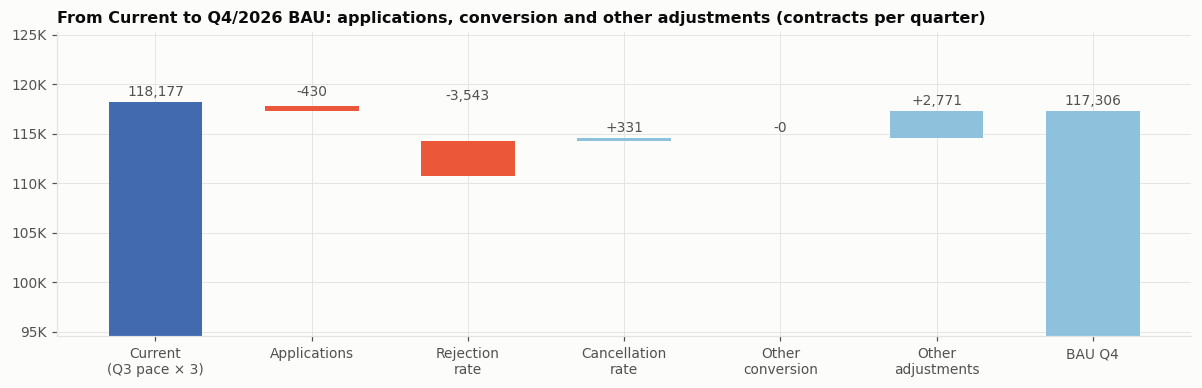

Theo phân khúc (HĐ trong quý, giá trị tỷ đồng):


,shop,current_q,do_ho_so,do_tu_choi,do_huy,chuyen_doi_con_lai,khac,bau_q,gia_tri_ty,tre_ky_dau
seg,,,,,,,,,,
CD · Non-Aldi,6106,"57,645.000",-776.000,"-2,722.000",256.000,-0.000,"3,222.000","57,625.000",723.000,"5,438.000"
NS · Aldi,3480,"28,823.000","-2,126.000",-749.000,132.000,-0.000,"1,360.000","27,441.000",407.000,"3,176.000"
TW · Non-Aldi,2275,"22,637.000",845.000,-86.000,-130.000,-0.000,-199.000,"23,067.000",499.000,"2,060.000"
CD · Aldi,61,"9,072.000","1,626.000",14.000,73.000,0.000,"-1,612.000","9,173.000",86.000,787.000


Yếu tố chính khiến BAU khác Current, theo số shop:


,shop
yeu_to_chinh,
Hồ sơ,7263
Ổn định,2296
Tỷ lệ bị từ chối,1371
Tỷ lệ huỷ,540
"Khác (tuổi, rủi ro đóng, hồi về mức chung)",452


In [23]:
d['apps_fc'] = P_now.x_apps_fc; d['conv'] = P_now.x_conv
d['conv_cur'] = (d.cur / d.apps_cur).where(d.apps_cur > 0).fillna(d.conv)
d['bau_driver'] = P_now.D2
d['dl_apps'] = (d.apps_fc - d.apps_cur) * d.conv_cur
d['dl_conv'] = d.apps_fc * (d.conv - d.conv_cur)
d['dl_khac'] = d.bau - d.cur - d.dl_apps - d.dl_conv

# tách chuyển đổi: tỷ lệ bị từ chối và tỷ lệ huỷ (trên hồ sơ), cùng cách co về phân khúc như tỷ lệ chuyển đổi
rc_ = con.sql(f'''SELECT skp_salesroom, date_trunc('month', date_apply)::DATE m,
                         count(*) FILTER (WHERE name_status = 'Rejected') rej, count(*) FILTER (WHERE name_status = 'Cancelled') can
                  FROM {rd('contract')} GROUP BY 1, 2''').df()
mQ = QM[T_NOW]; m2 = QM[T_NOW - 1] + QM[T_NOW]
for c_ in ['rej', 'can']:
    M_ = rc_.pivot_table(index='skp_salesroom', columns='m', values=c_, aggfunc='sum').reindex(index=shops.index, columns=MONTHS).fillna(0)
    # mức phân khúc: cùng các mốc huấn luyện như tỷ lệ chuyển đổi của mô hình (mốc 1 … T_NOW−1)
    num_ = sum(M_.loc[SNAP[t].index, QM[t - 1] + QM[t]].sum(axis=1).groupby(SNAP[t].seg).sum() for t in range(1, T_NOW))
    den_ = sum(APPS.loc[SNAP[t].index, QM[t - 1] + QM[t]].sum(axis=1).groupby(SNAP[t].seg).sum() for t in range(1, T_NOW))
    seg_r = num_ / den_
    M_ = M_.loc[d.index]
    a_q = APPS.loc[d.index, mQ].sum(axis=1); a_2 = APPS.loc[d.index, m2].sum(axis=1)
    n_2 = M_[m2].sum(axis=1)
    d[c_ + '_hat'] = (n_2 + 20 * d.seg.map(seg_r)) / (a_2 + 20)
    d[c_ + '_cur'] = (M_[mQ].sum(axis=1) / a_q).where(a_q > 0).fillna(d[c_ + '_hat'])
d['dl_tuchoi'] = -d.apps_fc * (d.rej_hat - d.rej_cur)
d['dl_huy'] = -d.apps_fc * (d.can_hat - d.can_cur)
d['dl_conv_con_lai'] = d.dl_conv - d.dl_tuchoi - d.dl_huy
comp_ = d[['dl_apps', 'dl_tuchoi', 'dl_huy']].assign(dl_k=d.dl_khac + d.dl_conv_con_lai)
d['yeu_to_chinh'] = comp_.abs().idxmax(axis=1).map({'dl_apps': 'Hồ sơ', 'dl_tuchoi': 'Tỷ lệ bị từ chối', 'dl_huy': 'Tỷ lệ huỷ',
                                                      'dl_k': 'Khác (tuổi, rủi ro đóng, hồi về mức chung)'})
d.loc[(d.bau - d.cur).abs() <= .1 * d.cur.clip(lower=.3), 'yeu_to_chinh'] = 'Ổn định'

# chất lượng: tỷ lệ trễ kỳ đầu theo shop (HĐ đã đến kỳ trả đầu tiên)
fpd_ = con.sql(f'''SELECT skp_salesroom, count(*) n_f, sum(flag_dpd_1pd) fpd FROM {rd('contract')}
                   WHERE is_signed AND name_status <> 'Cancelled' AND date_sign >= DATE '2025-10-01' AND date_sign < DATE '2026-07-01'
                   GROUP BY 1''').df().set_index('skp_salesroom')
d = d.join(fpd_); d[['n_f', 'fpd']] = d[['n_f', 'fpd']].fillna(0)
segf = d.groupby('seg').fpd.sum() / d.groupby('seg').n_f.sum()
d['fpd_rate'] = (d.fpd + 20 * d.seg.map(segf)) / (d.n_f + 20)
d['bau_q'] = d.bau * 3; d['bau_q_p10'] = d.bau_p10 * 3; d['bau_q_p90'] = d.bau_p90 * 3
d['bau_q_val'] = d.bau_val * 3; d['bau_q_fpd'] = d.bau_q * d.fpd_rate

# bảng toàn mạng lưới, đơn vị: HĐ trong quý
net_ = pd.Series({'Current (nhịp Q3 × 3)': d.cur.sum() * 3, 'Do hồ sơ': d.dl_apps.sum() * 3, 'Do từ chối': d.dl_tuchoi.sum() * 3,
                  'Do tỷ lệ huỷ': d.dl_huy.sum() * 3, 'Chuyển đổi khác': d.dl_conv_con_lai.sum() * 3,
                  'Điều chỉnh khác': d.dl_khac.sum() * 3, 'BAU Q4': d.bau.sum() * 3})
a_w = d.apps_cur.sum()
print(f"Tỷ lệ bị từ chối: hiện tại {(d.rej_cur * d.apps_cur).sum() / a_w:.1%} → dự kiến {(d.rej_hat * d.apps_fc).sum() / d.apps_fc.sum():.1%} · "
      f"tỷ lệ huỷ: hiện tại {(d.can_cur * d.apps_cur).sum() / a_w:.1%} → dự kiến {(d.can_hat * d.apps_fc).sum() / d.apps_fc.sum():.1%}")
print(f"Hồ sơ/tháng: hiện tại {d.apps_cur.sum():,.0f} → dự báo {d.apps_fc.sum():,.0f} · tỷ lệ chuyển đổi: hiện tại "
      f"{d.cur.sum() / d.apps_cur.sum():.1%} → dự kiến {(d.apps_fc * d.conv).sum() / d.apps_fc.sum():.1%}")
display(net_.round(0).to_frame('HĐ trong quý'))

fig, ax = plt.subplots(figsize=(11, 3.6))
lv = 0; labs = ['Current\n(Q3 pace × 3)', 'Applications', 'Rejection\nrate', 'Cancellation\nrate', 'Other\nconversion', 'Other\nadjustments', 'BAU Q4']
for i, (k, v) in enumerate(net_.items()):
    if i in (0, len(net_) - 1):
        ax.bar(i, v, color=C1 if i == 0 else C3, width=.6); top = lv = v; txt = f'{v:,.0f}'
    else:
        ax.bar(i, v, bottom=lv if v >= 0 else lv + v, color=C3 if v >= 0 else C2, width=.6); top = max(lv, lv + v); lv += v; txt = f'{v:+,.0f}'
    ax.text(i, top * 1.003, txt, ha='center', va='bottom', fontsize=9, color=TXT2)
ax.set_xticks(range(len(labs)), labs); ax.set_ylim(net_.iloc[0] * .8, max(net_.iloc[0], net_.iloc[-1]) * 1.06)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x / 1000:,.0f}K'))
ax.set_title('From Current to Q4/2026 BAU: applications, conversion and other adjustments (contracts per quarter)'); plt.tight_layout(); plt.show()

# theo phân khúc
tb_ = d.groupby('seg').agg(shop=('bau', 'size'), current_q=('cur', 'sum'), do_ho_so=('dl_apps', 'sum'), do_tu_choi=('dl_tuchoi', 'sum'),
                           do_huy=('dl_huy', 'sum'), chuyen_doi_con_lai=('dl_conv_con_lai', 'sum'), khac=('dl_khac', 'sum'), bau_q=('bau', 'sum'), gia_tri_ty=('bau_q_val', 'sum'), tre_ky_dau=('bau_q_fpd', 'sum'))
for c_ in ['current_q', 'do_ho_so', 'do_tu_choi', 'do_huy', 'chuyen_doi_con_lai', 'khac', 'bau_q']: tb_[c_] *= 3
tb_['gia_tri_ty'] /= 1e9
print('Theo phân khúc (HĐ trong quý, giá trị tỷ đồng):'); display(tb_.sort_values('bau_q', ascending=False).round(0))
print('Yếu tố chính khiến BAU khác Current, theo số shop:'); display(d.yeu_to_chinh.value_counts().to_frame('shop'))

In [24]:
# câu trả lời cho từng shop
def cau_bau(r):
    s_ = (f"Quý tới shop {r.name} dự kiến đạt {r.bau_q:,.0f} HĐ (khoảng {r.bau_q_p10:,.0f}–{r.bau_q_p90:,.0f}), "
          f"giá trị khoản vay khoảng {r.bau_q_val / 1e6:,.0f} triệu, nếu duy trì cách vận hành hiện tại. ")
    s_ += (f"So với nhịp quý này ({r.cur * 3:,.0f} HĐ): hồ sơ {r.apps_cur * 3:,.0f} → {r.apps_fc * 3:,.0f} ({r.dl_apps * 3:+,.0f} HĐ), "
           f"tỷ lệ chuyển đổi {r.conv_cur:.0%} → {r.conv:.0%} ({r.dl_conv * 3:+,.0f} HĐ, trong đó từ chối {r.rej_cur:.0%} → {r.rej_hat:.0%}: "
           f"{r.dl_tuchoi * 3:+,.0f}, huỷ {r.can_cur:.0%} → {r.can_hat:.0%}: {r.dl_huy * 3:+,.0f}), điều chỉnh khác {r.dl_khac * 3:+,.0f} HĐ. ")
    s_ += f"Lý do chính: {r.ly_do.lower()}. Dự kiến khoảng {r.bau_q_fpd:,.1f} HĐ trễ kỳ đầu ({r.fpd_rate:.0%})."
    return s_
d['dien_giai'] = d.apply(cau_bau, axis=1)
ex_ = []
for k_ in ['Hồ sơ', 'Tỷ lệ bị từ chối', 'Tỷ lệ huỷ', 'Khác (tuổi, rủi ro đóng, hồi về mức chung)', 'Ổn định']:
    g_ = d[(d.yeu_to_chinh == k_) & (d.cur >= 3)]
    if len(g_): ex_.append((k_, g_.loc[(g_.bau - g_.cur).abs().idxmax() if k_ != 'Ổn định' else g_.cur.idxmax(), 'dien_giai']))
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(ex_, columns=['Yếu tố chính', 'Diễn giải']).style.hide(axis='index').set_properties(**{'text-align': 'left'}))

Yếu tố chính,Diễn giải
Hồ sơ,"Quý tới shop 118655027 dự kiến đạt 782 HĐ (khoảng 749–809), giá trị khoản vay khoảng 7,707 triệu, nếu duy trì cách vận hành hiện tại. So với nhịp quý này (1,053 HĐ): hồ sơ 1,682 → 1,288 (-247 HĐ), tỷ lệ chuyển đổi 63% → 66% (+45 HĐ, trong đó từ chối 24% → 22%: +24, huỷ 13% → 12%: +22), điều chỉnh khác -70 HĐ. Lý do chính: hồi về mức chung (đang rất cao). Dự kiến khoảng 51.6 HĐ trễ kỳ đầu (7%)."
Tỷ lệ bị từ chối,"Quý tới shop 115164486 dự kiến đạt 89 HĐ (khoảng 56–116), giá trị khoản vay khoảng 1,303 triệu, nếu duy trì cách vận hành hiện tại. So với nhịp quý này (107 HĐ): hồ sơ 125 → 118 (-6 HĐ), tỷ lệ chuyển đổi 86% → 80% (-7 HĐ, trong đó từ chối 8% → 14%: -8, huỷ 6% → 6%: +0), điều chỉnh khác -5 HĐ. Lý do chính: hồi về mức chung (đang rất cao). Dự kiến khoảng 4.9 HĐ trễ kỳ đầu (5%)."
Tỷ lệ huỷ,"Quý tới shop 102729648 dự kiến đạt 56 HĐ (khoảng 23–82), giá trị khoản vay khoảng 1,349 triệu, nếu duy trì cách vận hành hiện tại. So với nhịp quý này (41 HĐ): hồ sơ 69 → 73 (+2 HĐ), tỷ lệ chuyển đổi 59% → 68% (+6 HĐ, trong đó từ chối 20% → 23%: -2, huỷ 20% → 9%: +8), điều chỉnh khác +6 HĐ. Lý do chính: biến động khác. Dự kiến khoảng 6.7 HĐ trễ kỳ đầu (12%)."
"Khác (tuổi, rủi ro đóng, hồi về mức chung)","Quý tới shop 126511988 dự kiến đạt 740 HĐ (khoảng 706–785), giá trị khoản vay khoảng 7,485 triệu, nếu duy trì cách vận hành hiện tại. So với nhịp quý này (926 HĐ): hồ sơ 1,426 → 1,344 (-54 HĐ), tỷ lệ chuyển đổi 65% → 65% (-0 HĐ, trong đó từ chối 22% → 22%: -1, huỷ 13% → 13%: +1), điều chỉnh khác -131 HĐ. Lý do chính: hồi về mức chung (đang rất cao). Dự kiến khoảng 65.0 HĐ trễ kỳ đầu (9%)."
Ổn định,"Quý tới shop 101003268 dự kiến đạt 599 HĐ (khoảng 566–625), giá trị khoản vay khoảng 5,735 triệu, nếu duy trì cách vận hành hiện tại. So với nhịp quý này (635 HĐ): hồ sơ 857 → 1,005 (+109 HĐ), tỷ lệ chuyển đổi 74% → 74% (+3 HĐ, trong đó từ chối 19% → 18%: +11, huỷ 7% → 7%: -7), điều chỉnh khác -149 HĐ. Lý do chính: ổn định. Dự kiến khoảng 47.2 HĐ trễ kỳ đầu (8%)."


## Trả lời: Business-as-Usual

In [25]:
keep = ['model', 'category', 'line', 'seller_type', 'area', 'seg', 'age', 'act_T', 'prev2', 'prev', 'cur', 'quy_dao', 'surv_frac',
        'bau', 'bau_p10', 'bau_p90', 'bau6', 'bau6_p10', 'bau6_p90', 'ly_do', 'ticket', 'cur_val', 'bau_val', 'bau_p10_val', 'bau_p90_val', 'bau_q', 'bau_q_p10', 'bau_q_p90', 'bau_q_val', 'apps_cur', 'apps_fc', 'conv_cur', 'conv', 'dl_apps', 'dl_conv', 'rej_cur', 'rej_hat', 'can_cur', 'can_hat', 'dl_tuchoi', 'dl_huy', 'dl_conv_con_lai', 'dl_khac', 'yeu_to_chinh', 'fpd_rate', 'bau_q_fpd', 'dien_giai'] + ['pred_' + m for m in MODELS]
try:
    d[keep].to_csv(OUT / 'bau_2026Q4.csv', encoding='utf-8-sig')
except PermissionError:
    d[keep].to_csv(OUT / 'bau_2026Q4_new.csv', encoding='utf-8-sig')
lines = [
 ('Định nghĩa', 'HĐ thành công bình quân/tháng trong Q4/2026 của các shop đang mở cuối Q3, nếu không có biện pháp cải thiện mới; '
                'đã gồm khả năng shop trưởng thành và ngừng hoạt động.'),
 ('Phương pháp', f"{NAMES[CHOSEN]}: chọn qua backtest 3 mốc (MAE TB {s_.loc[CHOSEN, 'MAE']:.2f} HĐ/tháng/shop; "
                 f"|sai lệch tổng| TB {s_.loc[CHOSEN, 'bias']:.1%}). Đạt cả 2 tiêu chí: sai số thấp và không lệch quá 20% ở nhóm shop nào."),
 ('BAU toàn mạng lưới', f"{net['diem']:,.0f} HĐ/tháng (P10–P90: {net['P10']:,.0f}–{net['P90']:,.0f}) so với Current {d.cur.sum():,.0f}; "
                        f"giá trị khoản vay {d.bau_val.sum() / 1e9:,.0f} tỷ/tháng."),
 ('BAU theo quý', f"{d.bau_q.sum():,.0f} HĐ ký trong Q4/2026 (P10–P90: {net['P10'] * 3:,.0f}–{net['P90'] * 3:,.0f}); "
                  f"giá trị khoản vay {d.bau_q_val.sum() / 1e9:,.0f} tỷ; dự kiến {d.bau_q_fpd.sum():,.0f} HĐ trễ kỳ đầu ({d.bau_q_fpd.sum() / d.bau_q.sum():.1%})."),
 ('Theo yếu tố kinh doanh', f"So với nhịp Q3 ({d.cur.sum() * 3:,.0f} HĐ): do hồ sơ {d.dl_apps.sum() * 3:+,.0f}, do chuyển đổi {d.dl_conv.sum() * 3:+,.0f} "
                            f"(từ chối {d.dl_tuchoi.sum() * 3:+,.0f}, huỷ {d.dl_huy.sum() * 3:+,.0f}), "
                            f"điều chỉnh khác {d.dl_khac.sum() * 3:+,.0f}. Mô hình theo yếu tố D2: MAE {s_.loc['D2', 'MAE']:.2f}, "
                            f"lệch nhóm tối đa {s_.loc['D2', 'lech_nhom_max']:.0%}."),
 ('Kịch bản (1 quý)', '; '.join(f"{k}: {v.sum():,.0f}" for k, v in SCN.items())),
 ('Góc nhìn 6 tháng', f"Bình quân Q4/2026–Q1/2027: {net6['diem']:,.0f} HĐ/tháng (P10–P90: {net6['P10']:,.0f}–{net6['P90']:,.0f}); "
                      f"backtest 2 mốc, bao phủ ≈ {pd.DataFrame(cov6).bao_phu.mean():.0%}; dùng để so với Attainable. "
                      f"Kịch bản có mùa vụ Q4 + Tết: {seas6.sum():,.0f}."),
 ('Từng shop', f"Có BAU điểm + khoảng P10–P90 (bao phủ backtest ≈ {pd.DataFrame(cov).bao_phu.mean():.0%}), quỹ đạo và lý do chính; "
               f"{d.ly_do.str.startswith('Rủi ro').sum():,} shop có rủi ro ngừng hoạt động cao, {(d.quy_dao == 'Giảm').sum():,} shop đang giảm."),
 ('Hai shop cùng doanh số', f"Shop X và Y cùng ~{cb_:.0f} HĐ/tháng ở Q3 nhưng BAU Q4 là {X.bau:.1f} và {Z.bau:.1f}: "
                            f"X – {X.ly_do}; Y – {Z.ly_do}."),
 ('Giới hạn', 'Chỉ 3 mốc backtest (1 quý) và 2 mốc (6 tháng); không dự báo xa hơn 6 tháng; mùa vụ chỉ 1 năm; khoảng mạng lưới dựa trên độ lệch của 3 mốc nên còn thô; '
              'dữ liệu không có kế hoạch khuyến mãi hay thay đổi chính sách sắp tới.'),
]
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(lines, columns=['Khía cạnh', 'Trả lời']).style.hide(axis='index').set_properties(**{'text-align': 'left'}))

Khía cạnh,Trả lời
Định nghĩa,"HĐ thành công bình quân/tháng trong Q4/2026 của các shop đang mở cuối Q3, nếu không có biện pháp cải thiện mới; đã gồm khả năng shop trưởng thành và ngừng hoạt động."
Phương pháp,M12 Kết hợp M5 + M6 + M8: chọn qua backtest 3 mốc (MAE TB 1.69 HĐ/tháng/shop; |sai lệch tổng| TB 5.8%). Đạt cả 2 tiêu chí: sai số thấp và không lệch quá 20% ở nhóm shop nào.
BAU toàn mạng lưới,"39,102 HĐ/tháng (P10–P90: 36,262–41,945) so với Current 39,392; giá trị khoản vay 572 tỷ/tháng."
BAU theo quý,"117,306 HĐ ký trong Q4/2026 (P10–P90: 108,787–125,834); giá trị khoản vay 1,715 tỷ; dự kiến 11,460 HĐ trễ kỳ đầu (9.8%)."
Theo yếu tố kinh doanh,"So với nhịp Q3 (118,177 HĐ): do hồ sơ -430, do chuyển đổi -3,212 (từ chối -3,543, huỷ +331), điều chỉnh khác +2,771. Mô hình theo yếu tố D2: MAE 1.74, lệch nhóm tối đa 15%."
Kịch bản (1 quý),"Cơ sở: 39,102; Có mùa vụ (Q4/Q3 2025): 37,016; Xu hướng tiếp diễn (M2): 41,815; Đóng cửa nhiều hơn (× 1,5): 38,407; Đóng cửa ít hơn (× 0,5): 39,810"
Góc nhìn 6 tháng,"Bình quân Q4/2026–Q1/2027: 37,517 HĐ/tháng (P10–P90: 36,508–38,546); backtest 2 mốc, bao phủ ≈ 80%; dùng để so với Attainable. Kịch bản có mùa vụ Q4 + Tết: 35,843."
Từng shop,"Có BAU điểm + khoảng P10–P90 (bao phủ backtest ≈ 80%), quỹ đạo và lý do chính; 340 shop có rủi ro ngừng hoạt động cao, 1,389 shop đang giảm."
Hai shop cùng doanh số,Shop X và Y cùng ~11 HĐ/tháng ở Q3 nhưng BAU Q4 là 13.6 và 3.3: X – Xu hướng tăng; Y – Tháng gần nhất không phát sinh HĐ.
Giới hạn,Chỉ 3 mốc backtest (1 quý) và 2 mốc (6 tháng); không dự báo xa hơn 6 tháng; mùa vụ chỉ 1 năm; khoảng mạng lưới dựa trên độ lệch của 3 mốc nên còn thô; dữ liệu không có kế hoạch khuyến mãi hay thay đổi chính sách sắp tới.
